### Дипломная работа

**Тема:** «Интеллектуальная система управления портфелем акций S&P 500 с использованием машинного обучения»

**Автор:** Сизиков Константин Александрович

**Курс:** Машинное обучение для финансового анализа

**Цель работы.** Разработать систему управления портфелем акций S&P 500, которая прогнозирует доходность акций
несколькими моделями машинного обучения, объединяет прогнозы в консенсус и распределяет капитал по Марковицу с учётом
ожидаемой доходности, волатильности, корреляций и транзакционных издержек, — и проверить, повышает ли она
риск-скорректированную доходность портфеля по сравнению с классическими стратегиями без прогнозов: Equal Weight,
Minimum Variance и Mean-Variance на исторических оценках.

**Как устроена система.** Раз в месяц, по закрытию последнего торгового дня, для каждой акции индекса считаются
технические, статистические и межсекторные признаки. По ним несколько моделей прогнозируют
относительную доходность акции на следующий месяц: поиск похожих исторических состояний (DTW), CatBoost, нейросеть
LSTM. Прогнозы объединяются в консенсус: основной, заданный заранее, — среднее CatBoost и LSTM; ансамбль всех трёх
моделей строится с равными, статическими, адаптивными весами или весами RL-агента, и эти способы сравниваются. Консенсус
подаётся в оптимизатор Марковица с ограничениями (только лонг, акция ≤ 10%, сектор ≤ 30%, без плеча) и штрафом за
оборот; сделки — по цене открытия следующего дня, издержки 0.10%. Отдельно прогнозируется волатильность акций для
оценки риска, а вклад новостей с оценкой тональности языковыми моделями проверяется на прогнозе: новостные данные
заканчиваются в январе 2024 г., поэтому в портфели они не входят.

**Как проверяем.** Все параметры выбираются только на dev 2009–2021; проверка — на валидации 2022–2023 и в
walk-forward 01.2024 — 09.2026 с переобучением моделей раз в квартал. Портфель на каждую дату строится только из
акций, входивших в индекс **на дату решения** (исторический состав индекса), — иначе бэктест завышается ошибкой
выжившего. Разницы стратегий проверяются бутстрепом и t-статистиками с поправкой на число сравнений. Отсутствие
улучшения — допустимый результат, если эксперимент поставлен корректно.

**Гипотезы.** Основная гипотеза задания — «ансамбль ML-моделей повышает риск-скорректированную доходность портфеля по
сравнению с классическими стратегиями» — разбита на H1 (прогноз содержит информацию) и H2 (прогноз улучшает портфель).
H5–H10 — шесть дополнительных гипотез задания. H3 и H4 добавлены в работе: прогноз риска и контроль построения
вселенной.

| № | гипотеза | как проверяем |
|---|---|---|
| H1 | ML-прогноз относительной доходности акции на месяц содержит информацию | ранговая корреляция прогноза с фактом (IC) по месяцам, t-статистика Ньюи–Уэста, спред крайних децилей, IC внутри секторов |
| H2 | прогноз доходности улучшает портфель | Марковиц на прогнозе против Minimum Variance с тем же γ; наклон равных весов по прогнозу против Equal Weight: Sharpe, бутстреп разницы, перестановочный тест |
| H3 | ML-прогноз волатильности точнее исторической оценки и снижает риск портфеля | QLIKE, тест Диболда–Мариано на общих строках; Minimum Variance и обратная волатильность на прогнозе против исторической оценки |
| H4 | (контроль) построение вселенной существенно меняет результаты бэктеста | те же портфели на нынешних членах индекса и на составе, известном на дату решения; сравнение с реальными фондами |
| H5 | поиск похожих исторических состояний (DTW) даёт информативный прогноз доходности | IC модели DTW; тот же поиск с евклидовым расстоянием (kNN) — нужна ли «деформация времени» |
| H6 | ансамбль моделей устойчивее отдельных моделей | разброс месячного IC, худший из 17 блоков, парные разницы IC ансамбля трёх моделей и каждой модели |
| H7 | межсекторные признаки улучшают прогноз | абляция: CatBoost с секторными признаками и без них, парная разница IC и IC внутри секторов |
| H8 | тональность новостей (FinBERT, LLM) улучшает прогноз | CatBoost с новостными признаками против без них, против «только числа новостей» и против 10 плацебо с перемешанной тональностью; dev и валидация — новости заканчиваются в 01.2024 |
| H9 | адаптивные веса моделей по их недавней точности лучше фиксированных | IC и портфель на ансамбле с адаптивными весами против равных и статических |
| H10 | RL-агент, управляющий весами моделей, лучше простых правил | IC и портфель на ансамбле с весами агента PPO против адаптивных и равных |

**Соответствие постановке задания:**

| элемент задания | где в работе |
|---|---|
| акции S&P 500; 20–30 акций разных секторов | основная вселенная — весь индекс на дату решения (2.3); система на 28 акциях разных секторов — раздел 9 |
| технические индикаторы: тренд, импульс, волатильность, объём, статистика доходностей | 5.1 (34 признака) |
| межсекторные зависимости: относительная доходность и сила, корреляции, волатильность, лаговые связи | 5.1 (8 признаков), абляция 5.3 (H7) |
| поиск похожих исторических состояний, DTW | 5.2, 5.3 (H5) |
| несколько ML-моделей и консенсус-прогноз | DTW/kNN, CatBoost, LSTM, Ridge (5.2); ансамбли 5.2 и 5.4 (H6) |
| динамические веса моделей, RL-агент | 5.4, 6 (H9, H10) |
| анализ новостей с LLM | 5.5 (FinBERT и Qwen2.5, H8) |
| эталоны: Equal Weight, Minimum Variance, Mean-Variance | 4, итоговая таблица 10.1 |
| Марковиц, ребалансировка, ограничения (только лонг, сумма весов 1, акция ≤ 10%, сектор ≤ 30%, без плеча) | 3.1, 6; ежемесячно |
| бэктест с издержками и рисками | 3.2, 6 (издержки 0.10% и чувствительность к ним), просадки во всех таблицах |

**Данные** (папка `data/`, снимок на 09.10.2026; раздел 2.1 умеет скачать их заново):

* `prices_daily.parquet` — дневные цены 685 бумаг 2004–2026 (Yahoo Finance, скорректированы на сплиты и дивиденды):
  нынешние и бывшие члены S&P 500, индекс S&P 500, VIX, 11 секторных ETF SPDR, фонды SPY, RSP, USMV, SPLV;
* `sp500_components_history.csv` — состав S&P 500 на каждую дату изменения с 2003 г. по 18.08.2026
  ([fja05680/sp500](https://github.com/fja05680/sp500): данные книги A. Clenow «Trading Evolved» + изменения по Википедии);
* `sp500_constituents.csv` — нынешний состав и сектора GICS (Википедия, «List of S&P 500 companies»);
* `sp500_changes_wiki.csv` — таблица изменений состава с причинами (Википедия, «Historical components of the S&P 500»);
* `tbill_3m.csv` — доходность 13-недельных казначейских векселей США (Yahoo Finance, индекс ^IRX) для Sharpe сверх
  безрисковой ставки;
* `yahoo_events.csv` — выплаты и сплиты Yahoo по всем бумагам для проверки корректировок цен (раздел 2.1) и для
  восстановления цены без дивидендной корректировки (раздел 9);
* `news_scores.parquet` — 1.44 млн заголовков новостей по 557 бумагам расчёта за 04.2009 — 01.2024 (датасет FNSPID) с
  оценками тональности FinBERT и LLM (раздел 5.5). Его готовит скрипт `prepare_news.py` рядом с ноутбуком из исходных
  файлов FNSPID (около 29 ГБ) и реестра бумаг `news_tickers.json`, который сохраняет раздел 2.2.

Исследуемый период заканчивается **30.09.2026**: история состава индекса покрывает изменения по 18.08.2026, следующее
изменение состава — 21.09.2026, поэтому последняя дата решения, для которой состав известен точно, — 31.08.2026.

**Структура работы:**

1. импорты и конфигурация;
2. данные: загрузка и очистка цен, проверка корпоративных событий, состав индекса на каждую дату с проверкой
   идентичности бумаг, сектор акции на дату решения, вселенные, разведочный анализ;
3. протокол: разбиение по времени, оптимизатор Марковица, бэктест, метрики, статистические тесты, проверки
   корректности;
4. базовые портфели без прогнозов: Equal Weight, обратная волатильность, Minimum Variance, Mean-Variance;
5. прогноз доходности: признаки, модели (CatBoost, LSTM, Ridge, DTW/kNN), качество прогноза, межсекторные признаки,
   ансамбли с адаптивными и RL-весами, новости (H1, H5–H10);
6. прогноз доходности в портфеле: Марковиц, наклон Equal Weight, ансамблевые портфели, перестановочный тест,
   чувствительность к издержкам (H2, H9, H10);
7. прогноз риска и портфели на нём (H3);
8. контрольный эксперимент: построение вселенной и реальные фонды (H4);
9. та же система на портфеле из 28 акций разных секторов;
10. итоги: сводная таблица, чувствительность, выводы, ограничения, направления развития.

## 1. Импорты и конфигурация

In [1]:
import io
from fractions import Fraction
import os
import time
import copy
import json
import pickle
import hashlib
import inspect
import itertools
import platform
import warnings
from contextlib import contextmanager
from concurrent.futures import ThreadPoolExecutor
from functools import partial
from types import SimpleNamespace

# предупреждения скрываются адресно: только устаревание API pandas; численные предупреждения при расчёте признаков
# (окна с пропусками в начале истории) подавляются локально в quiet()
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message="Your problem has too many parameters")    # cvxpy: DPP-компиляция, не ошибка
warnings.filterwarnings("ignore", message="AutoDateLocator was unable")             # matplotlib: шаг делений оси дат

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import requests
import scipy
import sklearn
import numba
from numba import njit, prange
from scipy.optimize import minimize
from scipy.stats import spearmanr
from sklearn.covariance import LedoitWolf, ledoit_wolf_shrinkage
from sklearn.linear_model import Ridge
import catboost
from catboost import CatBoostRegressor
import cvxpy as cp
import torch
import torch.nn as nn
import exchange_calendars
import gymnasium as gym
import stable_baselines3
from stable_baselines3 import PPO

DATA_DIR, CACHE_DIR = "data", "cache"
DOWNLOAD = False          # True — заново скачать данные из открытых источников (до SNAPSHOT_END, раздел 2.1)
RECOMPUTE = False         # True — пересчитать модели и бэктесты, не используя кэш
CODE_VERSION = "1.0"      # версия расчёта и окружения; изменения кода ноутбука кэш отслеживает сам (code_fingerprint)

# протокол
START, WF_END = pd.Timestamp("2004-01-01"), pd.Timestamp("2026-10-01")     # WF_END — первый день после периода
DEV_END, VAL_END = pd.Timestamp("2022-01-01"), pd.Timestamp("2024-01-01")
FOLDS = [(pd.Timestamp(f"{a}-01-01"), pd.Timestamp(f"{b}-01-01"))
         for a, b in [(2009, 2012), (2012, 2015), (2015, 2018), (2018, 2020), (2020, 2022)]]
OOF_START = FOLDS[0][0]
WF_Q = list(pd.date_range(VAL_END, WF_END - pd.Timedelta(days=1), freq="QS")) + [WF_END]
BLOCKS = ([(f"фолд {k + 1}", a, b) for k, (a, b) in enumerate(FOLDS)] + [("валидация", DEV_END, VAL_END)]
          + [(f"WF {a.date()}", a, b) for a, b in zip(WF_Q[:-1], WF_Q[1:])])
PERIODS = {"dev 2009–2021": (OOF_START, DEV_END), "валидация 2022–2023": (DEV_END, VAL_END),
           "walk-forward 2024–2026": (VAL_END, WF_END)}
PER = list(PERIODS)
PART_OF = {"dev (OOF)": lambda p: p.str.startswith("фолд"), "валидация": lambda p: p == "валидация",
           "walk-forward": lambda p: p.str.startswith("WF")}

FEE = 0.001                       # издержки 0.10% от оборота
HORIZON = 21                      # горизонт обучающей цели: 21 торговый день от открытия следующего дня
MAX_W, MAX_SECTOR = 0.10, 0.30    # только лонг, вес акции ≤ 10%, вес сектора ≤ 30%
GAMMA_MINVAR = 10.0               # неприятие риска у базового Minimum Variance: при штрафе за оборот γ задаёт соотношение риска и издержек
BOOT_BLOCK, N_BOOT = 21, 2000     # средняя длина блока стационарного бутстрепа (дней) и число повторов
CFG = dict(START=START, WF_END=WF_END, DEV_END=DEV_END, VAL_END=VAL_END, FOLDS=FOLDS, FEE=FEE, HORIZON=HORIZON,
           MAX_W=MAX_W, MAX_SECTOR=MAX_SECTOR, GAMMA_MINVAR=GAMMA_MINVAR, BOOT=(BOOT_BLOCK, N_BOOT))

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
N_JOBS = min(16, os.cpu_count())

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)
PALETTE = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100", "magenta": "#e87ba4",
           "green": "#008300", "violet": "#4a3aa7", "red": "#e34948", "gray": "#7a7a75"}
COL = {"ew": PALETTE["orange"], "minvar": PALETTE["aqua"], "ml": PALETTE["blue"], "mv": PALETTE["yellow"],
       "risk": PALETTE["violet"], "alt": PALETTE["magenta"], "spy": PALETTE["gray"]}
TEXT_SECONDARY = "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
                     "figure.dpi": 110, "font.size": 10})
os.makedirs(CACHE_DIR, exist_ok=True)
DATA_HASH = None                  # хэш файлов данных, задаётся в разделе 2.1


@contextmanager
def quiet():
    # численные предупреждения в начале окон (NaN, деление на ноль) ожидаемы и обрабатываются явно через NaN
    with warnings.catch_warnings(), np.errstate(all="ignore"):
        warnings.simplefilter("ignore", RuntimeWarning)
        yield


def code_fingerprint():
    # хэш всего кода, выполненного в ядре до этого места (все предыдущие ячейки и текущая): в него входят и функции,
    # от которых зависит расчёт, и код верхнего уровня (очистка данных, параметры). Повторный запуск неизменённой ячейки
    # хэш не меняет; правка любой выполненной ячейки меняет его — и кэш пересчитывается. Вне Jupyter — код всех функций.
    ip = globals().get("get_ipython")
    hist = ip().user_ns.get("In", []) if ip is not None and ip() is not None else []
    if hist:
        text = "\n".join(dict.fromkeys(h for h in hist if h.strip()))
    else:
        parts = []
        for k_, v_ in sorted(globals().items()):
            if (inspect.isfunction(v_) or inspect.isclass(v_)) and getattr(v_, "__module__", "") == "__main__":
                try:
                    parts.append(inspect.getsource(v_))
                except (OSError, TypeError):
                    parts.append(k_)
        text = "\n".join(parts)
    return hashlib.sha256(text.encode()).hexdigest()


def cached(name, fn, params=()):
    # результат сохраняется в cache/{name}__{хэш}.pkl; хэш — от данных, протокола, параметров расчёта, всего
    # выполненного до этого кода (code_fingerprint) и версии окружения (CODE_VERSION — меняется при смене библиотек)
    key = hashlib.sha256(repr((CODE_VERSION, DATA_HASH, sorted((k, repr(v)) for k, v in CFG.items()), name,
                               params, code_fingerprint())).encode()).hexdigest()[:12]
    path = f"{CACHE_DIR}/{name}__{key}.pkl"
    opt = getattr(globals().get("U"), "opt", None)        # журнал резервных решений оптимизатора хранится вместе с результатом
    if os.path.exists(path) and not RECOMPUTE:
        with open(path, "rb") as f:
            obj = pickle.load(f)
        if opt is not None:
            opt.log.extend(obj["opt_log"])
        return obj["result"]
    t0 = time.time()
    n0 = len(opt.log) if opt is not None else 0
    res = fn()
    with open(path, "wb") as f:
        pickle.dump({"result": res, "opt_log": opt.log[n0:] if opt is not None else []}, f)
    man_path = f"{CACHE_DIR}/manifest.json"
    man = json.load(open(man_path)) if os.path.exists(man_path) else {}
    man[os.path.basename(path)] = {"расчёт": name, "параметры": repr(params), "версия кода": CODE_VERSION,
                                   "хэш данных": DATA_HASH, "создан": time.strftime("%Y-%m-%d %H:%M:%S"),
                                   "секунд": round(time.time() - t0)}
    json.dump(man, open(man_path, "w"), ensure_ascii=False, indent=1)
    print(f"[{name}] посчитано за {time.time() - t0:.0f} с")
    return res


VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scipy": scipy.__version__, "scikit-learn": sklearn.__version__, "catboost": catboost.__version__,
            "cvxpy": cp.__version__, "torch": torch.__version__, "numba": numba.__version__,
            "matplotlib": matplotlib.__version__, "gymnasium": gym.__version__,
            "stable-baselines3": stable_baselines3.__version__,
            "exchange-calendars": exchange_calendars.__version__}
print("версии:", ", ".join(f"{k} {v}" for k, v in VERSIONS.items()))
print("устройство для нейросети:", DEVICE, "| решатели cvxpy:", cp.installed_solvers())

версии: python 3.11.5, numpy 1.26.4, pandas 2.2.3, scipy 1.13.1, scikit-learn 1.5.2, catboost 1.2.7, cvxpy 1.7.5, torch 2.7.1+cu126, numba 0.67.0, matplotlib 3.9.2, gymnasium 1.2.1, stable-baselines3 2.7.0, exchange-calendars 4.11.1
устройство для нейросети: cuda | решатели cvxpy: ['CLARABEL', 'SCIPY']


## 2. Данные

### 2.1. Источники, загрузка и очистка

Все источники открытые и бесплатные. Цены — Yahoo Finance (chart API): цены открытия, максимума и минимума
умножаются на тот же коэффициент корректировки, что и цена закрытия, поэтому все доходности учитывают дивиденды и
сплиты. Загрузка 685 тикеров занимает 10–15 минут; по умолчанию ноутбук берёт снимок из `data/`, чтобы результаты
воспроизводились точно (Yahoo со временем пересчитывает корректировки и удаляет историю поглощённых компаний).

Перед расчётами цены проверяются: неположительные цены удаляются, цена открытия вне диапазона [минимум; максимум]
расширяет диапазон, пропущенная цена открытия при известном закрытии заменяется закрытием прошлого дня. Все
исправления выводятся журналом.

**Корпоративные события.** Корректировка Yahoo наследует ошибки поставщика: так, выделение Fortive из Danaher (DHR,
05.07.2016) учтено дважды — сплитом и «дивидендом», и скорректированная цена DHR выросла за день на 61%. Поэтому по
всем бумагам загружается журнал выплат и сплитов Yahoo (`data/yahoo_events.csv`) с доходностью дня по цене,
скорректированной только на сплиты, и по полностью скорректированной цене. Поправка считается неподтверждённой, если
в день события (выплата больше 10% цены, сплит с нестандартным коэффициентом — так Yahoo записывает выделения
компаний — или выплата и сплит одновременно) скорректированная доходность отличается от S&P 500 больше чем на 10%.
Событие, проверенное по документам эмитента (DHR), исправляется; у остальных история бумаги до события не используется.

In [2]:
UA = {"User-Agent": "Mozilla/5.0"}
SNAPSHOT_END = pd.Timestamp("2026-10-10")    # конец снимка данных; для загрузки свежих данных его нужно сдвинуть
YAHOO = "https://query1.finance.yahoo.com/v8/finance/chart/{t}?period1={p1}&period2={p2}&interval=1d&events=div,splits"
WIKI_SP500 = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
WIKI_CHANGES = "https://en.wikipedia.org/wiki/Historical_components_of_the_S%26P_500"
GITHUB_HIST = ("https://raw.githubusercontent.com/fja05680/sp500/master/"
               "S%26P%20500%20Historical%20Components%20%26%20Changes%20(Updated).csv")
DATA_FILES = ["prices_daily.parquet", "sp500_components_history.csv", "sp500_constituents.csv",
              "sp500_changes_wiki.csv", "tbill_3m.csv", "yahoo_events.csv"]

SECTOR_RU = {"Information Technology": "Информационные технологии", "Communication Services": "Коммуникации",
             "Consumer Discretionary": "Циклические потребительские", "Consumer Staples": "Товары первой необходимости",
             "Health Care": "Здравоохранение", "Financials": "Финансы", "Industrials": "Промышленность",
             "Energy": "Энергетика", "Utilities": "Коммунальные услуги", "Real Estate": "Недвижимость",
             "Materials": "Материалы"}
SECTOR_ETF = {"Информационные технологии": "XLK", "Коммуникации": "XLC", "Циклические потребительские": "XLY",
              "Товары первой необходимости": "XLP", "Здравоохранение": "XLV", "Финансы": "XLF", "Промышленность": "XLI",
              "Энергетика": "XLE", "Коммунальные услуги": "XLU", "Недвижимость": "XLRE", "Материалы": "XLB"}
SECTORS = list(SECTOR_ETF)
FUNDS = {"SPY (S&P 500)": "SPY", "RSP (S&P 500 Equal Weight)": "RSP", "USMV (MSCI USA Minimum Volatility)": "USMV",
         "SPLV (S&P 500 Low Volatility)": "SPLV"}
SERVICE = ["^GSPC", "^VIX"] + list(FUNDS.values()) + list(SECTOR_ETF.values())

# смена тикера у того же эмитента: в истории состава — тикер того времени, у Yahoo история лежит под нынешним
RENAME = {"FB": "META", "ANTM": "ELV", "ABC": "COR", "BLL": "BALL", "WLTW": "WTW", "NLOK": "GEN", "PKI": "RVTY",
          "RE": "EG", "PEAK": "DOC", "HCP": "DOC", "FLT": "CPAY", "FI": "FISV", "MMC": "MRSH", "BK": "BNY",
          "BHGE": "BKR", "HRS": "LHX", "DWDP": "DD", "TMK": "GL", "JEC": "J", "UTX": "RTX", "ARNC": "HWM",
          "CTL": "LUMN", "MYL": "VTRS", "LB": "BBWI", "CBS": "PSKY", "VIAC": "PSKY", "PARA": "PSKY",
          "BBT": "TFC", "SATS": "ECHO"}
# тикер у Yahoo до даты принадлежит другому эмитенту. Второй элемент — тикер Yahoo с историей прежнего члена индекса
# или None, если её у Yahoo нет (тогда членство до даты не используется):
# * IR до 03.03.2020 — Ingersoll-Rand plc (ныне Trane Technologies, TT), после — бывший Gardner Denver;
# * DOW до 01.09.2017 — Dow Chemical: после слияния с DuPont её история у Yahoo лежит под DD (падение 2008–2009 гг. на 83%,
#   как у Dow Chemical, а не на ~66%, как у DuPont; выделения Chemours из DuPont в 2015 г. в ряду нет);
# * DD до 01.09.2017 — прежняя DuPont, её истории у Yahoo нет;
# * JCI до 06.09.2016 — прежняя Johnson Controls: юридическим покупателем при слиянии была Tyco, и история JCI у Yahoo до
#   слияния — это Tyco (10-K Johnson Controls за 2016 г.); истории прежней Johnson Controls у Yahoo нет;
# * CB до 15.01.2016 — прежняя Chubb: ACE купила Chubb и взяла тикер CB, история CB у Yahoo до слияния — это ACE.
ALIAS = {"IR": (pd.Timestamp("2020-03-03"), "TT"), "DOW": (pd.Timestamp("2017-09-01"), "DD"),
         "DD": (pd.Timestamp("2017-09-01"), None), "JCI": (pd.Timestamp("2016-09-06"), None),
         "CB": (pd.Timestamp("2016-01-15"), None)}
# тикер у Yahoo принадлежит другой компании, хотя его история покрывает годы в индексе (проверено по названию эмитента)
WRONG = {"CCU": "Clear Channel → чилийская пивоварня CCU", "EP": "El Paso → Empire Petroleum",
         "CPWR": "Compuware → Ocean Thermal Energy", "GENZ": "Genzyme → ETF VanEck", "GR": "Goodrich → нет названия"}
# тикер нынешнего состава, под которым у Yahoo та же история, что и под тикером из истории состава
CUR_ALIAS = {"SKYD": "PSKY"}
# период членства начался раньше истории Yahoo, но с даты история принадлежит тому же эмитенту, что и член индекса:
# членство используется с этой даты (проверено по корпоративным событиям)
CUT_FROM = {"FOX": (pd.Timestamp("2019-03-19"), "Fox Corp заменила 21st Century Fox в индексе под теми же тикерами"),
            "FOXA": (pd.Timestamp("2019-03-19"), "то же"),
            "ARNC": (pd.Timestamp("2016-11-01"), "Alcoa Inc. переименована в Arconic (ныне Howmet), история HWM — с 11.2016"),
            "CBS": (pd.Timestamp("2006-01-03"), "Viacom Inc. переименована в CBS Corp. (ныне PSKY) 31.12.2005")}


def yahoo_daily(ticker, start=START, end=SNAPSHOT_END):
    # дневные цены, скорректированные на сплиты и дивиденды (O/H/L умножаются на adjclose / close)
    p1, p2 = int(pd.Timestamp(start, tz="UTC").timestamp()), int(pd.Timestamp(end, tz="UTC").timestamp())
    for attempt in range(5):
        r = requests.get(YAHOO.format(t=ticker, p1=p1, p2=p2), headers=UA, timeout=60)
        if r.status_code == 429:
            time.sleep(10 * (attempt + 1))
            continue
        r.raise_for_status()
        res = r.json()["chart"]["result"][0]
        q = res["indicators"]["quote"][0]
        adj = res["indicators"].get("adjclose", [{}])[0].get("adjclose", q["close"])
        df = pd.DataFrame({"date": pd.to_datetime(res["timestamp"], unit="s").normalize(), "open": q["open"],
                           "high": q["high"], "low": q["low"], "raw": q["close"], "close": adj, "volume": q["volume"]})
        df = df.dropna(subset=["raw", "close"]).drop_duplicates("date", keep="last")
        k = df["close"] / df["raw"]
        for c in ("open", "high", "low"):
            df[c] = df[c] * k
        df = df[(df["date"] >= start) & (df["date"] < end)].drop(columns="raw")
        return df.assign(ticker=ticker)
    raise RuntimeError(f"{ticker}: лимит запросов Yahoo")


def yahoo_events(ticker, start=START, end=SNAPSHOT_END):
    # корпоративные события Yahoo: выплаты (dividends) и сплиты с доходностью дня по цене, скорректированной только
    # на сплиты (raw_ret), и по полностью скорректированной цене (adj_ret) — для проверки согласованности поправок
    p1, p2 = int(pd.Timestamp(start, tz="UTC").timestamp()), int(pd.Timestamp(end, tz="UTC").timestamp())
    for attempt in range(5):
        r = requests.get(YAHOO.format(t=ticker, p1=p1, p2=p2), headers=UA, timeout=60)
        if r.status_code == 429:
            time.sleep(10 * (attempt + 1))
            continue
        r.raise_for_status()
        res = r.json()["chart"]["result"][0]
        q = res["indicators"]["quote"][0]
        adj = res["indicators"].get("adjclose", [{}])[0].get("adjclose", q["close"])
        px = (pd.DataFrame({"date": pd.to_datetime(res["timestamp"], unit="s").normalize(), "raw": q["close"], "adj": adj})
              .dropna().drop_duplicates("date", keep="last").set_index("date"))
        ev = res.get("events", {})
        div = pd.Series({pd.to_datetime(v["date"], unit="s").normalize(): v["amount"] for v in ev.get("dividends", {}).values()},
                        dtype=float)
        spl = pd.Series({pd.to_datetime(v["date"], unit="s").normalize(): v["numerator"] / v["denominator"]
                         for v in ev.get("splits", {}).values()}, dtype=float)
        days = sorted((set(div.index) | set(spl.index)) & set(px.index[1:]))
        out = pd.DataFrame({"date": days, "ticker": ticker})
        out["dividend"] = div.groupby(level=0).sum().reindex(days).fillna(0.0).to_numpy()
        out["split"] = spl.groupby(level=0).prod().reindex(days).fillna(1.0).to_numpy()
        i = px.index.get_indexer(days)
        out["prev_close"] = px["raw"].to_numpy()[i - 1]
        out["raw_ret"] = px["raw"].to_numpy()[i] / px["raw"].to_numpy()[i - 1] - 1
        out["adj_ret"] = px["adj"].to_numpy()[i] / px["adj"].to_numpy()[i - 1] - 1
        return out
    raise RuntimeError(f"{ticker}: лимит запросов Yahoo")


def download_events(tickers, workers=4, dst=DATA_DIR):
    # события по всем бумагам снимка; журнал ошибок различает отсутствие бумаги, лимит запросов и прочие сбои
    log = []

    def one(tk):
        for attempt in range(3):
            try:
                return yahoo_events(tk)
            except requests.HTTPError as e:
                code = e.response.status_code if e.response is not None else None
                if code == 404:
                    log.append({"тикер": tk, "ошибка": "нет бумаги (404)"})
                    return None
                err = f"HTTP {code}"
            except (requests.ConnectionError, requests.Timeout) as e:
                err = f"сеть: {type(e).__name__}"
            except (KeyError, IndexError, TypeError, ValueError) as e:
                err = f"формат ответа: {type(e).__name__}"
            except RuntimeError as e:
                err = str(e)
            time.sleep(5 * (attempt + 1))
        log.append({"тикер": tk, "ошибка": err})
        return None

    with ThreadPoolExecutor(workers) as ex:
        frames = [f for f in ex.map(one, sorted(tickers)) if f is not None and len(f)]
    pd.concat(frames, ignore_index=True).to_csv(f"{dst}/yahoo_events.csv", index=False)
    pd.DataFrame(log, columns=["тикер", "ошибка"]).to_csv(f"{dst}/download_log_events.csv", index=False)
    print(f"события Yahoo: {len(frames)} бумаг, ошибок {len(log)}")


def download_tbill(dst=DATA_DIR):
    # доходность 13-недельных векселей, % годовых (индекс CBOE ^IRX)
    tb = yahoo_daily("^IRX")[["date", "close"]].rename(columns={"close": "yield"})
    tb.to_csv(f"{dst}/tbill_3m.csv", index=False)


def download_dataset(workers=4):
    # всё скачивается во временную папку; рабочий снимок в data/ заменяется только после успешных проверок,
    # чтобы сбой на середине не оставил смесь новых справочников со старыми ценами
    dst = f"{DATA_DIR}/_download"
    os.makedirs(dst, exist_ok=True)
    tables = pd.read_html(io.StringIO(requests.get(WIKI_SP500, headers=UA, timeout=60).text))
    t = tables[0]
    cons = pd.DataFrame({"ticker": t["Symbol"].str.replace(".", "-", regex=False), "name": t["Security"],
                         "sector": t["GICS Sector"], "date_added": t["Date added"]})
    cons.to_csv(f"{dst}/sp500_constituents.csv", index=False)
    tables = pd.read_html(io.StringIO(requests.get(WIKI_CHANGES, headers=UA, timeout=60).text))
    ch = next(x for x in tables if any("Reason" in str(c) for c in x.columns)).iloc[:, :6].copy()
    ch.columns = ["date", "added", "added_name", "removed", "removed_name", "reason"]
    ch["date"] = pd.to_datetime(ch["date"], errors="coerce")
    ch.to_csv(f"{dst}/sp500_changes_wiki.csv", index=False)
    hist = pd.read_csv(GITHUB_HIST)
    hist.columns = ["date", "tickers"]
    hist["date"] = pd.to_datetime(hist["date"])
    hist = hist[hist["date"] >= "2003-01-01"]
    hist.to_csv(f"{dst}/sp500_components_history.csv", index=False)
    download_tbill(dst)
    ever = {RENAME.get(x, x) for s in hist.loc[hist["date"] >= "2008-01-01", "tickers"].str.replace(".", "-", regex=False).str.split(",")
            for x in s} | {y for _, y in ALIAS.values() if y is not None}       # None — истории прежнего эмитента нет
    todo = sorted(ever | set(cons["ticker"]) | set(SERVICE))
    assert todo and all(isinstance(x, str) and x.strip() for x in todo), "в списке тикеров есть пустые или нестроковые"
    print(f"скачиваем {len(todo)} тикеров…", flush=True)

    log = []

    def one(tk):
        # журнал различает отсутствие бумаги, лимит запросов, сетевой сбой и ошибку формата ответа
        for attempt in range(3):
            try:
                return yahoo_daily(tk)
            except requests.HTTPError as e:
                code = e.response.status_code if e.response is not None else None
                if code == 404:
                    log.append({"тикер": tk, "ошибка": "нет бумаги (404): история удалена"})
                    return None
                err = f"HTTP {code}"
            except (requests.ConnectionError, requests.Timeout) as e:
                err = f"сеть: {type(e).__name__}"
            except (KeyError, IndexError, TypeError, ValueError) as e:
                err = f"формат ответа: {type(e).__name__}"
            except RuntimeError as e:
                err = str(e)                                 # лимит запросов
            time.sleep(5 * (attempt + 1))
        log.append({"тикер": tk, "ошибка": err})
        return None

    with ThreadPoolExecutor(workers) as ex:
        frames = [f for f in ex.map(one, todo) if f is not None and len(f)]
    pd.DataFrame(log, columns=["тикер", "ошибка"]).to_csv(f"{dst}/download_log.csv", index=False)
    if log:
        print("ошибки загрузки:", pd.DataFrame(log)["ошибка"].value_counts().to_dict())
    px = pd.concat(frames, ignore_index=True)
    for c in ("open", "high", "low", "close", "volume"):
        px[c] = px[c].astype("float32")
    px["ticker"] = px["ticker"].astype("category")
    px[["date", "ticker", "open", "high", "low", "close", "volume"]].to_parquet(
        f"{dst}/prices_daily.parquet", index=False, compression="zstd")
    print(f"скачано {px['ticker'].nunique()} из {len(todo)} тикеров")
    download_events(px["ticker"].astype(str).unique(), dst=dst)
    # проверки снимка перед заменой: служебные ряды на месте, у каждой бумаги есть цены, файлы не пустые
    got = set(px["ticker"].astype(str))
    assert set(SERVICE) <= got, f"не скачаны служебные ряды: {sorted(set(SERVICE) - got)}"
    assert px["close"].notna().groupby(px["ticker"].astype(str), observed=True).any().all(), "есть бумаги без цен закрытия"
    assert all(os.path.getsize(f"{dst}/{f_}") > 0 for f_ in DATA_FILES), "пустой файл в снимке"
    for f_ in DATA_FILES + ["download_log.csv", "download_log_events.csv"]:
        os.replace(f"{dst}/{f_}", f"{DATA_DIR}/{f_}")
    os.rmdir(dst)


if DOWNLOAD or not os.path.exists(f"{DATA_DIR}/prices_daily.parquet"):
    download_dataset()
if not os.path.exists(f"{DATA_DIR}/tbill_3m.csv"):
    download_tbill()
if not os.path.exists(f"{DATA_DIR}/yahoo_events.csv"):
    download_events(pd.read_parquet(f"{DATA_DIR}/prices_daily.parquet", columns=["ticker"])["ticker"].astype(str).unique())


def file_sha(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 22), b""):
            h.update(chunk)
    return h.hexdigest()


FILE_HASH = {f: file_sha(f"{DATA_DIR}/{f}") for f in DATA_FILES}
DATA_HASH = hashlib.sha256("".join(FILE_HASH.values()).encode()).hexdigest()[:16]

PRICES = pd.read_parquet(f"{DATA_DIR}/prices_daily.parquet")
PRICES["ticker"] = PRICES["ticker"].astype(str)
for c in ("open", "high", "low", "close"):
    PRICES[c] = PRICES[c].astype("float64")
# очистка цен с журналом
CLEAN_LOG = []
nonpos = (PRICES[["open", "high", "low", "close"]] <= 0)
for i in np.flatnonzero(nonpos.any(axis=1).to_numpy()):
    r_ = PRICES.iloc[i]
    CLEAN_LOG.append({"дата": r_["date"].date(), "тикер": r_["ticker"], "проблема": "цена ≤ 0: " + ", ".join(nonpos.columns[nonpos.iloc[i]]),
                      "решение": "цена заменена пропуском"})
PRICES[["open", "high", "low", "close"]] = PRICES[["open", "high", "low", "close"]].mask(nonpos)
out_rng = (PRICES["open"] < PRICES["low"]) | (PRICES["open"] > PRICES["high"])
for i in np.flatnonzero(out_rng.to_numpy()):
    r_ = PRICES.iloc[i]
    CLEAN_LOG.append({"дата": r_["date"].date(), "тикер": r_["ticker"],
                      "проблема": f"open {r_['open']:.2f} вне [low {r_['low']:.2f}; high {r_['high']:.2f}]",
                      "решение": "диапазон расширен до open"})
PRICES["low"] = PRICES[["low", "open"]].min(axis=1)
PRICES["high"] = PRICES[["high", "open"]].max(axis=1)

# Корпоративные события. Цены Yahoo скорректированы на выплаты и сплиты, но выделение компании иногда учтено дважды
# (сплитом и «дивидендом» в один день) или записано сплитом с нестандартным коэффициентом. Поправка не подтверждена,
# если в день события — выплаты больше 10% цены, сплита с нестандартным коэффициентом (не k:m и не m:k при m ≤ 10) или
# выплаты и сплита одновременно — скорректированная доходность отличается от S&P 500 больше чем на 10%. Событие,
# проверенное по документам эмитента, исправляется; у остальных история бумаги до события не используется (бумага
# вернётся во вселенную после 252 дней чистой истории).
EV = pd.read_csv(f"{DATA_DIR}/yahoo_events.csv", parse_dates=["date"])
spx_close = PRICES[PRICES["ticker"] == "^GSPC"].set_index("date")["close"]
EV["рынок"] = spx_close.pct_change().reindex(EV["date"]).to_numpy()
std_ratio = EV["split"].map(lambda x: min(abs(float(Fraction(v).limit_denominator(10)) - v) for v in (x, 1 / x)) < 1e-4)
EV["выплата и сплит"] = (EV["dividend"] > 0) & (EV["split"] != 1)
EV["нестандартный сплит"] = (EV["split"] != 1) & ~std_ratio
EV["крупная выплата"] = EV["dividend"] > 0.10 * EV["prev_close"]
EV["событие"] = EV["выплата и сплит"] | EV["нестандартный сплит"] | EV["крупная выплата"]
BAD_EV = EV[EV["событие"] & ((EV["adj_ret"] - EV["рынок"].fillna(0)).abs() > 0.10)]
VERIFIED_FIX = {("DHR", pd.Timestamp("2016-07-05")):
                "выделение Fortive (1 акция FTV на 2 акции DHR, пресс-релиз Danaher 02.07.2016) учтено дважды — сплитом "
                "1319:1000 и «дивидендом» 24.56 $; верная доходность дня — по цене с поправкой только на сплит (оценка Danaher "
                "по средним high/low — около +1.6%)"}
PX_COLS = ["open", "high", "low", "close"]
EV_CUT = {}                                             # тикер Yahoo -> дата, с которой его история используется
for _, ev in BAD_EV.iterrows():
    t, d = ev["ticker"], ev["date"]
    s_ = PRICES.loc[PRICES["ticker"] == t].set_index("date")["close"]
    i = s_.index.get_indexer([d])[0]
    if i <= 0:
        continue
    snap = s_.iloc[i] / s_.iloc[i - 1] - 1                # доходность дня в снимке
    sel = (PRICES["ticker"] == t) & (PRICES["date"] < d)
    if (t, d) in VERIFIED_FIX:
        k = (1 + snap) / (1 + ev["raw_ret"])
        PRICES.loc[sel, PX_COLS] *= k
        why, dec = VERIFIED_FIX[(t, d)], f"история до события × {k:.4f}: доходность дня {ev['raw_ret']:+.1%} вместо {snap:+.1%}"
    else:
        PRICES.loc[sel, PX_COLS] = np.nan
        why = ("выплата и сплит в один день" if ev["выплата и сплит"] else
               f"сплит с нестандартным коэффициентом {ev['split']:.4f} (так Yahoo записывает выделение компании)"
               if ev["нестандартный сплит"] else f"выплата {ev['dividend'] / ev['prev_close']:.0%} цены") + " — поправка не подтверждена"
        dec = "история до события не используется"
        EV_CUT[t] = max(EV_CUT.get(t, d), d)
    CLEAN_LOG.append({"дата": d.date(), "тикер": t, "проблема": f"корпоративное событие, доходность дня {snap:+.1%} "
                      f"(S&P 500 {ev['рынок']:+.1%}): {why}", "решение": dec})

WIDE = {c: PRICES.pivot(index="date", columns="ticker", values=c).astype("float64")
        for c in ("open", "high", "low", "close", "volume")}
SPY_PX = WIDE["close"]["SPY"].dropna()
IDX = SPY_PX.index[(SPY_PX.index >= START) & (SPY_PX.index < WF_END)]          # торговые дни
for c in WIDE:
    WIDE[c] = WIDE[c].reindex(IDX)
SPX = WIDE["close"]["^GSPC"].ffill()
spx_r = SPX.pct_change()
VIX = WIDE["close"]["^VIX"].ffill()
ETF = {s: WIDE["close"][e] for s, e in SECTOR_ETF.items()}
cons = pd.read_csv(f"{DATA_DIR}/sp500_constituents.csv")
cons["сектор"] = cons["sector"].map(SECTOR_RU)
TB = pd.read_csv(f"{DATA_DIR}/tbill_3m.csv", parse_dates=["date"]).set_index("date")["yield"]
TB = pd.to_numeric(TB, errors="coerce")
RF = (TB.reindex(TB.index.union(IDX)).ffill().reindex(IDX).shift() / 100 / 252).fillna(0.0)   # ставка, известная накануне
print(f"бумаг в снимке: {PRICES['ticker'].nunique()}, торговых дней в исследовании: {len(IDX)} ({IDX[0].date()} — {IDX[-1].date()}), "
      f"нынешний состав индекса: {len(cons)} акций; хэш данных {DATA_HASH}")
print(f"безрисковая ставка (13-нед. векселя): в среднем {RF.mean() * 252:.2%} годовых за весь период")
CLEAN_TAB = pd.DataFrame(CLEAN_LOG)
CLEAN_TAB[CLEAN_TAB["дата"] < WF_END.date()]       # строки после конца периода на расчёт не влияют

бумаг в снимке: 685, торговых дней в исследовании: 5722 (2004-01-02 — 2026-09-30), нынешний состав индекса: 503 акций; хэш данных bbf21beb376a2e9f
безрисковая ставка (13-нед. векселя): в среднем 1.74% годовых за весь период


,дата,тикер,проблема,решение
1,2021-05-05,UA,open 20.87 вне [low 21.00; high 21.83],диапазон расширен до open
2,2021-05-05,HUBB,open 179.75 вне [low 179.96; high 182.19],диапазон расширен до open
3,2008-10-23,AIV,"корпоративное событие, доходность дня -13.9% (S&P 500 +1.3%): выплата 10% цены — попра...",история до события не используется
4,2020-11-03,AIV,"корпоративное событие, доходность дня +12.7% (S&P 500 +1.8%): выплата 26% цены — попра...",история до события не используется
5,2020-12-15,AIV,"корпоративное событие, доходность дня +16.1% (S&P 500 +1.3%): сплит с нестандартным ко...",история до события не используется
6,2017-05-25,CPWR,"корпоративное событие, доходность дня +35.5% (S&P 500 +0.4%): сплит с нестандартным ко...",история до события не используется
7,2019-06-03,DD,"корпоративное событие, доходность дня +17.8% (S&P 500 -0.3%): сплит с нестандартным ко...",история до события не используется
8,2016-07-05,DHR,"корпоративное событие, доходность дня +61.2% (S&P 500 -0.7%): выделение Fortive (1 акц...",история до события × 1.5555: доходность дня +3.6% вместо +61.2%
9,2011-12-21,EXPE,"корпоративное событие, доходность дня -33.6% (S&P 500 +0.2%): выплата и сплит в один д...",история до события не используется
10,2012-07-02,GNRC,"корпоративное событие, доходность дня +15.0% (S&P 500 +0.2%): выплата 25% цены — попра...",история до события не используется


### 2.2. Состав индекса на каждую дату

Ошибка выжившего (survivorship bias) возникает, если взять нынешних членов индекса и протестировать на них стратегию
в прошлом: в выборку попадают только компании, которые дожили до сегодняшнего дня и выросли достаточно, чтобы
оказаться в индексе. Поэтому **вселенная** (список акций, из которых стратегия выбирает на дату решения) строится по
составу индекса **на эту дату**.

**Идентичность бумаг.** В истории состава тикер записан тем, каким он был тогда (FB, ANTM, ABC…), а Yahoo хранит
историю под нынешним (META, ELV, COR…) — переименования у того же эмитента склеены по словарю `RENAME`. Бывает и
обратное — тикер перешёл к другой компании. Правило «есть цена в первые дни членства» такие случаи не ловит, если
чужая история начинается достаточно рано, поэтому все слияния и смены тикеров из таблицы изменений Википедии с 2008 г.
(«сохранил тикер», «переименован», тикер исключён и позже добавлен снова) проверены по рядам Yahoo. Обработка:

* **по интервалам** (`ALIAS`): IR до 03.03.2020 — Ingersoll-Rand plc, история которой у Yahoo лежит под TT; Dow
  Chemical до 01.09.2017 — история у Yahoo под DD; **прежние DuPont (DD), Johnson Controls (JCI) и Chubb (CB) до
  слияний** — у Yahoo под этими тикерами история юридических покупателей (Dow Chemical, Tyco, ACE), а своей истории
  нет, поэтому эти периоды членства не используются;
* **вручную по названию эмитента** (`WRONG`): CCU, EP, CPWR, GENZ, GR;
* **по дате начала истории того же эмитента** (`CUT_FROM`): FOX и FOXA с 19.03.2019 (Fox Corp), ARNC/HWM с 11.2016,
  CBS/PSKY с 2006 г., а также с даты неподтверждённого корпоративного события (раздел 2.1) — членство используется
  с этой даты;
* **автоматически:** остальные непрерывные периоды членства принимаются, только если у Yahoo есть цена тикера в
  первые 5 торговых дней периода. Если история цен начинается позже начала членства, то цены принадлежат, скорее
  всего, другому эмитенту (поглощённая компания, чей тикер позже занял новый эмитент) или неполны; такой период
  членства не используется. Проверка смотрит на 5 дней вперёд от начала членства — это не влияет на выбор: акция всё
  равно доступна только после 252 дней истории.

Доступность акции на дату решения определяется только прошлым: акция в индексе на эту дату, есть цена закрытия и
не меньше 95% дней с ценой за последние 252 дня.

In [3]:
HIST = pd.read_csv(f"{DATA_DIR}/sp500_components_history.csv", parse_dates=["date"])
HSET = (HIST.drop_duplicates("date", keep="last").set_index("date")["tickers"]
        .str.replace(".", "-", regex=False).str.split(",").map(set))
H_EVER = sorted(set().union(*HSET[HSET.index >= HSET.index[HSET.index <= "2008-01-01"][-1]]))   # были в индексе с 2008 г.
HMEM = pd.DataFrame({h: HSET.map(lambda s, h=h: h in s) for h in H_EVER})
HMEM = HMEM.reindex(HMEM.index.union(IDX)).ffill().reindex(IDX).fillna(False).astype(bool)          # членство на каждый торговый день
cols, YT = {}, {}
for h in H_EVER:
    m = HMEM[h].to_numpy()
    if h in ALIAS:
        cut, y_old = ALIAS[h]
        if y_old is not None:                              # история прежнего эмитента — под другим тикером Yahoo
            cols[f"{h} (до {cut.date()})"], YT[f"{h} (до {cut.date()})"] = m & (IDX < cut), y_old
        m = m & (IDX >= cut)
    cols[h], YT[h] = m, RENAME.get(h, h)

RAW = WIDE["close"]
GUARD_LOG, MEM = [], {}
for col, m in cols.items():
    y = YT[col]
    has = (RAW[y].notna().to_numpy() if y in RAW.columns and y not in WRONG else np.zeros(len(IDX), bool))
    starts = np.flatnonzero(m & ~np.r_[False, m[:-1]])
    ends = np.flatnonzero(m & ~np.r_[m[1:], False]) + 1
    ok = np.zeros(len(IDX), bool)
    for s, e in zip(starts, ends):
        if has[s:s + 5].any():
            ok[s:e] = True
        elif has[s:e].any() and IDX[e - 1] >= pd.Timestamp("2008-01-01"):
            cut = CUT_FROM.get(col, (None,))[0]
            if cut is None:
                cut = EV_CUT.get(y)                        # история до неподтверждённого корпоративного события удалена
            if cut is not None and IDX[s] < cut <= IDX[e - 1]:
                ok[s:e] = IDX[s:e] >= cut
            GUARD_LOG.append({"тикер в истории состава": col, "тикер Yahoo": y, "членство с": IDX[s].date(),
                              "членство по": IDX[e - 1].date(), "цены Yahoo с": IDX[np.argmax(has)].date(),
                              "решение": f"с {cut.date()}" if cut is not None and IDX[s] < cut <= IDX[e - 1] else "не используется"})
    MEM[y] = MEM.get(y, np.zeros(len(IDX), bool)) | ok
MEM = pd.DataFrame(MEM, index=IDX)

CUR = {CUR_ALIAS.get(t, t) for t in cons["ticker"]}
CAND = [y for y in MEM.columns if y in RAW.columns and y not in WRONG]
RAW_OK = RAW.notna()
HIST_OK = RAW_OK.rolling(252).mean() >= 0.95
ELC = MEM[CAND] & RAW_OK[CAND] & HIST_OK[CAND]
in05 = IDX >= "2005-01-01"
TICKERS = sorted(set(t for t in CAND if ELC[t][in05].any())
                 | {t for t in CUR if t in RAW.columns and HIST_OK[t].any()})
N = len(TICKERS)
# реестр сопоставления тикеров с рядами цен — вход скрипта подготовки новостей prepare_news.py (раздел 5.5): новости
# привязываются к эмитентам по тем же правилам, что и цены (переименования, интервальные ALIAS и CUT_FROM)
with open(f"{DATA_DIR}/news_tickers.json", "w") as f:
    json.dump({"tickers": TICKERS, "rename": RENAME,
               "alias": {k: [str(d.date()), y] for k, (d, y) in ALIAS.items()},
               "cut_from": {k: str(d.date()) for k, (d, _) in CUT_FROM.items()}}, f, ensure_ascii=False)
print(f"тикеров в индексе с 2008 г. (после склейки переименований): {len(set(YT.values()))}; хотя бы раз доступны во вселенной C: "
      f"{sum(ELC[t][in05].any() for t in CAND)}; всего бумаг в расчётах (с нынешними членами для контроля): {N}")
print(f"переименований склеено: {len(RENAME)}; интервальных сопоставлений: {len(ALIAS)}; отброшено тикеров чужих компаний: {len(WRONG)}")
print("периоды членства, в которых цены Yahoo начинаются позже членства (проверка идентичности):")
display(pd.DataFrame(GUARD_LOG))

# Реестр крупных скачков: дневное изменение цены больше 30% у акции, пока она в индексе. Ни один скачок не удаляется
# молча: каждый получает объяснение или остаётся в списке «не объяснено» для ручной проверки.
R_CC = RAW.pct_change(fill_method=None)
VOL_W = WIDE["volume"]
jrows = []
for t in MEM.columns:
    if t not in R_CC.columns:
        continue
    r_, m_ = R_CC[t].to_numpy(), MEM[t].to_numpy()
    for i in np.flatnonzero(m_ & (np.abs(np.nan_to_num(r_)) > 0.30)):
        vr = VOL_W[t].iloc[i] / VOL_W[t].iloc[max(0, i - 60):i].median()
        mk = spx_r.iloc[i]
        cls = ("рынок: |S&P 500| ≥ 3% в этот день" if abs(mk) >= 0.03 else
               "объём ≥ 3 медиан за 60 дней (новость, отчётность)" if vr >= 3 else
               "объём 1.5–3 медианы (новость, кризисный период)" if vr >= 1.5 else "не объяснено автоматически")
        jrows.append({"дата": IDX[i].date(), "тикер": t, "доходность": r_[i], "S&P 500": mk, "объём / медиана": vr, "причина": cls})
JUMPS = pd.DataFrame(jrows)
print(f"скачков больше 30% за день у акций в индексе: {len(JUMPS)}; по причинам: {JUMPS['причина'].value_counts().to_dict()}")
print("не объяснённые автоматически:")
display(JUMPS[JUMPS["причина"] == "не объяснено автоматически"].sort_values("дата").round(3))

тикеров в индексе с 2008 г. (после склейки переименований): 871; хотя бы раз доступны во вселенной C: 604; всего бумаг в расчётах (с нынешними членами для контроля): 607
переименований склеено: 29; интервальных сопоставлений: 5; отброшено тикеров чужих компаний: 5
периоды членства, в которых цены Yahoo начинаются позже членства (проверка идентичности):


,тикер в истории состава,тикер Yahoo,членство с,членство по,цены Yahoo с,решение
0,AIV,AIV,2004-01-02,2020-12-18,2020-12-15,с 2020-12-15
1,ARNC,HWM,2004-01-02,2020-04-03,2016-11-01,с 2016-11-01
2,AVB,AVB,2007-01-10,2026-08-17,2026-08-14,не используется
3,CBS,PSKY,2004-01-02,2019-12-04,2005-12-05,с 2006-01-03
4,EA,EA,2004-01-02,2026-08-04,2026-08-04,не используется
5,EQR,EQR,2004-01-02,2026-08-17,2026-08-17,не используется
6,EXPE,EXPE,2007-10-02,2026-09-30,2011-12-21,с 2011-12-21
7,FOX,FOX,2015-09-21,2026-09-30,2019-03-13,с 2019-03-19
8,FOXA,FOXA,2004-12-20,2026-09-30,2019-03-12,с 2019-03-19
9,HPQ,HPQ,2004-01-02,2026-09-30,2015-11-02,с 2015-11-02


скачков больше 30% за день у акций в индексе: 211; по причинам: {'объём ≥ 3 медиан за 60 дней (новость, отчётность)': 107, 'рынок: |S&P 500| ≥ 3% в этот день': 91, 'объём 1.5–3 медианы (новость, кризисный период)': 13}
не объяснённые автоматически:


,дата,тикер,доходность,S&P 500,объём / медиана,причина


Строки AVB, EA и EQR в таблице выше — не смена эмитента: эти компании вышли из индекса в августе 2026 г., и Yahoo
удалил их историю, оставив одну последнюю цену (раздел 8.3).

**Контроль на спорных тикерах.** Если определять доступность по доле цен за **всё** время членства до конца снимка,
используется будущее. Ниже — тикеры, на которые такое правило влияло бы сильнее всего: сколько дат решения они
доступны при правиле «только прошлая история» и с какой даты.

In [4]:
ME_ALL = pd.DatetimeIndex(pd.Series(IDX, index=IDX).groupby(IDX.to_period("M")).last().values)   # последние дни месяцев
if (IDX[-1] + pd.offsets.BDay(1)).month == IDX[-1].month:       # последний месяц снимка неполный — не дата решения
    ME_ALL = ME_ALL[:-1]
me09 = ME_ALL[ME_ALL >= "2008-12-31"]
CHECK_T = ["HWM", "IR", "TT", "FOXA", "FOX", "DOW", "CEG", "DELL", "KG", "SNDK", "Q"]
pd.DataFrame({t: {"дат решения во вселенной C": int(ELC[t].loc[me09].sum()) if t in ELC else 0,
                  "первая дата": (ELC[t].loc[me09].idxmax().date() if t in ELC and ELC[t].loc[me09].any() else "—"),
                  "цены Yahoo с": RAW[t].first_valid_index().date() if t in RAW.columns and RAW[t].notna().any() else "—"}
              for t in CHECK_T}).T

,дат решения во вселенной C,первая дата,цены Yahoo с
HWM,108,2017-10-31,2016-11-01
IR,79,2020-03-31,2017-05-12
TT,198,2008-12-31,2004-01-02
FOXA,80,2020-02-28,2019-03-12
FOX,80,2020-02-28,2019-03-13
DOW,79,2020-03-31,2019-03-20
CEG,46,2022-12-30,2022-01-19
DELL,25,2024-09-30,2016-08-17
KG,0,—,2008-05-06
SNDK,9,2026-01-30,2025-02-13


**Согласованность состава с концом периода.** Последнее изменение в истории состава — 18.08.2026. Ниже —
расхождения восстановленного состава с нынешним (снимок Википедии на 09.10.2026): каждое должно объясняться
изменением после последней даты решения или переименованием. Даты добавлений берутся из таблицы нынешнего состава;
дат исключений в открытых источниках снимка нет, поэтому отдельно проверяется, что в окне между последним изменением
истории и последней датой решения в индекс никого не добавляли.

In [5]:
LAST_DECISION = ME_ALL[-2]
last_set = {RENAME.get(t, t) for t in HSET.iloc[-1]}
add_log = cons[cons["ticker"].map(lambda t: CUR_ALIAS.get(t, t)).isin(CUR - last_set)][["ticker", "name", "date_added"]].copy()
add_log["date_added"] = pd.to_datetime(add_log["date_added"], errors="coerce")
add_log["объяснение"] = np.where(add_log["date_added"] > LAST_DECISION, "добавлена после последней даты решения", "НЕ ОБЪЯСНЕНО")
rem = sorted(last_set - CUR)
print(f"последнее изменение в истории состава: {HSET.index[-1].date()}; последняя дата решения: {LAST_DECISION.date()}")
print(f"есть в нынешнем составе, нет в восстановленном: {len(add_log)}; есть в восстановленном, нет в нынешнем: {rem}")
assert (add_log["объяснение"] != "НЕ ОБЪЯСНЕНО").all(), "необъяснённое расхождение состава"
n_add = (add_log["объяснение"] == "добавлена после последней даты решения").sum()
print(f"переименования: {CUR_ALIAS} (у Yahoo одна и та же история цен)")
# Даты исключений в открытых источниках снимка нет (таблица изменений Википедии заканчивается 05.08.2026), поэтому
# проверяется явно, что между последним изменением в истории состава и последней датой решения в индекс никого не
# добавляли: изменения S&P 500 — замены (добавление и исключение в один день), значит, и исключений в этом окне не было.
gap_adds = cons[(pd.to_datetime(cons["date_added"], errors="coerce") > HSET.index[-1])
                & (pd.to_datetime(cons["date_added"], errors="coerce") <= LAST_DECISION)]
assert gap_adds.empty, f"изменения состава между {HSET.index[-1].date()} и {LAST_DECISION.date()}: {list(gap_adds['ticker'])}"
print(f"добавлений после последней даты решения: {n_add}, исключений: {len(rem)}; добавлений между последним изменением "
      f"истории ({HSET.index[-1].date()}) и последней датой решения ({LAST_DECISION.date()}): 0 — значит, исключения "
      f"{', '.join(rem)} произошли после последней даты решения и на результаты не влияют")
add_log

последнее изменение в истории состава: 2026-08-18; последняя дата решения: 2026-08-31
есть в нынешнем составе, нет в восстановленном: 5; есть в восстановленном, нет в нынешнем: ['BLDR', 'CTVA', 'TAP', 'TTD', 'WBD']
переименования: {'SKYD': 'PSKY'} (у Yahoo одна и та же история цен)
добавлений после последней даты решения: 5, исключений: 5; добавлений между последним изменением истории (2026-08-18) и последней датой решения (2026-08-31): 0 — значит, исключения BLDR, CTVA, TAP, TTD, WBD произошли после последней даты решения и на результаты не влияют


,ticker,name,date_added,объяснение
67,BE,Bloom Energy,2026-09-21,добавлена после последней даты решения
178,P,Everpure,2026-09-21,добавлена после последней даты решения
247,ILMN,"Illumina, Inc.",2026-09-21,добавлена после последней даты решения
450,TWLO,Twilio,2026-10-06,добавлена после последней даты решения
478,VYLR,Vylor,2026-10-01,добавлена после последней даты решения


### Сектор акции на дату решения

Сектор нужен для ограничения «сектор ≤ 30%», секторных признаков и перестановок внутри секторов. Нынешняя
классификация GICS не подходит для прошлых дат: классификация менялась (в 2018 г. появился сектор Communication
Services, в 2016 г. недвижимость выделена из финансов), а у исключённых акций её в данных нет. Поэтому сектор
определяется **по прошлым данным**: на конец каждого месяца — секторный ETF SPDR, с которым сильнее всего коррелирует
доходность акции сверх рынка за последние 504 торговых дня (2 года). Учитываются только ETF, существовавшие в этот
момент (XLRE — с 10.2015, XLC — с 06.2018). Чтобы сектор не скакал от шума, он меняется, только если новая
корреляция выше прежней больше чем на 0.05; нужно не меньше 250 наблюдений. Это приближение: точность метода
проверяется на нынешних акциях по сегодняшней классификации GICS. **Важно:** при совпадении с GICS около 73% «сектор»
в этой работе — это корреляционная группа, оценка сектора, а не настоящий исторический сектор GICS. Ограничение
«сектор ≤ 30%», секторные признаки и перестановки внутри секторов относятся к этим группам; лимит настоящего
отраслевого сектора они не гарантируют. Слово «сектор» ниже означает такую группу.

In [6]:
SEC_WIN, SEC_MARGIN = 504, 0.05
with quiet():
    RXS = RAW[TICKERS].pct_change(fill_method=None).sub(spx_r, axis=0)            # доходность сверх рынка
    EXS = {s: ETF[s].pct_change(fill_method=None) - spx_r for s in SECTORS}
    CORR = np.stack([RXS.rolling(SEC_WIN, min_periods=250).corr(EXS[s]).loc[ME_ALL].to_numpy() for s in SECTORS])
SEC_M = np.full((len(ME_ALL), N), -1)
prev = np.full(N, -1)
for k in range(len(ME_ALL)):
    c = CORR[:, k, :]
    has = ~np.isnan(c).all(0)
    best = np.where(has, np.nanargmax(np.where(np.isnan(c), -np.inf, c), 0), -1)
    keep = (prev >= 0) & has
    c_prev = np.where(keep, c[np.clip(prev, 0, None), np.arange(N)], np.nan)
    c_best = np.where(has, c[np.clip(best, 0, None), np.arange(N)], np.nan)
    stay = keep & ~np.isnan(c_prev) & (c_prev >= c_best - SEC_MARGIN)
    prev = np.where(stay, prev, best)
    SEC_M[k] = prev
SEC_IDX = (pd.DataFrame(SEC_M, index=ME_ALL, columns=TICKERS).reindex(IDX).ffill().fillna(-1).astype(int).to_numpy())

gics = {CUR_ALIAS.get(t, t): s for t, s in zip(cons["ticker"], cons["сектор"])}
cur_j = [j for j, t in enumerate(TICKERS) if t in gics and SEC_M[-1, j] >= 0]
acc_now = np.mean([SECTORS[SEC_M[-1, j]] == gics[TICKERS[j]] for j in cur_j])
chg = (SEC_M[1:] != SEC_M[:-1]) & (SEC_M[:-1] >= 0)
print(f"сектор на {ME_ALL[-1].date()} совпадает с нынешним GICS у {acc_now:.0%} нынешних акций ({len(cur_j)}); "
      f"смен сектора у акции в среднем {chg.sum() / (SEC_M[:-1] >= 0).sum() * 12:.2f} в год")

сектор на 2026-09-30 совпадает с нынешним GICS у 73% нынешних акций (499); смен сектора у акции в среднем 0.21 в год


### 2.3. Вселенные

Основная вселенная проекта — **C: состав индекса на дату решения**. A, B и A₀ нужны только для контрольного
эксперимента в разделе 8, S — узкая вселенная из 28 акций по постановке задания (раздел 9). Вселенные A и B построены на одном пуле бумаг (нынешние члены индекса) с одинаковыми
локальными правилами истории цен и отличаются **только** условием членства, поэтому A − B измеряет заглядывание вперёд
по включениям в индекс, B − C — вклад исключённых акций. A₀ — конструкция типичного учебного бэктеста.

| вселенная | какие акции доступны на дату решения |
|---|---|
| **C** (основная) | члены индекса на эту дату, в том числе позже исключённые; есть цена и не меньше 95% дней с ценой за последний год |
| **B** | нынешние члены индекса, только в те месяцы, когда они уже были в индексе; те же правила истории |
| **A** | нынешние члены индекса во все даты; те же правила истории |
| **A₀** | нынешние члены индекса с полной историей с 2004 г. (пропусков < 1%) — во все даты |
| **S** (раздел 9) | 28 акций вселенной C: раз в год крупнейшие по обороту в каждой секторной группе |

In [7]:
U = SimpleNamespace(TICKERS=TICKERS, N=N, DATES=IDX, TIDX={t: j for j, t in enumerate(TICKERS)})
TICKER_POS = pd.Index(TICKERS)                           # номер бумаги в массивах по тикеру
raw_c = RAW[TICKERS]
listed = raw_c.ffill().notna()                       # после начала истории; после остановки торгов — последняя цена
O_raw = WIDE["open"][TICKERS]
open_fill = O_raw.isna() & raw_c.notna()
O_fixed = O_raw.where(~open_fill, raw_c.ffill().shift())
O_fixed = O_fixed.where(raw_c.notna(), raw_c.ffill())   # в дни без торгов (в т. ч. после делистинга) open = последнее закрытие
print(f"пропущенных цен открытия при известном закрытии: {int(open_fill.to_numpy().sum())} — заменены закрытием прошлого дня")
for k, df in (("C", raw_c), ("O", O_fixed), ("H", WIDE["high"][TICKERS]), ("L", WIDE["low"][TICKERS]), ("V", WIDE["volume"][TICKERS])):
    setattr(U, k, (df.fillna(0) if k == "V" else df.ffill()).where(listed))
U.R = U.C.pct_change(fill_method=None)
U.C, U.O = U.C.fillna(1.0), U.O.fillna(1.0)          # до листинга позиция всегда нулевая: цена-заглушка не влияет на счёт
U.ME = ME_ALL
U.WEEKLY = IDX[::5]
U.SEC_IDX = SEC_IDX
U.SEC_ONEHOT = np.eye(len(SECTORS) + 1)[:, :len(SECTORS)]          # строка len(SECTORS) — «сектор не определён»


def sec_mat(d):
    # матрица «сектор × акция» на дату d по сектору, оценённому по прошлым данным
    k = U.SEC_IDX[IDX.get_loc(d)]
    return U.SEC_ONEHOT[np.where(k >= 0, k, len(SECTORS))].T


IN_INDEX = MEM.reindex(columns=TICKERS, fill_value=False)
r_ok, h_ok = RAW_OK[TICKERS], HIST_OK[TICKERS]
first = raw_c.apply(lambda s: s.first_valid_index())
miss = pd.Series({t: raw_c[t][raw_c.index >= first[t]].isna().mean() for t in TICKERS})
is_cur = np.isin(TICKERS, list(CUR))
SURV = [t for t in TICKERS if t in CUR and first[t] <= pd.Timestamp("2005-01-03") and miss[t] < 0.01]
UNIVERSES = {
    "C": IN_INDEX & r_ok & h_ok,
    "B": IN_INDEX & r_ok & h_ok & is_cur,
    "A": r_ok & h_ok & is_cur,
    "A0": pd.DataFrame(np.broadcast_to(np.isin(TICKERS, SURV), r_ok.shape), index=IDX, columns=TICKERS)}
UNI_NAME = {"C": "C: состав индекса на дату решения", "B": "B: нынешний состав, только пока в индексе",
            "A": "A: нынешний состав во все даты", "A0": f"A₀: {len(SURV)} нынешних членов с историей с 2004 г."}
ELIG = {u: m.to_numpy() for u, m in UNIVERSES.items()}
EC = UNIVERSES["C"]

U.SEC = pd.DataFrame(ETF)                             # секторные индексы — ETF SPDR (до запуска ETF сектор не назначается)
U.SR = U.SEC.pct_change(fill_method=None)

print(f"бумаг во всех вселенных: {N}")
pd.DataFrame({UNI_NAME[u]: {per: int(UNIVERSES[u].loc[U.ME[(U.ME >= a) & (U.ME < b)]].sum(axis=1).median())
                            for per, (a, b) in PERIODS.items()} for u in ("C", "B", "A", "A0")}).T.rename_axis("акций на дату решения (медиана)")

пропущенных цен открытия при известном закрытии: 0 — заменены закрытием прошлого дня


бумаг во всех вселенных: 607


,dev 2009–2021,валидация 2022–2023,walk-forward 2024–2026
акций на дату решения (медиана),,,
C: состав индекса на дату решения,377,476,490
"B: нынешний состав, только пока в индексе",319,438,472
A: нынешний состав во все даты,450,492,498
A₀: 379 нынешних членов с историей с 2004 г.,379,379,379


### 2.4. Разведочный анализ

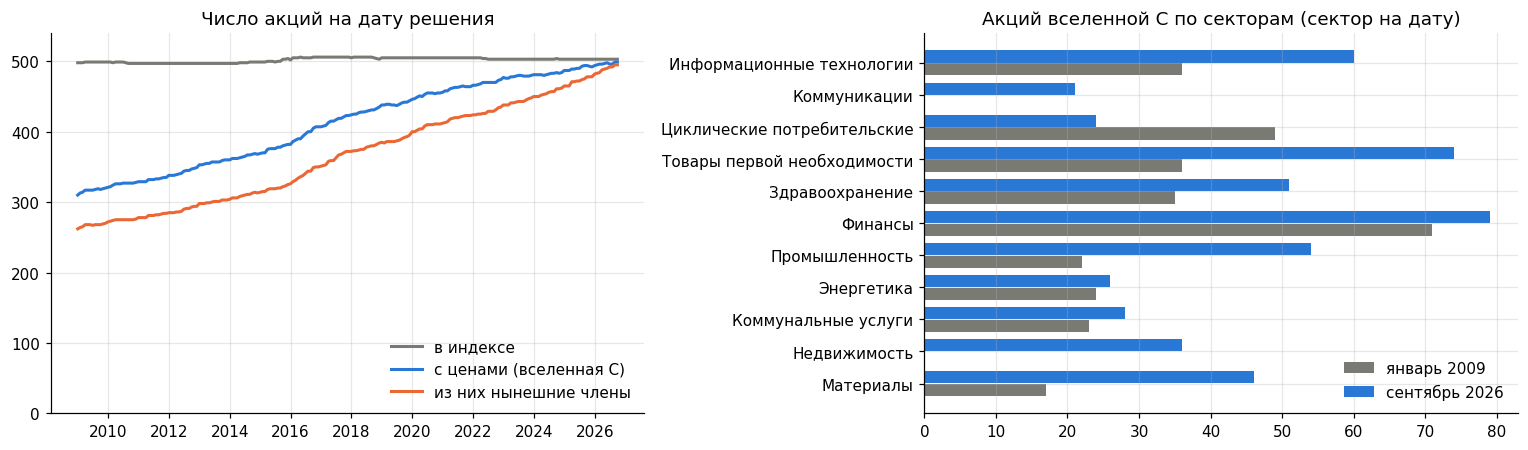

,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
в индексе,498.00,498.83,498.00,497.00,497.00,497.00,498.17,500.75,505.42,505.92,505.42,505.00,505.00,505.00,503.67,503.00,503.08,503.00,503.00
с ценами (вселенная C),310.00,317.50,326.33,332.58,343.92,357.00,365.50,377.00,397.58,417.17,430.00,440.25,452.92,462.67,470.42,478.75,482.50,491.00,496.89
из них нынешние члены,262.00,267.92,275.08,281.42,290.00,300.83,310.08,320.08,341.42,363.75,378.17,389.42,407.75,420.00,429.25,443.25,456.50,473.42,489.78
доля с ценами,0.62,0.64,0.66,0.67,0.69,0.72,0.73,0.75,0.79,0.82,0.85,0.87,0.90,0.92,0.93,0.95,0.96,0.98,0.99


In [8]:
me08 = U.ME[U.ME >= "2008-12-01"]
cov_t = pd.DataFrame({"в индексе": HMEM.loc[me08].sum(axis=1), "с ценами (вселенная C)": EC.loc[me08].sum(axis=1),
                      "из них нынешние члены": EC.loc[me08, [t for t in TICKERS if t in CUR]].sum(axis=1)})
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for (name, s), c in zip(cov_t.items(), [COL["spy"], COL["ml"], COL["ew"]]):
    axes[0].plot(s.index, s.values, color=c, lw=2, label=name)
axes[0].set_ylim(0, 540); axes[0].set_title("Число акций на дату решения"); axes[0].legend(frameon=False, loc="lower right")


def sector_counts(d):
    i = IDX.get_loc(d)
    k = U.SEC_IDX[i][ELIG["C"][i]]
    return pd.Series([SECTORS[x] if x >= 0 else "не определён" for x in k]).value_counts()


sec_tab = pd.DataFrame({"C, 2009": sector_counts(me08[1]), "C, 2026": sector_counts(U.ME[-1])}).reindex(SECTORS).fillna(0)
y = np.arange(len(SECTORS))
axes[1].barh(y + 0.2, sec_tab["C, 2009"], height=0.38, color=COL["spy"], label="январь 2009")
axes[1].barh(y - 0.2, sec_tab["C, 2026"], height=0.38, color=COL["ml"], label="сентябрь 2026")
axes[1].set_yticks(y); axes[1].set_yticklabels(SECTORS); axes[1].invert_yaxis()
axes[1].set_title("Акций вселенной C по секторам (сектор на дату)"); axes[1].legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()
cov_t.assign(**{"доля с ценами": cov_t.iloc[:, 1] / cov_t.iloc[:, 0]}).groupby(cov_t.index.year).mean().round(2).T

Чем раньше год, тем меньше доля членов индекса, у которых есть цены: Yahoo удаляет историю поглощённых и
обанкротившихся компаний. Вселенная C поэтому неполная; остаточное смещение обсуждается в разделе 8.

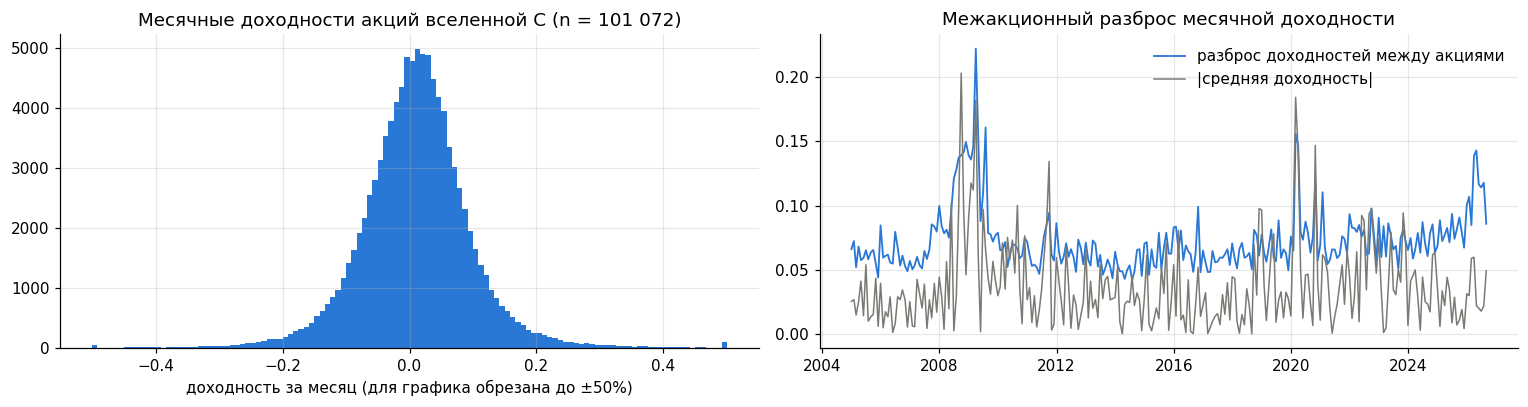

эксцесс месячных доходностей: исходный 18.1, после обрезки до ±50% 3.9 (обрезано 0.14% наблюдений)
медианный разброс доходности между акциями за месяц: 6.6% — это масштаб того, что можно выиграть выбором акций


In [9]:
mr = U.C.loc[U.ME].pct_change().shift(-1).where(EC.loc[U.ME].to_numpy())        # доходность следующего месяца
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
x_raw = mr.stack()
x = x_raw.clip(-0.5, 0.5)
axes[0].hist(x, bins=120, color=COL["ml"])
axes[0].set_title(f"Месячные доходности акций вселенной C (n = {len(x):_})".replace("_", " "))
axes[0].set_xlabel("доходность за месяц (для графика обрезана до ±50%)")
disp = mr.std(axis=1).dropna()
axes[1].plot(disp.index, disp.values, color=COL["ml"], lw=1.2, label="разброс доходностей между акциями")
axes[1].plot(disp.index, mr.mean(axis=1).reindex(disp.index).abs(), color=COL["spy"], lw=1, label="|средняя доходность|")
axes[1].set_title("Межакционный разброс месячной доходности"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()
print(f"эксцесс месячных доходностей: исходный {x_raw.kurt():.1f}, после обрезки до ±50% {x.kurt():.1f} "
      f"(обрезано {(x_raw.abs() > 0.5).mean():.2%} наблюдений)")
print(f"медианный разброс доходности между акциями за месяц: {disp.median():.1%} — "
      f"это масштаб того, что можно выиграть выбором акций")

## 3. Протокол исследования

**Решение и исполнение.** Портфель пересматривается по закрытию последнего торгового дня месяца, сделки — по цене
открытия следующего дня. Издержки 0.10% от оборота, списываются так, что счёт точно самофинансируется. Только длинные
позиции, вес акции ≤ 10%, вес сектора ≤ 30%. Акция, исключённая из индекса, продаётся на ближайшей ребалансировке;
если торги по ней прекратились раньше (поглощение), позиция до продажи стоит по последней цене — это явное
допущение; в разделе 8.3 показано, что в этих данных такой случай не встречается.

**Разбиение по времени.**

```
2004      2005 ─ 2009       2009 ─────────────── 2022     2022 ── 2024     2024 ─────── 09.2026
прогрев   только обучение   dev: 5 фолдов OOF            валидация        walk-forward, переобучение
признаков (без оценки)      (выбор всех параметров)      (проверка 1)     каждый квартал (проверка 2)
```

* **dev 2009–2021** — 5 последовательных фолдов. Модель для фолда обучается на всех данных **до** его начала
  (расширяющееся окно). Обучающая строка допускается, только если её цель **полностью известна** на первую дату
  решения блока (очистка по концу цели, purging). Прогнозы фолдов вне выборки (out-of-fold) склеиваются, и по ним
  выбираются все параметры: модель риска, γ, λ, сглаживание, веса ансамбля.
* **валидация 2022–2023** — модель обучена на всём dev; первая проверка выбранного.
* **walk-forward 01.2024 — 09.2026** — модель переобучается в начале каждого квартала (11 кварталов) на всех данных
  до него; ни один параметр здесь не выбирается.

**Заранее заданные основные сравнения** (остальные таблицы — описательные): H1 — IC ансамбля; H2 — Марковиц на
прогнозе против Minimum Variance с тем же γ и наклон против Equal Weight; H3 — Minimum Variance с прогнозом риска
против исторической оценки (по реализованной волатильности); H4 — Equal Weight на вселенных A₀ и C.
Гипотезы H5–H10 проверяются по тому же протоколу и на тех же блоках; их сравнения заданы до расчёта (разделы 5.2–5.5
и 6), но период walk-forward к этому моменту уже был просмотрен.

Каждый период — отдельный счёт со стартом 1.0. **Метрики:** CAGR, годовая волатильность, Sharpe без безрисковой
ставки и Sharpe по доходности сверх ставки 13-недельных векселей (`Sharpe изб.`), максимальная просадка, оборот в год.
**Тесты:** циклический стационарный бутстреп разницы двух стратегий по одним и тем же дням (средняя длина блока 21
день, 2000 повторов). Доверительный интервал и p получены одной процедурой — по отклонениям бутстреп-оценок разницы
от наблюдаемой: двусторонний p для гипотезы «разница = 0» и симметричный 95% интервал, который не содержит 0 ровно
тогда, когда p < 0.05; при 2000 повторах минимальное p = 1/2001, поэтому печатается «< 0.001». Разницы Sharpe
показаны и по доходности сверх безрисковой ставки (`изб.`). При нескольких сравнениях в одной таблице — p с поправкой
Холма (внутри таблицы). Основной метрикой выбора на dev по исходному протоколу остаётся Sharpe без вычета ставки;
раздел 10.2 показывает, что дал бы выбор по Sharpe сверх ставки. Для проверки, есть ли в прогнозе информация, —
перестановочный тест (раздел 6).

**Оговорка.** Период walk-forward 2024–2026 просматривался в ходе разработки, поэтому его результаты — повторный
анализ тех же данных, а не нетронутый тест; полностью независимой проверкой может быть только будущий период
(раздел 10.5).

### 3.1. Оптимизатор портфеля

Марковиц с издержками: `max μ'w − γ/2·w'Σw − κ·Σ|w − w_пред|` при ограничениях выше, где κ = 0.10%; для
Minimum Variance μ = 0. При κ > 0 неприятие риска γ влияет и на Minimum Variance: оно задаёт соотношение риска и
издержек оборота, поэтому Марковиц сравнивается с Minimum Variance **при одном γ**. Ковариация Σ — оценка
Ледуа–Вольфа по дневным доходностям за 252 дня в масштабе месяца: `Σ = (1−δ)·S + δ·m·I` (S — выборочная ковариация,
δ — оптимальный коэффициент сжатия, m — средняя дисперсия). Поскольку `S = X'X/T`, квадратичная форма записывается
как `w'Σw = (1−δ)/T·‖Xw‖² + δm·‖w‖²` — задача размером 252 × N вместо N × N, что ускоряет решатель CLARABEL на
600 акциях в несколько раз. Акциям вне вселенной задаётся верхняя граница веса 0, матрица секторов — на дату решения.
Если задан прогноз волатильности σ̂, корреляции берутся из Σ, а диагональ — из прогноза.

Решение проверяется: статус решателя, конечность весов, сумма, ограничения акции и сектора, нулевые веса вне
вселенной. Если проверка не пройдена или решатель упал, используется равновзвешенный портфель доступных акций с
ограничениями, а дата записывается в журнал `U.opt.log`.

In [10]:
U.lw_cache = {}


def lw_parts(d, e, win=252):
    # центрированные доходности доступных акций e за win дней, коэффициент сжатия δ и средняя дисперсия m
    key = (d, win, e.tobytes())
    if key not in U.lw_cache:
        i = IDX.get_loc(d)
        x = np.nan_to_num(U.R.iloc[i - win + 1:i + 1].to_numpy()[:, e])
        xc = x - x.mean(0)
        delta = ledoit_wolf_shrinkage(xc, assume_centered=True)
        s_diag = (xc ** 2).mean(0)
        U.lw_cache[key] = (xc, delta, s_diag.mean(), s_diag)
    return U.lw_cache[key]


def risk_lw(d, e, vol=None):
    # (X, g): w'Σw = ‖X·w‖² + ‖g∘w‖², Σ — Ледуа–Вольф в масштабе месяца; vol — прогноз дневной волатильности
    xc, delta, m, s_diag = lw_parts(d, e)
    T = xc.shape[0]
    a = np.ones(e.sum()) if vol is None else vol[e] / np.sqrt((1 - delta) * s_diag + delta * m)
    X = np.zeros((T, N)); X[:, e] = xc * a * np.sqrt((1 - delta) / T * HORIZON)
    g = np.full(N, 0.1); g[e] = a * np.sqrt(delta * m * HORIZON)
    return X, g


def cap_weights(w, S):
    # приведение весов к ограничениям (вес ≤ 10%, сектор ≤ 30%) с перераспределением излишка по остальным акциям
    w = np.clip(np.asarray(w, float), 0, None); w = w / w.sum()
    pos = w > 0
    cap_sec = np.minimum(MAX_SECTOR, (S @ pos) * MAX_W).sum() + MAX_W * (pos & (S.sum(0) == 0)).sum()
    if pos.sum() * MAX_W < 1 - 1e-9 or cap_sec < 1 - 1e-9:
        raise ValueError(f"ограничения недостижимы: {pos.sum()} акций с положительным весом")
    for _ in range(500):
        sec = S @ w
        if w.max() <= MAX_W + 1e-10 and sec.max() <= MAX_SECTOR + 1e-10:
            break
        w = np.minimum(w, MAX_W)
        w = w * (1 - S.T @ (sec > MAX_SECTOR) + S.T @ np.where(sec > MAX_SECTOR, MAX_SECTOR / np.maximum(sec, 1e-12), 0.0))
        full = (S.T @ (S @ w >= MAX_SECTOR - 1e-10)).astype(bool) | (w >= MAX_W - 1e-10)
        free = ~full & (w > 0)
        w[free] += (1 - w.sum()) * w[free] / w[free].sum()
    w = w / w.sum()
    if w.max() > MAX_W + 1e-6 or (S @ w).max() > MAX_SECTOR + 1e-6:
        raise ValueError("ограничения не выполнены после перераспределения")
    return w


class Optimizer:
    def __init__(self, T=252, n=N):
        self.n = n
        self.w, self.mu, self.w0 = cp.Variable(n), cp.Parameter(n), cp.Parameter(n)
        self.ub, self.g = cp.Parameter(n, nonneg=True), cp.Parameter(n, nonneg=True)
        self.X = cp.Parameter((T, n))
        self.S = cp.Parameter((len(SECTORS), n), nonneg=True)
        self.kappa = cp.Parameter(nonneg=True)
        self.t = cp.Variable(n)                        # |w − w_пред| через вспомогательную переменную: задача остаётся DPP
        obj = (-self.mu @ self.w + cp.sum_squares(self.X @ self.w) + cp.sum_squares(cp.multiply(self.g, self.w))
               + self.kappa * cp.sum(self.t))
        cons = [cp.sum(self.w) == 1, self.w >= 0, self.w <= self.ub, self.S @ self.w <= MAX_SECTOR,
                self.t >= self.w - self.w0, self.t >= self.w0 - self.w]
        self.prob = cp.Problem(cp.Minimize(obj), cons)
        self.log = []                                  # (дата, причина) резервных решений

    def fallback(self, d, e, S, why):
        self.log.append((d, why))
        return cap_weights(e / e.sum(), S)

    def __call__(self, d, risk, w0, e, gamma=GAMMA_MINVAR, mu=None, kappa=FEE):
        X, g = risk
        S = sec_mat(d)
        # малая вселенная (n < N): переменные только для акций e, свободные места — копии первой акции с границей веса 0
        idx = np.flatnonzero(e) if self.n < N else np.arange(N)
        if len(idx) > self.n:
            raise ValueError(f"в оптимизаторе {self.n} мест, а акций {len(idx)}")
        cols = np.r_[idx, np.full(self.n - len(idx), idx[0])]
        real = np.arange(self.n) < len(idx)
        on = real & e[cols]
        k = np.sqrt(gamma / 2)
        self.X.value, self.g.value, self.S.value, self.kappa.value = k * X[:, cols], k * g[cols], S[:, cols], kappa
        self.mu.value = np.zeros(self.n) if mu is None else np.where(on, np.asarray(mu)[cols], 0.0)
        self.w0.value, self.ub.value = np.where(real, np.asarray(w0, float)[cols], 0.0), np.where(on, MAX_W, 0.0)
        try:
            self.prob.solve(solver=cp.CLARABEL)
        except cp.SolverError as err:
            return self.fallback(d, e, S, f"ошибка решателя: {err}")
        except Exception:                              # сбой обновления данных решателя: повтор с чистым кэшем решателя
            self.prob._solver_cache.clear()
            try:
                self.prob.solve(solver=cp.CLARABEL)
            except Exception as err:
                return self.fallback(d, e, S, f"ошибка решателя: {err}")
        if self.prob.status not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE) or self.w.value is None:
            return self.fallback(d, e, S, f"статус {self.prob.status}")
        w = np.zeros(N); w[idx] = self.w.value[:len(idx)]
        w = np.clip(w, 0, None) * e
        if not np.isfinite(w).all() or w.sum() <= 0:
            return self.fallback(d, e, S, "некорректные веса")
        w = w / w.sum()
        if w.max() > MAX_W + 1e-5 or (S @ w).max() > MAX_SECTOR + 1e-5:
            return self.fallback(d, e, S, "нарушены ограничения")
        return w


U.opt = Optimizer()
U.opt_sub = {}                                         # оптимизаторы меньшего размера для малых вселенных (раздел 9)


def opt_for(uni):
    return U.opt_sub.get(uni, U.opt)

# проверка: низкоранговая форма совпадает с полной ковариацией Ледуа–Вольфа, ограничения выполняются
d0 = U.ME[150]; e0 = ELIG["C"][IDX.get_loc(d0)]
X0, g0 = risk_lw(d0, e0)
S_full = LedoitWolf().fit(np.nan_to_num(U.R.iloc[IDX.get_loc(d0) - 251:IDX.get_loc(d0) + 1].to_numpy()[:, e0])).covariance_ * HORIZON
wt = np.random.default_rng(0).dirichlet(np.ones(e0.sum()))
wf = np.zeros(N); wf[e0] = wt
t0 = time.time(); w_mv = U.opt(d0, (X0, g0), np.zeros(N), e0); dt = time.time() - t0
print(f"{d0.date()}: акций во вселенной {e0.sum()}; w'Σw: полная матрица {wt @ S_full @ wt:.6e}, "
      f"низкоранговая форма {np.sum((X0 @ wf) ** 2) + np.sum((g0 * wf) ** 2):.6e}")
print(f"Minimum Variance: решение за {dt:.2f} с; сумма весов {w_mv.sum():.4f}, макс. вес {w_mv.max():.4f}, "
      f"макс. сектор {(sec_mat(d0) @ w_mv).max():.4f}, акций с весом > 0.1%: {(w_mv > 0.001).sum()}, вне вселенной: {w_mv[~e0].sum():.1e}")

2016-07-29: акций во вселенной 400; w'Σw: полная матрица 2.719403e-03, низкоранговая форма 2.719403e-03
Minimum Variance: решение за 4.86 с; сумма весов 1.0000, макс. вес 0.0998, макс. сектор 0.3000, акций с весом > 0.1%: 31, вне вселенной: 0.0e+00


### 3.2. Бэктест, метрики и статистические тесты

In [11]:
ME_SET = set(U.ME)


def backtest(weight_fn, start, end, fee=FEE, record=None, prices=None, rebal=None):
    # weight_fn(d, w_текущие) -> целевые веса по данным на закрытие d (последний день месяца); сделки — по open следующего дня.
    # record — словарь для записи целевых весов по датам решения; prices — (C, O) для сценариев; rebal — даты решений
    days = IDX[(IDX >= start) & (IDX < end)]
    i0 = IDX.get_loc(days[0])
    Cv, Ov = (U.C.to_numpy(), U.O.to_numpy()) if prices is None else prices
    rebal = ME_SET if rebal is None else rebal
    hold, cash = np.zeros(N), 1.0
    eq, turn = [], []

    def decide(d, w_cur):
        w = weight_fn(d, w_cur)
        if record is not None:
            record[d] = w
        return w

    pending = decide(IDX[i0 - 1], np.zeros(N))
    for i in range(i0, i0 + len(days)):
        hold = hold * Ov[i] / Cv[i - 1]
        if pending is not None:
            E0 = cash + hold.sum()
            E = E0
            for _ in range(20):                         # самофинансирование: E = E0 − fee·Σ|w·E − h|
                E_new = E0 - fee * np.abs(pending * E - hold).sum()
                if abs(E_new - E) < 1e-15:
                    break
                E = E_new
            to = np.abs(pending * E - hold).sum()
            hold, cash = pending * E, 0.0
            turn.append(to / E0)
            pending = None
        hold = hold * Cv[i] / Ov[i]
        eq.append(cash + hold.sum())
        if IDX[i] in rebal and i < i0 + len(days) - 1:
            E = cash + hold.sum()
            pending = decide(IDX[i], hold / E)
    return pd.Series(eq, index=days), np.array(turn)


def daily_r(eq):
    return eq.pct_change().fillna(eq.iloc[0] - 1)


def perf(eq, turn=None):
    r = daily_r(eq)
    ex = r - RF.reindex(r.index).fillna(0.0)
    yrs = len(eq) / 252
    dd = (eq / eq.cummax().clip(lower=1.0) - 1).min()
    out = {"CAGR": eq.iloc[-1] ** (1 / yrs) - 1, "волатильность": r.std() * np.sqrt(252),
           "Sharpe": r.mean() / r.std() * np.sqrt(252), "Sharpe изб.": ex.mean() / ex.std() * np.sqrt(252), "MaxDD": dd}
    if turn is not None:
        out["оборот в год"] = turn.sum() / yrs
    return out


RES, CUR_EQ = {}, {}          # (стратегия, период) -> метрики / кривая капитала
RES_COLS = ("CAGR", "волатильность", "Sharpe", "Sharpe изб.", "MaxDD", "оборот в год")


def run_strats(strats, periods=PER):
    res, cur = {}, {}
    for name, fn in strats.items():
        for per in periods:
            eq, to = backtest(fn, *PERIODS[per])
            res[(name, per)], cur[(name, per)] = perf(eq, to), eq
    return res, cur


def res_table(names, cols=RES_COLS, periods=PER, res=None):
    res = RES if res is None else res
    t = pd.DataFrame({k: v for k, v in res.items() if k[0] in names}).T.unstack(1).swaplevel(axis=1)
    return t[[(p, k) for p in periods for k in cols if (p, k) in t.columns]].reindex(names)


def stationary_idx(T, rng, block=BOOT_BLOCK):
    # циклический стационарный бутстреп (Politis–Romano): блоки геометрической длины, индексы по модулю T
    new = rng.random(T) < 1 / block
    new[0] = True
    pos = np.flatnonzero(new)
    g = np.cumsum(new) - 1
    starts = rng.integers(0, T, size=len(pos))
    return (starts[g] + np.arange(T) - pos[g]) % T


def boot_diff(r1, r2, stat, n=N_BOOT, seed=0, block=BOOT_BLOCK):
    # разница статистики двух стратегий на одних и тех же днях: оценка, 95% ДИ и двусторонний p для H0 «разница = 0».
    # Одна процедура для ДИ и p — по отклонениям |d* − d| бутстреп-оценок от наблюдаемой d: p — доля повторов, где
    # отклонение не меньше |d| ((k + 1)/(n + 1)); ДИ = d ± 95-й перцентиль отклонений. Поэтому ДИ не содержит 0
    # ровно тогда, когда p < 0.05 (с точностью до поправки +1).
    rng = np.random.default_rng(seed)
    x = pd.concat([r1, r2], axis=1).dropna().to_numpy()
    base = stat(x[:, 0]) - stat(x[:, 1])
    d = np.empty(n)
    for k in range(n):
        b = x[stationary_idx(len(x), rng, block)]
        d[k] = stat(b[:, 0]) - stat(b[:, 1])
    dev = np.abs(d - base)
    p = (np.sum(dev >= abs(base)) + 1) / (n + 1)
    q = np.percentile(dev, 95)
    return base, np.array([base - q, base + q]), p


def holm(p):
    p = np.asarray(p, float); o = np.argsort(p); m = len(p)
    adj = np.minimum(1, np.maximum.accumulate((m - np.arange(m)) * p[o]))
    out = np.empty(m); out[o] = adj
    return out


sharpe_ = lambda r: r.mean() / r.std() * np.sqrt(252)
vol_ = lambda r: r.std() * np.sqrt(252)
cagr_ = lambda r: (1 + r).prod() ** (252 / len(r)) - 1


def excess(r):
    return r - RF.reindex(r.index).fillna(0.0)


def sharpe_row(r1, r2):
    # разница Sharpe и Sharpe сверх безрисковой ставки; бутстреп с тем же зерном выбирает те же даты для обеих
    d, ci, p = boot_diff(r1, r2, sharpe_)
    dx, cix, px = boot_diff(excess(r1), excess(r2), sharpe_)
    return {"ΔSharpe": d, "95% ДИ": f"[{ci[0]:+.2f}; {ci[1]:+.2f}]", "p": p,
            "ΔSharpe изб.": dx, "95% ДИ изб.": f"[{cix[0]:+.2f}; {cix[1]:+.2f}]", "p изб.": px}


def sharpe_tests(pairs, periods=PER[1:], cur=None):
    # pairs — список (портфель, против); p (Холм) — поправка на число сравнений в таблице, отдельно для обеих метрик
    cur = CUR_EQ if cur is None else cur
    rows = []
    for name, ref in pairs:
        for per in periods:
            rows.append({"портфель": name, "период": per, "против": ref,
                         **sharpe_row(daily_r(cur[(name, per)]), daily_r(cur[(ref, per)]))})
    t = pd.DataFrame(rows)
    t.insert(t.columns.get_loc("ΔSharpe изб."), "p (Холм)", holm(t["p"]))
    t["p изб. (Холм)"] = holm(t["p изб."])
    return t.set_index(["портфель", "период", "против"])


def show_tests(t, digits=3):
    # p-значения меньше 0.001 печатаются как «< 0.001»: при 2000 повторах минимальное p = 1/2001
    name = lambda c_: c_[0] if isinstance(c_, tuple) else c_
    fmt = {c_: (lambda v: "< 0.001" if v < 0.001 else f"{v:.3f}") for c_ in t.columns if str(name(c_)).startswith("p")}
    fmt |= {c_: ("{:.0f}" if name(c_) == "месяцев" else f"{{:.{digits}f}}") for c_ in t.columns
            if c_ not in fmt and pd.api.types.is_numeric_dtype(t[c_])}
    return t.style.format(fmt, na_rep="—")


def nw_t(x, lags=3):
    # t-статистика среднего с поправкой Ньюи–Уэста (месячные ряды автокоррелированы)
    x = np.asarray(x, float); x = x[np.isfinite(x)]; mu = x.mean(); x = x - mu; n = len(x)
    s = x @ x / n
    for l in range(1, lags + 1):
        s += 2 * (1 - l / (lags + 1)) * (x[l:] @ x[:-l]) / n
    return mu / np.sqrt(s / n) if s > 0 else np.nan


def fund_curve(ticker, a, b, fee=FEE):
    # покупка фонда на весь капитал по открытию первого дня с комиссией, как в backtest: E = 1 / (1 + fee)
    s = WIDE["close"][ticker][(IDX >= a) & (IDX < b)].dropna()
    return s / WIDE["open"][ticker].loc[s.index[0]] / (1 + fee)


def elig(uni, d):
    return ELIG[uni][IDX.get_loc(d)]

### 3.3. Проверки корректности

Короткие тесты на искусственных данных и принудительных сбоях: самофинансирование с комиссией, ночной гэп, дрейф
весов без сделок, резервное решение оптимизатора, равномерность бутстрепа. Каждый тест завершается проверкой
`assert`, поэтому ноутбук не выполнится дальше, если что-то из этого нарушено.

In [12]:
ones = np.ones((len(IDX), N))
ew_all = lambda d, w0: np.full(N, 1 / N)
a_, b_ = pd.Timestamp("2015-01-01"), pd.Timestamp("2016-01-01")
eq_t, to_t = backtest(ew_all, a_, b_, prices=(ones, ones))
print(f"1) постоянные цены, равные веса: капитал {eq_t.iloc[-1]:.12f}, ожидается 1/(1 + fee) = {1 / (1 + FEE):.12f}; "
      f"оборот после первой сделки {to_t[1:].max():.1e}")
assert abs(eq_t.iloc[-1] - 1 / (1 + FEE)) < 1e-12

i_ex = IDX.get_loc(IDX[IDX >= a_][0])                     # день первой сделки (open)
gap = ones.copy(); gap[i_ex:, 0] = 2.0                    # акция 0 удваивается с открытия дня первой сделки
eq_g, _ = backtest(ew_all, a_, b_, prices=(gap, gap))
print(f"2) гэп на открытии дня сделки не даёт дохода новой позиции: капитал {eq_g.iloc[-1]:.12f}")
assert abs(eq_g.iloc[-1] - 1 / (1 + FEE)) < 1e-12
gap2 = ones.copy(); gap2[i_ex + 1:, 0] = 2.0              # тот же гэп на следующий день — позиция уже куплена
eq_g2, _ = backtest(ew_all, a_, b_, prices=(gap2, gap2))
print(f"   гэп на следующий день после покупки: капитал {eq_g2.iloc[-1]:.6f}, ожидается ≈ (1 + 1/N)/(1 + fee) = {(1 + 1 / N) / (1 + FEE):.6f}"
      " (разница — комиссия ежемесячного возврата к равным весам)")
assert abs(eq_g2.iloc[-1] - (1 + 1 / N) / (1 + FEE)) < 1e-4

hold_fn = lambda d, w0: w0 if w0.sum() > 0 else np.full(N, 1 / N)   # после первой сделки — держать текущие веса
eq_h, to_h = backtest(hold_fn, a_, b_, prices=(gap2, gap2))
print(f"   дрейф весов: стратегия «держать» после гэпа — капитал {eq_h.iloc[-1]:.12f}, ожидается "
      f"{(1 + 1 / N) / (1 + FEE):.12f}; оборот на последующих ребалансировках {to_h[1:].max():.1e}")
assert abs(eq_h.iloc[-1] - (1 + 1 / N) / (1 + FEE)) < 1e-12 and to_h[1:].max() < 1e-12

_orig_solve = U.opt.prob.solve
w_ok = U.opt(d0, (X0, g0), np.zeros(N), e0)


def _fail(*a, **k):
    raise cp.SolverError("принудительный сбой")


U.opt.prob.solve = _fail
w_fb = U.opt(d0, (X0, g0), np.zeros(N), e0)
U.opt.prob.solve = _orig_solve
U.opt.log.clear()
print(f"3) сбой решателя: резервный портфель = равные веса с ограничениями: "
      f"{np.allclose(w_fb, cap_weights(e0 / e0.sum(), sec_mat(d0)))}; отличие от прошлого решения (L1) {np.abs(w_fb - w_ok).sum():.3f}")
assert np.allclose(w_fb, cap_weights(e0 / e0.sum(), sec_mat(d0)))

rng_ = np.random.default_rng(12)
freq = np.bincount(np.concatenate([stationary_idx(100, rng_, 21) for _ in range(10000)]), minlength=100)
print(f"4) бутстреп, 10 000 выборок длины 100: средняя частота первых 10 позиций {freq[:10].mean():.0f}, "
      f"последних 10 — {freq[-10:].mean():.0f} (ожидается 10 000)")
assert abs(freq[:10].mean() / 1e4 - 1) < 0.03 and abs(freq[-10:].mean() / 1e4 - 1) < 0.03

1) постоянные цены, равные веса: капитал 0.999000999001, ожидается 1/(1 + fee) = 0.999000999001; оборот после первой сделки 0.0e+00
2) гэп на открытии дня сделки не даёт дохода новой позиции: капитал 0.999000999001
   гэп на следующий день после покупки: капитал 1.000644, ожидается ≈ (1 + 1/N)/(1 + fee) = 1.000647 (разница — комиссия ежемесячного возврата к равным весам)
   дрейф весов: стратегия «держать» после гэпа — капитал 1.000646799658, ожидается 1.000646799658; оборот на последующих ребалансировках 0.0e+00


3) сбой решателя: резервный портфель = равные веса с ограничениями: True; отличие от прошлого решения (L1) 1.845
4) бутстреп, 10 000 выборок длины 100: средняя частота первых 10 позиций 10014, последних 10 — 10004 (ожидается 10 000)


## 4. Базовые портфели без прогнозов

* **Equal Weight** — равные веса всех акций вселенной;
* **обратная волатильность** — `w ∝ 1/σ`, σ — волатильность за 252 дня;
* **Minimum Variance** — портфель минимальной дисперсии на ковариации Ледуа–Вольфа (γ = 10, штраф за оборот κ = 0.10%);
* контроль: **Minimum Variance без штрафа за оборот** (κ = 0);
* **Mean-Variance на исторической доходности** — Марковиц с ожидаемой доходностью по средней за год (ниже).

Это ориентиры, которые должна обогнать любая ML-стратегия: равные веса — классически трудный для обыгрыша эталон
(DeMiguel, Garlappi, Uppal, 2009), Minimum Variance использует только оценку риска.

In [13]:
def ew_fn(uni="C"):
    return lambda d, w0: cap_weights(elig(uni, d) / elig(uni, d).sum(), sec_mat(d))


def hist_vol(d):
    i = IDX.get_loc(d)
    return U.R.iloc[i - 251:i + 1].std().to_numpy()


def invvol_fn(uni="C", vol_fn=None):
    vol_fn = hist_vol if vol_fn is None else vol_fn
    def fn(d, w0):
        e, v = elig(uni, d), vol_fn(d)
        v = np.where(np.isfinite(v) & (v > 0), v, np.nanmedian(v[e]))
        return cap_weights(np.where(e, 1 / v, 0.0), sec_mat(d))
    return fn


def minvar_fn(uni="C", vol_fn=None, gamma=GAMMA_MINVAR, kappa=FEE):
    def fn(d, w0):
        e = elig(uni, d)
        return opt_for(uni)(d, risk_lw(d, e, None if vol_fn is None else vol_fn(d)), w0, e, gamma=gamma, kappa=kappa)
    return fn


MV0_NAME = "Minimum Variance без штрафа за оборот"
BASE = {"Equal Weight": ew_fn(), "обратная волатильность": invvol_fn(), "Minimum Variance": minvar_fn()}
r_, c_ = cached("base_C", lambda: run_strats({**BASE, MV0_NAME: minvar_fn(kappa=0.0)}))
RES.update(r_); CUR_EQ.update(c_)
for per, (a, b) in PERIODS.items():
    CUR_EQ[("SPY", per)] = fund_curve("SPY", a, b); RES[("SPY", per)] = perf(CUR_EQ[("SPY", per)])
display(res_table(list(BASE) + [MV0_NAME, "SPY"]).round(3))
sharpe_tests([("Minimum Variance", "Equal Weight"), ("обратная волатильность", "Equal Weight")], periods=PER).round(3)

dev 2009–2021                                                      валидация 2022–2023                                                      walk-forward 2024–2026                \
                                               CAGR волатильность Sharpe Sharpe изб.  MaxDD оборот в год                CAGR волатильность Sharpe Sharpe изб.  MaxDD оборот в год                   CAGR волатильность   
Equal Weight                                  0.177         0.202  0.905       0.882 -0.396        0.736               0.011         0.192  0.155      -0.028 -0.215        1.186                  0.122         0.139   
обратная волатильность                        0.168         0.184  0.939       0.913 -0.386        0.745               0.008         0.178  0.134      -0.064 -0.200        1.138                  0.106         0.128   
Minimum Variance                              0.120         0.132  0.921       0.886 -0.336        1.358              -0.037         0.131 -0.221      -0.488 -0.165        2.060                  0.156         0.098   
Minimum Variance без штрафа за оборот         0.119         0.127  0.946       0.909 -0.303        4.807              -0.040         0.131 -0.249      -0.516 -0.171        6.105                  0.154         0.096   
SPY                                           0.159         0.179  0.914       0.888 -0.337          NaN               0.014         0.195  0.170      -0.010 -0.245          NaN                  0.205         0.156   

                                                                              
                                      Sharpe Sharpe изб.  MaxDD оборот в год  
Equal Weight                           0.899       0.592 -0.178        1.128  
обратная волатильность                 0.848       0.515 -0.161        1.095  
Minimum Variance                       1.525       1.089 -0.100        1.550  
Minimum Variance без штрафа за оборот  1.543       1.098 -0.098        5.547  
SPY                                    1.279       1.004 -0.188          NaN

ΔSharpe          95% ДИ      p  p (Холм)  ΔSharpe изб.     95% ДИ изб.  p изб.  p изб. (Холм)
портфель               период                 против                                                                                                     
Minimum Variance       dev 2009–2021          Equal Weight    0.016  [-0.36; +0.39]  0.928     1.000         0.004  [-0.37; +0.37]   0.988            1.0
                       валидация 2022–2023    Equal Weight   -0.376  [-1.07; +0.32]  0.279     1.000        -0.461  [-1.17; +0.25]   0.201            1.0
                       walk-forward 2024–2026 Equal Weight    0.627  [-0.18; +1.44]  0.122     0.732         0.497  [-0.29; +1.28]   0.221            1.0
обратная волатильность dev 2009–2021          Equal Weight    0.033  [-0.02; +0.09]  0.267     1.000         0.031  [-0.03; +0.09]   0.295            1.0
                       валидация 2022–2023    Equal Weight   -0.021  [-0.12; +0.08]  0.684     1.000        -0.036  [-0.14; +0.07]   0.488            1.0
                       walk-forward 2024–2026 Equal Weight   -0.051  [-0.23; +0.12]  0.546     1.000        -0.077  [-0.25; +0.10]   0.354            1.0

**Mean-Variance на исторической доходности** — классический портфель Марковица без ML: ожидаемая доходность акции —
её средняя дневная доходность за последние 252 дня в масштабе месяца, ковариация, ограничения и штраф за оборот — как
у Minimum Variance. Неприятие риска γ ∈ {1, 3, 10, 30, 100} выбирается по Sharpe на dev. Это третий эталон из
постановки задания: показывает, что даёт «наивная» оценка μ по истории, прежде чем заменять её ML-прогнозом.

In [14]:
def mu_hist(d):
    # историческая оценка ожидаемой доходности: средняя дневная доходность за 252 дня в масштабе месяца
    i = IDX.get_loc(d)
    return np.nan_to_num(U.R.iloc[i - 251:i + 1].mean().to_numpy()) * HORIZON


def mvh_fn(uni="C", gamma=GAMMA_MINVAR):
    def fn(d, w0):
        e = elig(uni, d)
        return opt_for(uni)(d, risk_lw(d, e), w0, e, gamma=gamma, mu=mu_hist(d))
    return fn


GAMMAS = [1, 3, 10, 30, 100]                          # сетка неприятия риска (и для Марковица на прогнозе, раздел 6)
MVH_DEV = cached("mvh_grid_C", lambda: {g: perf(*backtest(mvh_fn(gamma=g), *PERIODS[PER[0]])) for g in GAMMAS}, (GAMMAS,))
GAMMA_MVH = max(MVH_DEV, key=lambda g: MVH_DEV[g]["Sharpe"])
MVH_NAME = f"Mean-Variance (историческая доходность, γ = {GAMMA_MVH})"
r_, c_ = cached("mvh_C", lambda: run_strats({MVH_NAME: mvh_fn(gamma=GAMMA_MVH)}), (GAMMA_MVH,))
RES.update(r_); CUR_EQ.update(c_)
print("Mean-Variance на исторической доходности, Sharpe на dev по γ:",
      {g: round(v["Sharpe"], 3) for g, v in MVH_DEV.items()}, "→ γ =", GAMMA_MVH)
display(res_table(["Equal Weight", "Minimum Variance", MVH_NAME, "SPY"]).round(3))
show_tests(sharpe_tests([(MVH_NAME, "Equal Weight"), (MVH_NAME, "Minimum Variance")]))

Mean-Variance на исторической доходности, Sharpe на dev по γ: {1: 0.647, 3: 0.617, 10: 0.56, 30: 0.677, 100: 0.909} → γ = 100


dev 2009–2021                                                      валидация 2022–2023                                                      walk-forward 2024–2026  \
                                                          CAGR волатильность Sharpe Sharpe изб.  MaxDD оборот в год                CAGR волатильность Sharpe Sharpe изб.  MaxDD оборот в год                   CAGR   
Equal Weight                                             0.177         0.202  0.905       0.882 -0.396        0.736               0.011         0.192  0.155      -0.028 -0.215        1.186                  0.122   
Minimum Variance                                         0.120         0.132  0.921       0.886 -0.336        1.358              -0.037         0.131 -0.221      -0.488 -0.165        2.060                  0.156   
Mean-Variance (историческая доходность, γ = 100)         0.126         0.141  0.909       0.877 -0.337        5.763              -0.046         0.142 -0.259      -0.506 -0.185        7.108                  0.229   
SPY                                                      0.159         0.179  0.914       0.888 -0.337          NaN               0.014         0.195  0.170      -0.010 -0.245          NaN                  0.205   

                                                                                                       
                                                 волатильность Sharpe Sharpe изб.  MaxDD оборот в год  
Equal Weight                                             0.139  0.899       0.592 -0.178        1.128  
Minimum Variance                                         0.098  1.525       1.089 -0.100        1.550  
Mean-Variance (историческая доходность, γ = 100)         0.122  1.757       1.406 -0.127        6.324  
SPY                                                      0.156  1.279       1.004 -0.188          NaN

## 5. Прогноз относительной доходности (H1, H5–H10)

### 5.1. Признаки и цель

**Обучающая цель** близка к исполнению: доходность акции **от открытия следующего дня** (когда стратегия покупает)
за фиксированные 21 торговый день минус средняя доходность акций вселенной C на ту же дату. Это приближение:
торгуемый месяц длится 19–23 торговых дня и заканчивается открытием после следующей даты решения. Относительная доходность выбрана потому, что
портфелю важно, какие акции лучше других, а не направление рынка. Цель обрезается по 1-му и 99-му перцентилям
обучающей части. Качество прогноза оценивается на **реально торгуемом интервале** — от открытия после даты решения
до открытия после следующей даты решения; вклад ночного гэпа до покупки измерен отдельно (раздел 5.3).

**42 признака**, все — по данным на закрытие дня решения:

| группа | признаки |
|---|---|
| тренд (8) | отношение цены к SMA 10/20/50/200 и EMA 12/26, MACD и его гистограмма |
| импульс (8) | ADX 14, RSI 14, ROC за 10/21/63 дня, стохастик %K/%D, моментум 12–1 (доходность за год без последнего месяца) |
| волатильность (6) | NATR 14, ширина и %B полос Боллинджера, ст. отклонение за 21 и 63 дня, волатильность Паркинсона |
| объём (4) | наклон OBV, MFI 14, объём к среднему за 50 дней, z-оценка объёма |
| статистика доходностей (8) | среднее за 21 и 63 дня, дисперсия, асимметрия, эксцесс, автокорреляция, корреляция и бета к S&P 500 |
| сектор (8) | относительная доходность сектора за 21 и 63 дня, относительная сила, корреляция с рынком и её изменение, изменение волатильности, лаговый прогноз по другим секторам (ridge-VAR), ранг сектора |

Секторные признаки берутся по сектору акции **на эту дату** (раздел 2.2).

**Строки обучения** — каждый 5-й торговый день, только акции вселенной C в этот день; строки прогноза — последние
дни месяцев. **Очистка (purging):** строка попадает в обучение блока, только если день, на открытии которого
заканчивается её цель, не позже первой даты решения блока.

In [15]:
def rsi(c, n=14):
    d = c.diff()
    up = d.clip(lower=0).ewm(alpha=1 / n, adjust=False).mean()
    dn = (-d.clip(upper=0)).ewm(alpha=1 / n, adjust=False).mean()
    return 100 - 100 / (1 + up / dn)


def stock_features(t):
    c, h, l, v = U.C[t].where(listed[t]), U.H[t], U.L[t], U.V[t]
    r = c.pct_change(fill_method=None)
    f = pd.DataFrame(index=IDX)
    for n in (10, 20, 50, 200):
        f[f"sma{n}_ratio"] = c / c.rolling(n).mean() - 1
    f["ema12_ratio"] = c / c.ewm(span=12, adjust=False).mean() - 1
    f["ema26_ratio"] = c / c.ewm(span=26, adjust=False).mean() - 1
    macd = c.ewm(span=12, adjust=False).mean() - c.ewm(span=26, adjust=False).mean()
    f["macd"] = macd / c
    f["macd_hist"] = (macd - macd.ewm(span=9, adjust=False).mean()) / c
    tr = pd.concat([h - l, (h - c.shift()).abs(), (l - c.shift()).abs()], axis=1).max(axis=1)
    atr = tr.ewm(alpha=1 / 14, adjust=False).mean()
    up, dn = h.diff(), -l.diff()
    pdi = 100 * up.where((up > dn) & (up > 0), 0).ewm(alpha=1 / 14, adjust=False).mean() / atr
    ndi = 100 * dn.where((dn > up) & (dn > 0), 0).ewm(alpha=1 / 14, adjust=False).mean() / atr
    f["adx14"] = (100 * (pdi - ndi).abs() / (pdi + ndi)).ewm(alpha=1 / 14, adjust=False).mean()
    f["rsi14"] = rsi(c)
    for n in (10, 21, 63):
        f[f"roc{n}"] = c.pct_change(n, fill_method=None)
    lo14, hi14 = l.rolling(14).min(), h.rolling(14).max()
    f["stoch_k"] = 100 * (c - lo14) / (hi14 - lo14)
    f["stoch_d"] = f["stoch_k"].rolling(3).mean()
    f["mom_12_1"] = c.shift(21) / c.shift(252) - 1
    f["natr14"] = atr / c
    m20, s20 = c.rolling(20).mean(), c.rolling(20).std(ddof=0)
    f["bb_width"] = 4 * s20 / m20
    f["bb_pctb"] = (c - (m20 - 2 * s20)) / (4 * s20)
    f["std21"] = r.rolling(21).std()
    f["std63"] = r.rolling(63).std()
    f["rv_parkinson21"] = np.sqrt((np.log(h / l) ** 2).rolling(21).mean() / (4 * np.log(2)))
    obv = (np.sign(r.fillna(0)) * v).cumsum()
    f["obv_slope21"] = (obv - obv.shift(21)) / v.rolling(63).mean() / 21
    tp = (h + l + c) / 3
    mf = tp * v
    f["mfi14"] = 100 - 100 / (1 + mf.where(tp > tp.shift(), 0).rolling(14).sum() / mf.where(tp < tp.shift(), 0).rolling(14).sum())
    f["vol_ma_ratio"] = v / v.rolling(50).mean()
    f["volume_z21"] = (v - v.rolling(21).mean()) / v.rolling(21).std()
    f["ret_mean21"] = r.rolling(21).mean()
    f["ret_mean63"] = r.rolling(63).mean()
    f["ret_var63"] = r.rolling(63).var()
    f["skew63"] = r.rolling(63).skew()
    f["kurt63"] = r.rolling(63).kurt()
    f["autocorr63"] = r.rolling(63).corr(r.shift(1))
    f["corr_spx63"] = r.rolling(63).corr(spx_r)
    f["beta252"] = r.rolling(252).cov(spx_r) / spx_r.rolling(252).var()
    return f.replace([np.inf, -np.inf], np.nan)


def sector_features():
    # лаговая связь секторов: недельные доходности секторов регрессируются на доходности прошлой недели (ridge, окно 3 года);
    # в окне участвуют только ETF с полной историей в нём
    W = U.SEC.resample("W-FRI").last().pct_change(fill_method=None)
    Wv = W.to_numpy()
    lead = pd.DataFrame(np.nan, index=W.index, columns=U.SEC.columns)
    for i in range(160, len(W)):
        X, Y = Wv[i - 156:i - 1], Wv[i - 155:i]
        ok = ~np.isnan(X).any(0) & ~np.isnan(Y).any(0) & ~np.isnan(Wv[i])
        X, Y = X[:, ok], Y[:, ok]
        Xc = X - X.mean(0)
        B = np.linalg.solve(Xc.T @ Xc + 1e-3 * len(X) * Xc.var(0).mean() * np.eye(X.shape[1]), Xc.T @ (Y - Y.mean(0)))
        lead.iloc[i, np.flatnonzero(ok)] = (Wv[i, ok] - X.mean(0)) @ B + Y.mean(0)
    lead_d = lead.reindex(IDX, method="ffill")          # значение недели известно с её последнего дня
    out = {}
    for s in U.SEC.columns:
        f = pd.DataFrame(index=IDX)
        for n in (21, 63):
            f[f"sec_rel_ret{n}"] = U.SEC[s].pct_change(n, fill_method=None) - SPX.pct_change(n)
        ratio = U.SEC[s] / SPX
        f["sec_rel_strength"] = ratio / ratio.rolling(50).mean() - 1
        f["sec_corr_spx63"] = U.SR[s].rolling(63).corr(spx_r)
        f["sec_corr_change"] = f["sec_corr_spx63"] - U.SR[s].rolling(252).corr(spx_r)
        f["sec_vol_change"] = U.SR[s].rolling(21).std() / U.SR[s].rolling(126).std()
        f["sec_lead_forecast"] = lead_d[s]
        out[s] = f
    rk = pd.DataFrame({s: out[s]["sec_rel_ret63"] for s in U.SEC.columns}).rank(axis=1, pct=True)
    for s in U.SEC.columns:
        out[s]["sec_rank_rel63"] = rk[s]
    return out


def gather_sector(arr_ts):
    # arr_ts[день, сектор, ...] -> значение для сектора каждой акции на эту дату (NaN, если сектор не определён)
    pad = np.full((arr_ts.shape[0], 1) + arr_ts.shape[2:], np.nan, arr_ts.dtype)
    k = np.where(U.SEC_IDX >= 0, U.SEC_IDX, len(SECTORS))
    return np.concatenate([arr_ts, pad], axis=1)[np.arange(len(IDX))[:, None], k]


def build_panel():
    # FEAT3[день, акция, признак] — для LSTM; PANEL — строки обучения (каждый 5-й день) и даты решений, только вселенная C
    with quiet():
        SF = sector_features()
        fe = {t: stock_features(t) for t in TICKERS}
    st_feats, sec_feats = list(fe[TICKERS[0]].columns), list(SF[SECTORS[0]].columns)
    F_st = np.stack([fe[t].to_numpy(np.float32) for t in TICKERS], axis=1)
    F_sec = gather_sector(np.stack([SF[s].to_numpy(np.float32) for s in SECTORS], axis=1))
    F3 = np.concatenate([F_st, F_sec], axis=2)
    del F_st, F_sec
    feats = st_feats + sec_feats
    T_ = len(IDX)
    O, C = U.O.where(listed).to_numpy(), U.C.where(listed).to_numpy()
    with quiet():
        # обучающая цель: открытие следующего дня -> открытие через HORIZON дней
        y_tr = np.full((T_, N), np.nan); y_tr[:T_ - 1 - HORIZON] = O[1 + HORIZON:] / O[1:T_ - HORIZON] - 1
        lab_tr = np.full(T_, np.datetime64("NaT"), "datetime64[ns]"); lab_tr[:T_ - 1 - HORIZON] = IDX[1 + HORIZON:].to_numpy()
        # прежняя цель (для сравнения): закрытие -> закрытие через HORIZON дней
        y_cc = np.full((T_, N), np.nan); y_cc[:T_ - HORIZON] = C[HORIZON:] / C[:T_ - HORIZON] - 1
        # торгуемый интервал: открытие после даты решения -> открытие после следующей даты решения
        y_tm = np.full((T_, N), np.nan); lab_tm = np.full(T_, np.datetime64("NaT"), "datetime64[ns]")
        y_cm = np.full((T_, N), np.nan)               # та же конечная цена, начало — закрытие дня решения (для гэпа)
        mi = IDX.get_indexer(U.ME)
        for i, k in zip(mi[:-1], mi[1:]):
            ex = O[k + 1] if k + 1 < T_ else C[T_ - 1]
            y_tm[i] = ex / O[i + 1] - 1
            y_cm[i] = ex / C[i] - 1
            lab_tm[i] = IDX[min(k + 1, T_ - 1)]
    di = np.flatnonzero(IDX.isin(U.WEEKLY) | IDX.isin(U.ME))
    rows = pd.MultiIndex.from_product([IDX[di], TICKERS], names=["date", "ticker"])
    P = pd.DataFrame(F3[di].reshape(-1, len(feats)), index=rows, columns=feats)
    for name, arr in (("y_tr", y_tr), ("y_cc", y_cc), ("y_tm", y_tm), ("y_cm", y_cm)):
        P[name] = arr[di].reshape(-1)
    P["lab_end"] = np.repeat(lab_tr[di], N)
    P["lab_end_tm"] = np.repeat(lab_tm[di], N)
    P["sector"] = U.SEC_IDX[di].reshape(-1)
    P = P[ELIG["C"][di].reshape(-1)]
    for name in ("y_tr", "y_cc", "y_tm", "y_cm"):
        P[f"{name}_xs"] = P[name] - P.groupby(level=0)[name].transform("mean")
    d = P.index.get_level_values(0)
    P["is_me"], P["is_w"] = d.isin(U.ME), d.isin(U.WEEKLY)
    return P, F3, feats


t0 = time.time()
PAN, FEAT3, FEATS = build_panel()
FEATS_NOSEC = [f for f in FEATS if not f.startswith("sec_")]
TARGET, FWD_COL = "y_tr_xs", "y_tm_xs"
print(f"панель: {PAN.shape[0]:_} строк (акция × дата), {len(FEATS)} признаков; тензор для LSTM "
      f"{' × '.join(map(str, FEAT3.shape))} ({FEAT3.nbytes / 1e9:.1f} ГБ); {time.time() - t0:.0f} с".replace("_", " "))
PAN[FEATS].describe().T[["count", "mean", "std", "min", "50%", "max"]].round(3).head(12)

панель: 505 058 строк (акция × дата), 42 признаков; тензор для LSTM 5722 × 607 × 42 (0.6 ГБ); 11 с


,count,mean,std,min,50%,max
sma10_ratio,505058.0,0.001,0.035,-0.858,0.003,1.315
sma20_ratio,505058.0,0.003,0.050,-0.882,0.005,1.577
sma50_ratio,505058.0,0.009,0.079,-0.924,0.013,1.313
sma200_ratio,505058.0,0.040,0.157,-0.970,0.046,3.807
ema12_ratio,505058.0,0.001,0.033,-0.840,0.003,0.957
ema26_ratio,505058.0,0.003,0.049,-0.889,0.007,0.921
macd,505058.0,0.001,0.027,-2.915,0.004,0.164
macd_hist,505058.0,-0.000,0.008,-0.922,0.000,0.268
adx14,505058.0,23.926,9.444,4.875,22.055,76.846
rsi14,505058.0,52.211,11.983,7.919,52.451,93.851


**Проверка отсутствия утечки цели** для всех 17 блоков: последний день, на котором заканчивается цель обучающих
строк, должен быть не позже первой даты решения блока. Блок «WF 2024-10-01» — пример, на котором простое календарное
эмбарго в 31 день дало бы утечку (цель строки 30.08.2024 заканчивается 01.10.2024, после решения 30.09.2024).

In [16]:
NEXT_DAY = pd.Series(IDX[1:].append(pd.DatetimeIndex([IDX[-1] + pd.Timedelta(days=1)])), index=IDX)


def block_rows(P, a, b):
    # дата решения относится к блоку, в котором начинается торговля по ней (следующий торговый день)
    nd = NEXT_DAY.reindex(P.index.get_level_values(0)).to_numpy()
    return P[P["is_me"].to_numpy() & (nd >= np.datetime64(a)) & (nd < np.datetime64(b))]


def cutoff(a):
    # первая дата решения блока, начинающегося в день a: последний торговый день до a
    return IDX[IDX < a][-1]


def train_rows(P, a, y=TARGET):
    d = P.index.get_level_values(0)
    return P[P["is_w"].to_numpy() & (d >= "2005-01-01") & P[y].notna().to_numpy()
             & (P["lab_end"].to_numpy() <= np.datetime64(cutoff(a)))]


def purge_check(P, y=TARGET):
    rows = []
    for bname, a, b in BLOCKS:
        tr, te = train_rows(P, a, y), block_rows(P, a, b)
        first_dec = te.index.get_level_values(0).min()
        rows.append({"блок": bname, "первая дата решения": first_dec.date(),
                     "последняя обучающая дата": tr.index.get_level_values(0).max().date(),
                     "конец её цели": pd.Timestamp(tr["lab_end"].max()).date(), "строк обучения": len(tr),
                     "цель известна к решению": tr["lab_end"].max() <= first_dec})
    t = pd.DataFrame(rows).set_index("блок")
    assert t["цель известна к решению"].all()
    return t


purge_check(PAN)

,первая дата решения,последняя обучающая дата,конец её цели,строк обучения,цель известна к решению
блок,,,,,
фолд 1,2008-12-31,2008-11-26,2008-12-30,55299,True
фолд 2,2011-12-30,2011-11-25,2011-12-28,104287,True
фолд 3,2014-12-31,2014-11-26,2014-12-30,157785,True
фолд 4,2017-12-29,2017-11-27,2017-12-28,217451,True
фолд 5,2019-12-31,2019-11-21,2019-12-24,260834,True
валидация,2021-12-31,2021-11-23,2021-12-27,306945,True
WF 2024-01-01,2023-12-29,2023-11-28,2023-12-29,354782,True
WF 2024-04-01,2024-03-28,2024-02-26,2024-03-27,360552,True
WF 2024-07-01,2024-06-28,2024-05-21,2024-06-24,366315,True


**Одиночные признаки.** Месячный IC (ранговая корреляция Спирмена признака с относительной доходностью
торгуемого месяца по акциям на дату решения), среднее по месяцам dev; t — по Ньюи–Уэсту. Это и разведочный анализ
признаков, и нижняя граница: модель должна дать больше, чем лучший одиночный признак. Признаков 42, поэтому один-два
«значимых» при |t| ≥ 2 ожидаются и случайно; с поправкой Бонферрони на 42 сравнения порог 5% — |t| ≥ 3.2.

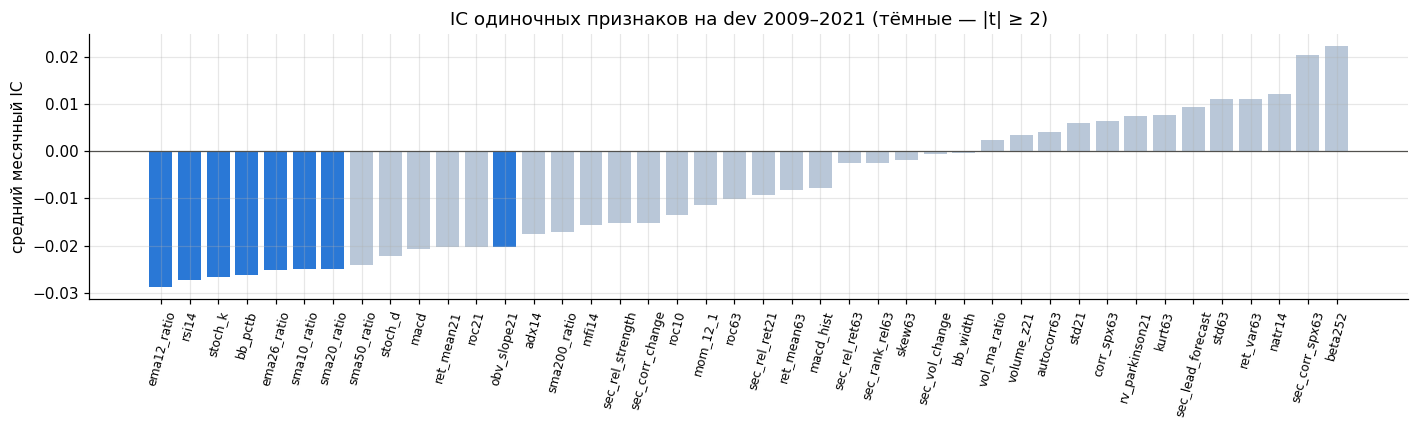

,IC (dev),t (Ньюи–Уэст),доля месяцев IC > 0
ema12_ratio,-0.029,-2.486,0.445
rsi14,-0.027,-2.265,0.465
stoch_k,-0.027,-2.460,0.458
bb_pctb,-0.026,-2.334,0.484
ema26_ratio,-0.025,-2.103,0.510
std63,0.011,0.558,0.523
ret_var63,0.011,0.558,0.523
natr14,0.012,0.611,0.523
sec_corr_spx63,0.020,1.458,0.555
beta252,0.022,0.984,0.555


In [17]:
def monthly_ic(sig, fwd):
    d = pd.concat([sig.rename("s"), fwd.rename("f")], axis=1, join="inner").dropna()
    return d.groupby(level=0).apply(lambda g: spearmanr(g["s"], g["f"])[0])


ME_ROWS = PAN[PAN["is_me"]]
_d = ME_ROWS.index.get_level_values(0)
dev_rows = ME_ROWS[(NEXT_DAY.reindex(_d).to_numpy() >= np.datetime64(OOF_START))
                   & (ME_ROWS["lab_end_tm"].to_numpy() <= np.datetime64(cutoff(DEV_END)))]
single = {}
for f in FEATS:
    ic = monthly_ic(dev_rows[f], dev_rows[FWD_COL])
    single[f] = {"IC (dev)": ic.mean(), "t (Ньюи–Уэст)": nw_t(ic), "доля месяцев IC > 0": (ic > 0).mean()}
SINGLE = pd.DataFrame(single).T.sort_values("IC (dev)")
fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(range(len(SINGLE)), SINGLE["IC (dev)"], color=[COL["ml"] if abs(t) >= 2 else "#b9c7d8" for t in SINGLE["t (Ньюи–Уэст)"]])
ax.set_xticks(range(len(SINGLE))); ax.set_xticklabels(SINGLE.index, rotation=75, fontsize=8)
ax.axhline(0, color=TEXT_SECONDARY, lw=0.8)
ax.set_ylabel("средний месячный IC"); ax.set_title("IC одиночных признаков на dev 2009–2021 (тёмные — |t| ≥ 2)")
plt.tight_layout(); plt.show()
pd.concat([SINGLE.head(5), SINGLE.tail(5)]).round(3)

### 5.2. Модели

* **Ridge** — линейная регрессия с L2-регуляризацией (α = 10) на стандартизованных признаках: простой ориентир;
* **CatBoost** (градиентный бустинг, 600 деревьев глубины 6, learning rate 0.03, L2 = 10, subsample 0.8, rsm 0.5,
  среднее двух сидов) на 42 признаках строки; отдельно — **CatBoost без 8 секторных признаков** (абляция);
* **LSTM** — последовательность признаков акции за 60 торговых дней → прогноз (32 скрытых нейрона, dropout 0.2, AdamW,
  среднее трёх сидов). Ранняя остановка — по последним 15% **дат** обучающей части; строки внутреннего обучения,
  цель которых заходит в период внутренней валидации, удаляются. Нормировка признаков, обрезка и масштаб цели
  оцениваются только по внутреннему обучению;
* **поиск похожих исторических состояний** — DTW и kNN, отдельная модель без обучаемых параметров (ниже, H5);
* **ансамбль** (основной сигнал, задан заранее) — среднее z-оценок CatBoost и LSTM по дате. Ансамбль трёх
  моделей постановки задания (DTW, CatBoost, LSTM) с разными способами взвешивания — раздел 5.4.

Гиперпараметры фиксированы заранее (не подбирались по результатам), чтобы не тратить dev на подгонку моделей.
Каждая модель обучается заново для каждого из 17 блоков (5 фолдов dev, валидация, 11 кварталов walk-forward).

In [18]:
def run_blocks(predict_fn, name, params=()):
    # прогнозы и служебные результаты (важности, коэффициенты) сохраняются одним объектом
    def go():
        parts, extra = [], {}
        for bname, a, b in BLOCKS:
            te = block_rows(PAN, a, b)
            pred, ex = predict_fn(train_rows(PAN, a), te, bname)
            parts.append(pd.DataFrame({"pred": pred, "часть": bname}, index=te.index))
            extra[bname] = ex
        return pd.concat(parts), extra
    return cached(name, go, params)


def clip_q(y, lo=None, hi=None):
    return y.clip(y.quantile(0.01) if lo is None else lo, y.quantile(0.99) if hi is None else hi)


def ridge_predict(tr, te, bname, alpha=10.0):
    mu, sd = tr[FEATS].mean(), tr[FEATS].std() + 1e-12
    z = lambda df: ((df[FEATS] - mu) / sd).clip(-5, 5).fillna(0.0).to_numpy()
    m = Ridge(alpha=alpha).fit(z(tr), clip_q(tr[TARGET]).to_numpy())
    return m.predict(z(te)), pd.Series(m.coef_, index=FEATS)


def cb_predict(tr, te, bname, feats, seeds=(0, 1)):
    y = clip_q(tr[TARGET])
    ps, imp = [], []
    for s in seeds:
        m = CatBoostRegressor(iterations=600, depth=6, learning_rate=0.03, l2_leaf_reg=10, subsample=0.8, rsm=0.5,
                              random_seed=s, verbose=0, thread_count=N_JOBS, allow_writing_files=False)
        m.fit(tr[feats], y)
        ps.append(m.predict(te[feats])); imp.append(m.get_feature_importance())
    return np.mean(ps, 0), pd.Series(np.mean(imp, 0), index=feats)


SEQ = 60


class LSTMNet(nn.Module):
    def __init__(self, nf, h=32):
        super().__init__()
        self.rnn = nn.LSTM(nf, h, batch_first=True)
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(h, 1))

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(out[:, -1]).squeeze(-1)


def lstm_predict_factory(seeds=(0, 1, 2)):
    # последовательности собираются на GPU по индексам (день, акция) без копирования в память
    F3 = torch.tensor(FEAT3, device=DEVICE)
    offs = torch.arange(-SEQ + 1, 1, device=DEVICE)

    def fn(tr, te, bname):
        tr = tr[tr.index.get_level_values(0) >= IDX[SEQ + 260]]
        tr = tr.iloc[np.argsort(tr.index.get_level_values(0).to_numpy(), kind="stable")]
        dl = tr.index.get_level_values(0)
        dates = np.sort(dl.unique())
        v0 = dates[int(len(dates) * 0.85)]                                  # внутренняя валидация — последние 15% дат
        inner = ((dl < v0) & (tr["lab_end"].to_numpy() <= np.datetime64(v0)))
        val = dl >= v0
        # нормировка признаков — только по строкам внутреннего обучения (акция × дата), а не по всей панели до границы
        di_in = torch.as_tensor(IDX.get_indexer(dl[inner]), device=F3.device)
        si_in = torch.as_tensor(TICKER_POS.get_indexer(tr.index.get_level_values(1)[inner]), device=F3.device)
        flat = F3[di_in, si_in]
        mu = torch.nanmean(flat, 0)
        sd = torch.sqrt(torch.nanmean((flat - mu) ** 2, 0)) + 1e-9
        Z = torch.nan_to_num(((F3 - mu) / sd).clamp(-5, 5))
        del flat
        y_in = tr.loc[inner, TARGET]
        lo, hi = y_in.quantile(0.01), y_in.quantile(0.99)
        ys = clip_q(y_in, lo, hi).std()
        to_t = lambda s: torch.tensor(clip_q(s, lo, hi).to_numpy() / ys, dtype=torch.float32, device=DEVICE)

        def idx(df):
            di = torch.tensor(IDX.get_indexer(df.index.get_level_values(0)), device=DEVICE)
            jj = torch.tensor([U.TIDX[t] for t in df.index.get_level_values(1)], device=DEVICE)
            return di, jj

        gather = lambda di, jj: Z[di[:, None] + offs[None, :], jj[:, None]]
        d_tr, j_tr = idx(tr[inner]); y_tr = to_t(y_in)
        d_v, j_v = idx(tr[val]); y_v = to_t(tr.loc[val, TARGET])
        dte, jte = idx(te)
        n_tr = len(d_tr)
        preds = []
        for s in seeds:
            torch.manual_seed(s); np.random.seed(s)
            net = LSTMNet(F3.shape[2]).to(DEVICE)
            opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1e-3)
            best, state, bad = np.inf, None, 0
            g = torch.Generator().manual_seed(s)

            def predict(d_, j_):
                net.eval()
                with torch.no_grad():
                    return torch.cat([net(gather(d_[i:i + 8192], j_[i:i + 8192])) for i in range(0, len(d_), 8192)])

            for ep in range(30):
                net.train()
                perm = torch.randperm(n_tr, generator=g).to(DEVICE)
                for i in range(0, n_tr, 512):
                    b = perm[i:i + 512]
                    opt.zero_grad()
                    loss = ((net(gather(d_tr[b], j_tr[b])) - y_tr[b]) ** 2).mean()
                    loss.backward(); opt.step()
                vl = ((predict(d_v, j_v) - y_v) ** 2).mean().item()
                if vl < best - 1e-5:
                    best, bad, state = vl, 0, copy.deepcopy(net.state_dict())
                else:
                    bad += 1
                    if bad >= 4:
                        break
            net.load_state_dict(state)
            preds.append(predict(dte, jte).cpu().numpy() * ys)
        return np.mean(preds, 0), {"начало внутренней валидации": v0, "строк обучения": n_tr}
    return fn


def zscore_by_date(s):
    return s.groupby(level=0).transform(lambda x: (x - x.mean()) / (x.std() + 1e-12))


P_RIDGE, _ = run_blocks(ridge_predict, "ret_ridge", ("alpha", 10.0))
P_CB, CB_EXTRA = run_blocks(partial(cb_predict, feats=FEATS), "ret_catboost", ("feats", tuple(FEATS)))
P_CB_NS, _ = run_blocks(partial(cb_predict, feats=FEATS_NOSEC), "ret_catboost_nosector", ("feats", tuple(FEATS_NOSEC)))
P_LSTM, _ = run_blocks(lstm_predict_factory(), "ret_lstm", ("seq", SEQ, "seeds", 3))
if DEVICE == "cuda":
    torch.cuda.empty_cache()
PRED = pd.DataFrame({"CatBoost": zscore_by_date(P_CB["pred"]), "LSTM": zscore_by_date(P_LSTM["pred"]),
                     "Ridge": zscore_by_date(P_RIDGE["pred"]), "CatBoost без секторных признаков": zscore_by_date(P_CB_NS["pred"]),
                     "часть": P_CB["часть"]})
SIG = {"ансамбль": zscore_by_date(PRED[["CatBoost", "LSTM"]].mean(axis=1)), "CatBoost": PRED["CatBoost"], "LSTM": PRED["LSTM"],
       "Ridge": PRED["Ridge"], "CatBoost без секторных признаков": PRED["CatBoost без секторных признаков"]}
FWD, FWD_CC, FWD_CM = PAN[FWD_COL], PAN["y_cc_xs"], PAN["y_cm_xs"]
print("прогнозов (акция × месяц):", len(PRED), "| блоки:", PRED["часть"].nunique())

прогнозов (акция × месяц): 87600 | блоки: 17


**Поиск похожих исторических состояний (H5)** (Historical Pattern Matching) — отдельная модель без обучаемых параметров:

* состояние акции — форма её цены за последние 30 торговых дней: логарифм цены относительно последнего дня,
  нормированный на разброс (уровень и масштаб движения не важны, важна форма);
* библиотека — такие же окна всех обучающих строк блока (все акции вселенной C, каждый 5-й день, та же очистка по
  концу цели, что у остальных моделей): около 55 тыс. окон в первом фолде и 416 тыс. в последнем квартале;
* сходство — **Dynamic Time Warping** (DTW) с полосой Сакое–Чибы ±3 дня: допускает небольшие сдвиги во времени, в
  отличие от поточечного сравнения. Поиск **точный**: окна библиотеки обходятся по возрастанию нижней границы DTW
  (LB_Keogh), и обход прекращается, когда граница следующего окна больше 50-го лучшего найденного расстояния, — ни
  одно из оставшихся окон ближе быть не может. Точность проверяется полным перебором на случайных запросах (ниже);
  там же для сравнения — сколько настоящих соседей нашёл бы приближённый поиск среди 300 кандидатов с наименьшей
  нижней границей;
* прогноз — средняя будущая относительная доходность 50 ближайших окон с весами 1/расстояние;
* для сравнения — тот же поиск с евклидовым расстоянием (**kNN**): показывает, даёт ли что-то сама «деформация времени».

In [19]:
WIN, DTW_R, K_NB = 30, 3, 50
LOGC = np.log(U.C.where(listed)).to_numpy()


def shape_windows(dates, tick):
    # форма цены за WIN дней до даты включительно: лог-цена минус последняя, делённая на её ст. отклонение
    di = IDX.get_indexer(dates); jj = TICKER_POS.get_indexer(tick)
    W = LOGC[di[:, None] + np.arange(-WIN + 1, 1)[None, :], jj[:, None]]
    W = W - W[:, -1:]
    s = W.std(axis=1, keepdims=True)
    ok = np.isfinite(W).all(axis=1) & (s[:, 0] > 0)
    return np.where(ok[:, None], W / np.where(s > 0, s, 1.0), 0.0), ok


@njit(parallel=True)
def lb_keogh(Q, LIB, r):
    # нижняя граница DTW (LB_Keogh) для всех пар «запрос × окно библиотеки»
    out = np.empty((Q.shape[0], LIB.shape[0])); n = Q.shape[1]
    for qi in prange(Q.shape[0]):
        U_ = np.empty(n); L_ = np.empty(n)
        for i in range(n):
            lo, hi = max(0, i - r), min(n, i + r + 1)
            U_[i] = Q[qi, lo:hi].max(); L_[i] = Q[qi, lo:hi].min()
        for li in range(LIB.shape[0]):
            s = 0.0
            for i in range(n):
                x = LIB[li, i]
                if x > U_[i]:
                    s += (x - U_[i]) ** 2
                elif x < L_[i]:
                    s += (x - L_[i]) ** 2
            out[qi, li] = s
    return out


@njit(parallel=True)
def sq_dist(Q, LIB):
    out = np.empty((Q.shape[0], LIB.shape[0]))
    for qi in prange(Q.shape[0]):
        for li in range(LIB.shape[0]):
            s = 0.0
            for i in range(Q.shape[1]):
                s += (Q[qi, i] - LIB[li, i]) ** 2
            out[qi, li] = s
    return out


@njit
def dtw_band(a, b, r):
    n = a.shape[0]
    D = np.full((n + 1, n + 1), np.inf); D[0, 0] = 0.0
    for i in range(1, n + 1):
        for j in range(max(1, i - r), min(n, i + r) + 1):
            D[i, j] = (a[i - 1] - b[j - 1]) ** 2 + min(D[i - 1, j], D[i, j - 1], D[i - 1, j - 1])
    return D[n, n]


@njit(parallel=True)
def dtw_refine(Q, LIB, cand, r):
    out = np.empty(cand.shape)
    for qi in prange(Q.shape[0]):
        for c in range(cand.shape[1]):
            out[qi, c] = dtw_band(Q[qi], LIB[cand[qi, c]], r)
    return out


@njit(parallel=True)
def dtw_knn(Q, LIB, LB, r, k):
    # точные k ближайших по DTW: кандидаты обходятся по возрастанию нижней границы LB_Keogh, обход прекращается,
    # когда граница следующего кандидата больше k-го лучшего найденного расстояния — дальше ближе быть не может
    nq = Q.shape[0]
    out_i = np.empty((nq, k), np.int64); out_d = np.empty((nq, k)); n_dtw = np.zeros(nq, np.int64)
    for qi in prange(nq):
        order = np.argsort(LB[qi])
        bd = np.full(k, np.inf); bi = np.full(k, -1, np.int64)
        worst = 0                                          # позиция наибольшего из k лучших
        for t in range(order.shape[0]):
            j = order[t]
            if LB[qi, j] > bd[worst]:
                break
            d = dtw_band(Q[qi], LIB[j], r); n_dtw[qi] += 1
            if d < bd[worst]:
                bd[worst] = d; bi[worst] = j
                for m in range(k):
                    if bd[m] > bd[worst]:
                        worst = m
        out_i[qi] = bi; out_d[qi] = bd
    return out_i, out_d, n_dtw


def pattern_predict(tr, te, bname, use_dtw=True, chunk=256):
    # библиотека — обучающие строки блока (с очисткой по концу цели), прогноз — средняя будущая относительная
    # доходность K_NB ближайших окон с весами 1/расстояние
    LIB, ok = shape_windows(tr.index.get_level_values(0), tr.index.get_level_values(1))
    y = clip_q(tr[TARGET]).to_numpy()[ok]; LIB = LIB[ok]
    Q, okq = shape_windows(te.index.get_level_values(0), te.index.get_level_values(1))
    pred = np.zeros(len(te))
    for s in range(0, len(Q), chunk):
        q = Q[s:s + chunk]
        if use_dtw:
            idx, dd, _ = dtw_knn(q, LIB, lb_keogh(q, LIB, DTW_R), DTW_R, K_NB)
        else:
            dist = sq_dist(q, LIB)
            idx = np.argpartition(dist, K_NB, axis=1)[:, :K_NB]; dd = np.take_along_axis(dist, idx, 1)
        w = 1.0 / (np.sqrt(dd) + 1e-3)
        pred[s:s + chunk] = (w * y[idx]).sum(1) / w.sum(1)
    return np.where(okq, pred, np.nan), {"окон в библиотеке": len(LIB)}


# проверка точности поиска на 40 случайных запросах первого фолда: DTW со всей библиотекой (полный перебор) против
# поиска с отсечением по LB_Keogh; для сравнения — доля настоящих 50 соседей среди 300 кандидатов с наименьшей LB
# (приближённый поиск: 50 соседей среди 300 кандидатов с наименьшей нижней границей)
_tr, _te = train_rows(PAN, BLOCKS[0][1]), block_rows(PAN, BLOCKS[0][1], BLOCKS[0][2])
_lib, _ok = shape_windows(_tr.index.get_level_values(0), _tr.index.get_level_values(1)); _lib = _lib[_ok]
_q = shape_windows(_te.index.get_level_values(0), _te.index.get_level_values(1))[0]
_q = _q[np.random.default_rng(12).choice(len(_q), 40, replace=False)]
_lb = lb_keogh(_q, _lib, DTW_R)
_, _bd, _nd = dtw_knn(_q, _lib, _lb, DTW_R, K_NB)
_full = dtw_refine(_q, _lib, np.tile(np.arange(len(_lib)), (len(_q), 1)), DTW_R)
_true = np.argsort(_full, axis=1)[:, :K_NB]
_cand = np.argpartition(_lb, 300, axis=1)[:, :300]
assert np.allclose(np.sort(_bd, axis=1), np.sort(_full, axis=1)[:, :K_NB]), "поиск с отсечением не совпал с полным перебором"
print(f"точный DTW-поиск совпал с полным перебором на {len(_q)} запросах; DTW считается для {np.median(_nd) / len(_lib):.1%} "
      f"библиотеки (медиана); 300 кандидатов по LB содержали бы {np.mean([len(set(t) & set(c)) for t, c in zip(_true, _cand)]) / K_NB:.0%} "
      f"настоящих соседей")
del _tr, _te, _lib, _full

P_DTW, DTW_EXTRA = run_blocks(pattern_predict, "ret_pattern_dtw", ("win", WIN, "r", DTW_R, "k", K_NB, "exact"))
P_KNN, _ = run_blocks(partial(pattern_predict, use_dtw=False), "ret_pattern_knn", ("win", WIN, "k", K_NB))
DTW_NAME, KNN_NAME = "DTW (похожие состояния)", "kNN (евклидово расстояние)"
for name, P_ in ((DTW_NAME, P_DTW), (KNN_NAME, P_KNN)):
    PRED[name] = zscore_by_date(P_["pred"]); SIG[name] = PRED[name]
print(f"окон в библиотеке: {DTW_EXTRA[BLOCKS[0][0]]['окон в библиотеке']} ({BLOCKS[0][0]}) — "
      f"{DTW_EXTRA[BLOCKS[-1][0]]['окон в библиотеке']} ({BLOCKS[-1][0]}); "
      f"строк без прогноза (нет полной истории 30 дней): {P_DTW['pred'].isna().mean():.2%}")

точный DTW-поиск совпал с полным перебором на 40 запросах; DTW считается для 5.6% библиотеки (медиана); 300 кандидатов по LB содержали бы 65% настоящих соседей
окон в библиотеке: 55299 (фолд 1) — 415756 (WF 2026-07-01); строк без прогноза (нет полной истории 30 дней): 0.00%


### 5.3. Качество прогноза

**IC** — средний месячный IC; **t** — его t-статистика по Ньюи–Уэсту; **спред D10 − D1** — разница средней
относительной доходности 10% акций с лучшим и 10% с худшим прогнозом за торгуемый месяц (в годовом выражении, без
издержек); **IC внутри секторов** — ранговая корреляция прогноза с фактом, посчитанная отдельно внутри каждой группы
(сектор на дату, оценённый по корреляциям, не меньше 10 акций) и усреднённая по группам с весом числа акций:
показывает, различает ли сигнал акции внутри группы. **p** — двусторонний p для t Ньюи–Уэста (3 лага, нормальное
приближение); «t (6 лагов)» — чувствительность к числу лагов; «месяцев» — число месячных IC (в валидации 24, в
walk-forward 33 — t ≈ 2 здесь лишь ориентир). Основное сравнение H1 задано заранее — IC ансамбля; строки DTW и kNN
проверяют H5, остальные строки описательные, и удачный постфактум вариант не становится подтверждённым результатом. Для сравнения — лучший одиночный
признак на dev (с выбранным на dev знаком).

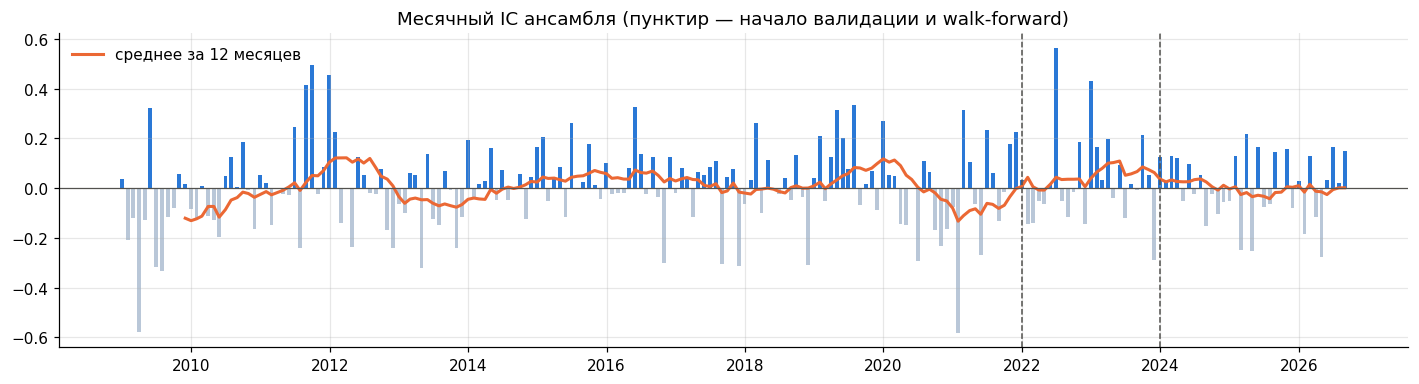

In [20]:
def part_of_dates(dates):
    return PRED["часть"].groupby(level=0).first().reindex(dates)


def decile_spread(sig, fwd):
    d = pd.concat([sig.rename("s"), fwd.rename("f")], axis=1, join="inner").dropna()
    q = d.groupby(level=0)["s"].transform(lambda x: pd.qcut(x.rank(method="first"), 10, labels=False))
    m = d.groupby([d.index.get_level_values(0), q])["f"].mean().unstack()
    return m[9] - m[0]


def monthly_ic_within(sig, fwd, min_n=10):
    # IC внутри групп: ранговая корреляция прогноза с фактом отдельно в каждой группе (сектор на дату, оценённый по
    # корреляциям) с не менее чем min_n акциями, затем среднее по группам с весом числа акций — по каждой дате
    d = pd.concat([sig.rename("s"), fwd.rename("f")], axis=1, join="inner").dropna()
    d["g"] = PAN["sector"].reindex(d.index).to_numpy()
    d = d[d["g"] >= 0]
    key = [d.index.get_level_values(0), d["g"].to_numpy()]
    rs, rf = d.groupby(key)["s"].rank(), d.groupby(key)["f"].rank()
    x = pd.DataFrame({"s": rs.to_numpy(), "f": rf.to_numpy(), "date": key[0], "g": key[1]})
    gr = x.groupby(["date", "g"])
    st = pd.DataFrame({"n": gr.size(), "c": gr.apply(lambda v: v["s"].corr(v["f"]))})
    st = st[st["n"] >= min_n].dropna()
    return st.groupby(level=0).apply(lambda v: np.average(v["c"], weights=v["n"]))


def p_norm(t):
    return 2 * (1 - scipy.stats.norm.cdf(abs(t))) if np.isfinite(t) else np.nan


best_single = SINGLE["IC (dev)"].abs().idxmax()
sign = np.sign(SINGLE.loc[best_single, "IC (dev)"])
BEST_NAME = f"лучший одиночный признак ({'−' if sign < 0 else ''}{best_single})"
SIG_ALL = {**SIG, BEST_NAME: zscore_by_date(sign * ME_ROWS[best_single]).reindex(PRED.index)}
IC_COLS = ["IC", "месяцев", "t", "p", "t (6 лагов)", "доля месяцев IC > 0", "спред D10 − D1, % в год", "IC внутри секторов"]


def ic_table(sigs, fwd=None):
    fwd = FWD if fwd is None else fwd
    rows = {}
    for name, s in sigs.items():
        ic, sp = monthly_ic(s, fwd), decile_spread(s, fwd)
        ic_w = monthly_ic_within(s, fwd)
        pp = part_of_dates(ic.index)
        for part, f in PART_OF.items():
            m = f(pp).to_numpy()
            x = ic[m]
            rows[(name, part)] = {"IC": x.mean(), "месяцев": int(np.isfinite(x).sum()), "t": nw_t(x), "p": p_norm(nw_t(x)),
                                  "t (6 лагов)": nw_t(x, lags=6), "доля месяцев IC > 0": (x > 0).mean(),
                                  "спред D10 − D1, % в год": sp.reindex(ic.index)[m].mean() * 12 * 100,
                                  "IC внутри секторов": ic_w.reindex(ic.index)[m].mean()}
    t = pd.DataFrame(rows).T.unstack(1)
    return t.reindex(columns=pd.MultiIndex.from_product([IC_COLS, list(PART_OF)]))


IC_TAB = ic_table(SIG_ALL)
display(show_tests(IC_TAB))

ic_ens = monthly_ic(SIG["ансамбль"], FWD)
fig, ax = plt.subplots(figsize=(13, 3.6))
ax.bar(ic_ens.index, ic_ens.values, width=20, color=np.where(ic_ens.values > 0, COL["ml"], "#b9c7d8"))
ax.plot(ic_ens.index, ic_ens.rolling(12).mean(), color=COL["ew"], lw=2, label="среднее за 12 месяцев")
for x_ in (DEV_END, VAL_END):
    ax.axvline(x_, color=TEXT_SECONDARY, ls="--", lw=1)
ax.axhline(0, color=TEXT_SECONDARY, lw=0.8)
ax.set_title("Месячный IC ансамбля (пунктир — начало валидации и walk-forward)"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Влияние ночного гэпа.** Чистое сравнение: две цели с **одной и той же конечной ценой** (открытие после следующей
даты решения) отличаются только началом — закрытие дня решения или открытие следующего дня, когда портфель
покупает. Разница IC — вклад ночного гэпа, который портфель получить не может. Для справки — прежняя цель
«закрытие → закрытие через 21 торговый день»: она отличается ещё и концом и длиной интервала (расстояние между
датами решения — 19–23 торговых дня).

In [21]:
GAP_SIGS = {k: SIG_ALL[k] for k in ("ансамбль", BEST_NAME)}
GAP_TAB = pd.concat({"закрытие дня решения → конец месяца": ic_table(GAP_SIGS, FWD_CM)["IC"],
                     "открытие следующего дня → конец месяца (торгуемый)": IC_TAB.loc[list(GAP_SIGS), "IC"],
                     "справочно: закрытие → закрытие через 21 день": ic_table(GAP_SIGS, FWD_CC)["IC"]}, axis=1)
GAP_TAB.round(3)

закрытие дня решения → конец месяца                        открытие следующего дня → конец месяца (торгуемый)                        справочно: закрытие → закрытие через 21 день  \
                                                                  dev (OOF) валидация walk-forward                                          dev (OOF) валидация walk-forward                                    dev (OOF)   
ансамбль                                                             -0.002     0.032        0.006                                              0.001     0.034        0.003                                        0.003   
лучший одиночный признак (−ema12_ratio)                               0.032     0.028       -0.022                                              0.028     0.025       -0.025                                        0.030   

                                                                
                                        валидация walk-forward  
ансамбль                                    0.044        0.009  
лучший одиночный признак (−ema12_ratio)     0.032       -0.025

**Важность признаков CatBoost** — модель, обученная на всём dev (блок «валидация»), среднее двух сидов
(PredictionValuesChange — средний вклад признака в изменение прогноза). Важность показывает, на что опирается модель,
но не то, что эта опора даёт прогнозную силу: это проверяет абляция без секторных признаков в таблице выше.

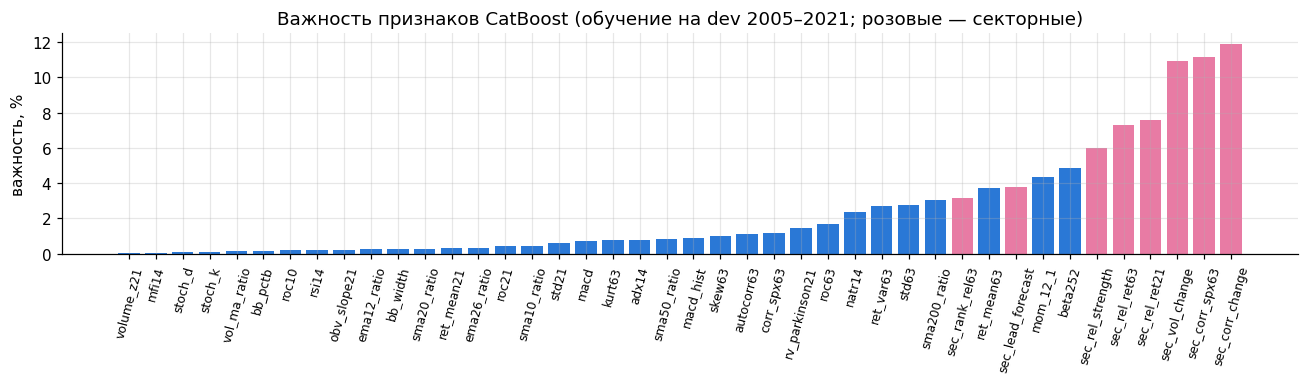

суммарная важность секторных признаков: 61.8%
топ-8: {'sec_corr_change': 11.9, 'sec_corr_spx63': 11.2, 'sec_vol_change': 10.9, 'sec_rel_ret21': 7.6, 'sec_rel_ret63': 7.3, 'sec_rel_strength': 6.0, 'beta252': 4.8, 'mom_12_1': 4.3}


In [22]:
imp = CB_EXTRA["валидация"].sort_values()
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.bar(range(len(imp)), imp.values, color=[COL["alt"] if f.startswith("sec_") else COL["ml"] for f in imp.index])
ax.set_xticks(range(len(imp))); ax.set_xticklabels(imp.index, rotation=75, fontsize=8)
ax.set_ylabel("важность, %"); ax.set_title("Важность признаков CatBoost (обучение на dev 2005–2021; розовые — секторные)")
plt.tight_layout(); plt.show()
print(f"суммарная важность секторных признаков: {imp[[f for f in imp.index if f.startswith('sec_')]].sum():.1f}%")
print("топ-8:", imp.sort_values(ascending=False).head(8).round(1).to_dict())

**Межсекторные признаки (H7).** Восемь секторных признаков раздела 5.1 (относительная доходность и сила сектора,
динамическая корреляция с рынком и её изменение, изменение волатильности, лаговый прогноз по другим секторам, ранг)
проверяются абляцией: CatBoost с ними и без них, с одинаковыми гиперпараметрами и строками обучения. Ниже — парная
разница месячных IC на одних и тех же месяцах (t Ньюи–Уэста, поправка Холма на строки таблицы) и та же разница для
IC внутри секторов: улучшают ли признаки выбор акции внутри своей группы, а не только угадывание группы.

In [23]:
ic_a, ic_b = monthly_ic(SIG["CatBoost"], FWD), monthly_ic(SIG["CatBoost без секторных признаков"], FWD)
icw_a, icw_b = monthly_ic_within(SIG["CatBoost"], FWD), monthly_ic_within(SIG["CatBoost без секторных признаков"], FWD)
rows = []
for part, f in PART_OF.items():
    for what, d in (("IC", ic_a - ic_b), ("IC внутри секторов", icw_a - icw_b)):
        x = d[f(part_of_dates(d.index)).to_numpy()]
        rows.append({"показатель": what, "период": part, "ΔIC (с секторными − без)": x.mean(), "t": nw_t(x), "p": p_norm(nw_t(x))})
SEC_TAB = pd.DataFrame(rows)
SEC_TAB["p (Холм)"] = holm(SEC_TAB["p"])
show_tests(SEC_TAB.set_index(["показатель", "период"]))

,,ΔIC (с секторными − без),t,p,p (Холм)
показатель,период,,,,
IC,dev (OOF),-0.001,-0.051,0.959,1.000
IC внутри секторов,dev (OOF),-0.009,-1.420,0.156,0.934
IC,валидация,0.020,1.327,0.185,0.934
IC внутри секторов,валидация,0.016,1.030,0.303,1.000
IC,walk-forward,-0.020,-0.840,0.401,1.000
IC внутри секторов,walk-forward,-0.006,-0.449,0.653,1.000


### 5.4. Ансамбль: устойчивость и веса моделей (H6, H9, H10)

Ансамбль из трёх моделей постановки задания — **поиск похожих состояний (DTW), CatBoost и LSTM** (в таблицах —
«ансамбль 3»). Консенсус-прогноз — взвешенная сумма z-оценок моделей по дате, снова приведённая к z-оценке. Способы
взвешивания:

* **равные веса** — по 1/3;
* **статические** — пропорционально положительной части среднего IC модели на dev (OOF), дальше не меняются;
* **адаптивные** — экспоненциальные веса по прошлой точности: `w ∝ exp(η · EWMA месячных IC модели)`. IC месяца
  становится известен только после открытия дня, следующего за следующей датой решения, то есть к решению через
  месяц, поэтому используется IC со сдвигом на 2 месяца. η ∈ {5, 20, 50} и период полураспада {3, 6, 12} месяцев
  выбираются по IC на dev;
* **RL-агент** (PPO, Stable-Baselines3, 3 сида, веса усредняются): состояние — средние известные IC моделей за 3 и
  12 месяцев, VIX, доходность S&P 500 за 63 дня и разброс месячных доходностей акций; действие — веса моделей
  (softmax); награда — IC консенсус-прогноза в этом месяце; эпизод — 36 месяцев подряд со случайным началом (последний
  допустимый месяц тоже достижим). Для валидации агент обучается
  на месяцах dev, для walk-forward — на dev и валидации (только месяцы, IC которых известен до начала периода).

Статические веса и параметры адаптивной схемы выбираются только по месяцам dev, **факт которых известен к первому
решению валидации** (31.12.2021): IC месяца решения 30.11.2021 считается по цене открытия 03.01.2022 и в выбор не
входит — та же очистка по концу цели, что у обучающих строк моделей.

На dev статические и адаптивные веса и RL-агент оцениваются на тех же месяцах, на которых выбирались или обучались, —
это не проверка; проверка — валидация и walk-forward. **Устойчивость (H6)** — разброс месячного IC, отношение
среднего IC к разбросу, худший из 17 блоков и число блоков с IC > 0: ансамбль против отдельных моделей. **Парные
тесты** — разница месячных IC двух сигналов на одних и тех же месяцах, t Ньюи–Уэста, поправка Холма на все строки
таблицы. Основной ансамбль работы (CatBoost + LSTM, раздел 5.2) задан заранее и не меняется.

In [24]:
ENS_MODELS = [DTW_NAME, "CatBoost", "LSTM"]
ZM = PRED[ENS_MODELS].fillna(0.0)
MDATES = pd.DatetimeIndex(sorted(ZM.index.get_level_values(0).unique()))
IC_M = pd.DataFrame({m: monthly_ic(ZM[m], FWD) for m in ENS_MODELS}).reindex(MDATES)
# IC месяца решения t известен только после открытия дня, следующего за решением t + 1, то есть к решению t + 2
IC_KNOWN = IC_M.shift(2)
PART_M = part_of_dates(MDATES)
DEV_M = PART_OF["dev (OOF)"](PART_M).to_numpy()
# для выбора весов и параметров на dev — только месяцы, факт которых известен к первому решению валидации:
# IC месяца решения 30.11.2021 считается по цене открытия 03.01.2022, то есть уже после решения 31.12.2021
LAB_END_M = PAN["lab_end_tm"].groupby(level=0).first().reindex(MDATES)
META_DEV = DEV_M & (LAB_END_M <= cutoff(DEV_END)).to_numpy()
assert DEV_M.sum() - META_DEV.sum() == 1 and LAB_END_M[META_DEV].max() <= cutoff(DEV_END)


def combine(wfn):
    # консенсус-прогноз: взвешенная сумма z-оценок моделей, снова приведённая к z-оценке по дате
    W = pd.DataFrame([wfn(i) for i in range(len(MDATES))], index=MDATES, columns=ENS_MODELS)
    w_rows = W.reindex(ZM.index.get_level_values(0)).to_numpy()
    return zscore_by_date(pd.Series((ZM.to_numpy() * w_rows).sum(1), index=ZM.index)), W


ic_dev = IC_M[META_DEV].mean()
W_STATIC = np.clip(ic_dev.to_numpy(), 0, None)
W_STATIC = W_STATIC / W_STATIC.sum() if W_STATIC.sum() > 0 else np.full(len(ENS_MODELS), 1 / len(ENS_MODELS))


def adaptive(eta, hl):
    past = IC_KNOWN.ewm(halflife=hl, min_periods=6).mean().to_numpy()
    def fn(i):
        x = past[i]
        if not np.isfinite(x).all():
            return np.full(len(ENS_MODELS), 1 / len(ENS_MODELS))
        e = np.exp(eta * (x - x.max()))
        return e / e.sum()
    return fn


ADAPT_GRID = {}
for eta, hl in itertools.product((5, 20, 50), (3, 6, 12)):
    s, _ = combine(adaptive(eta, hl))
    ADAPT_GRID[(eta, hl)] = monthly_ic(s, FWD).reindex(MDATES)[META_DEV].mean()
ETA, HL = max(ADAPT_GRID, key=ADAPT_GRID.get)

# RL-агент (PPO): состояние — известные к решению IC моделей (среднее за 3 и 12 месяцев) и рыночные условия
DISP = U.R.where(EC).rolling(21).sum().std(axis=1)
MKT_M = pd.DataFrame({"vix": VIX.reindex(IDX), "spx63": SPX.reindex(IDX).pct_change(63), "disp": DISP}).reindex(MDATES)
S3 = IC_KNOWN.rolling(3, min_periods=1).mean().fillna(0).to_numpy()
S12 = IC_KNOWN.rolling(12, min_periods=1).mean().fillna(0).to_numpy()
ZA = {i: ZM.loc[d].to_numpy() for i, d in enumerate(MDATES)}
FA = {i: FWD.reindex(ZM.loc[[d]].index).to_numpy() for i, d in enumerate(MDATES)}


def rl_state(i):
    m = MKT_M.iloc[i]
    return np.concatenate([S3[i] * 10, S12[i] * 10, [(m["vix"] - 20) / 10, m["spx63"] * 5, m["disp"] * 10]]).astype(np.float32)


def rank_ic(x, y):
    ok = np.isfinite(y)
    return spearmanr(x[ok], y[ok])[0] if ok.sum() >= 10 else 0.0


class EnsembleEnv(gym.Env):
    # эпизод — 36 месяцев подряд; действие — веса моделей (softmax), награда — IC консенсус-прогноза в этом месяце
    def __init__(self, months, ep_len=36, seed=0):
        super().__init__()
        self.months, self.ep_len = np.asarray(months), ep_len
        self.observation_space = gym.spaces.Box(-np.inf, np.inf, (2 * len(ENS_MODELS) + 3,), np.float32)
        self.action_space = gym.spaces.Box(-3, 3, (len(ENS_MODELS),), np.float32)
        self.rng = np.random.default_rng(seed)

    def reset(self, seed=None, options=None):
        self.k0 = self.rng.integers(0, max(1, len(self.months) - self.ep_len + 1)); self.k = 0   # +1: последний старт допустим
        return rl_state(self.months[self.k0]), {}

    def step(self, a):
        w = np.exp(a - a.max()); w /= w.sum()
        i = self.months[self.k0 + self.k]
        r = rank_ic(ZA[i] @ w, FA[i]) * 10
        self.k += 1
        done = self.k >= self.ep_len or self.k0 + self.k >= len(self.months)
        nxt = self.months[min(self.k0 + self.k, len(self.months) - 1)]
        return rl_state(nxt), float(r), done, False, {}


def train_agents(end):
    # обучение только на месяцах, IC которых известен к решению перед началом периода (месяц t — к решению t + 2)
    i_end = MDATES.searchsorted(cutoff(end))                       # первая дата решения периода
    months = np.arange(12, i_end - 1)
    out = []
    for s in SEEDS:
        env = EnsembleEnv(months, seed=s)
        ag = PPO("MlpPolicy", env, n_steps=360, batch_size=60, learning_rate=3e-4, gamma=0.9, ent_coef=0.01, seed=s,
                 verbose=0, device="cpu", policy_kwargs={"net_arch": [32, 32]})
        ag.learn(total_timesteps=40_000)
        out.append(ag.policy.state_dict())
    return out


SEEDS = [0, 1, 2]
AGENT_STATES = cached("rl_agents", lambda: {"валидация": train_agents(DEV_END), "walk-forward": train_agents(VAL_END)},
                      ("models", tuple(ENS_MODELS), "steps", 40_000, "seeds", tuple(SEEDS)))


def rl_weights():
    pol = {}
    for k, states in AGENT_STATES.items():
        pol[k] = []
        for st in states:
            ag = PPO("MlpPolicy", EnsembleEnv(np.arange(12, 24)), device="cpu", policy_kwargs={"net_arch": [32, 32]})
            ag.policy.load_state_dict(st); pol[k].append(ag)
    def fn(i):
        ag = pol["walk-forward" if MDATES[i] >= cutoff(VAL_END) else "валидация"]
        ws = []
        for a in ag:
            act, _ = a.predict(rl_state(i), deterministic=True)
            w = np.exp(act - act.max()); ws.append(w / w.sum())
        return np.mean(ws, 0)
    return fn


ENS_SIG, ENS_W = {}, {}
for name, fn in {"равные веса": lambda i: np.full(len(ENS_MODELS), 1 / len(ENS_MODELS)),
                 "статические веса": lambda i: W_STATIC, "адаптивные веса": adaptive(ETA, HL),
                 "RL-агент": rl_weights()}.items():
    ENS_SIG[f"ансамбль 3: {name}"], ENS_W[name] = combine(fn)
print("IC моделей на dev:", ic_dev.round(4).to_dict(), "→ статические веса", dict(zip(ENS_MODELS, W_STATIC.round(3))))
print("адаптивные веса, IC на dev по (η, полураспад):", {k: round(v, 4) for k, v in ADAPT_GRID.items()}, "→", (ETA, HL))

IC моделей на dev: {'DTW (похожие состояния)': 0.0124, 'CatBoost': -0.0035, 'LSTM': 0.0019} → статические веса {'DTW (похожие состояния)': 0.868, 'CatBoost': 0.0, 'LSTM': 0.132}
адаптивные веса, IC на dev по (η, полураспад): {(5, 3): 0.0053, (5, 6): 0.0049, (5, 12): 0.0049, (20, 3): 0.0075, (20, 6): 0.0049, (20, 12): 0.0038, (50, 3): 0.0088, (50, 6): 0.0036, (50, 12): 0.0004} → (50, 3)


**Устойчивость и парные тесты.** Первая таблица — качество и устойчивость отдельных моделей и ансамблей по периодам
(разброс месячного IC, IC на единицу разброса, худший из 17 блоков, число блоков с IC > 0). Вторая — парные разницы
месячных IC: H6 — ансамбль с равными весами против каждой модели, H9 — адаптивные веса против равных и статических,
H10 — RL-агент против адаптивных и равных. Ниже — веса моделей во времени у адаптивной схемы и RL-агента.

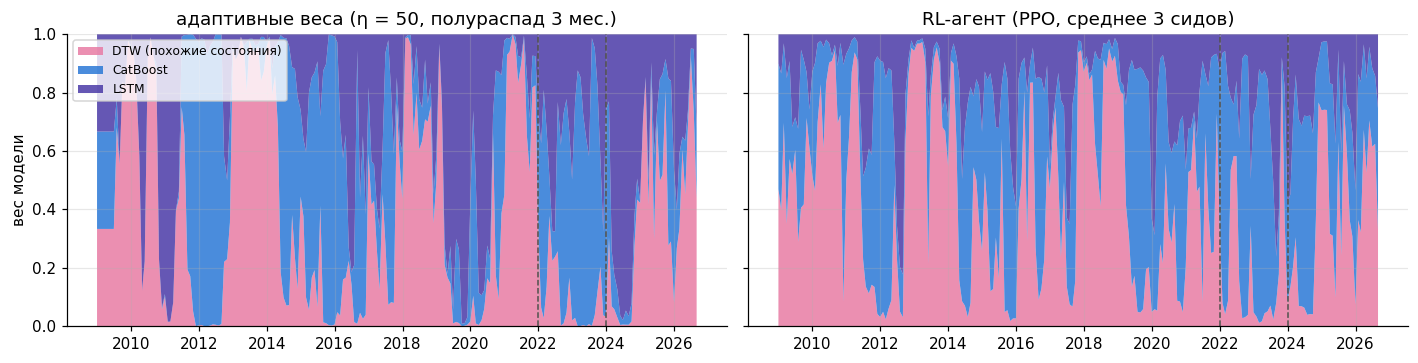

In [25]:
ENS_ALL = {**{m: SIG[m] for m in ENS_MODELS}, **ENS_SIG}
ENS_IC = pd.DataFrame({k: monthly_ic(s, FWD).reindex(MDATES) for k, s in ENS_ALL.items()})
BLK_M = PRED["часть"].groupby(level=0).first().reindex(MDATES)
rows = {}
for k in ENS_ALL:
    x = ENS_IC[k]; blk = x.groupby(BLK_M).mean()
    for part, f in PART_OF.items():
        m = f(PART_M).to_numpy()
        rows[(k, part)] = {"IC": x[m].mean(), "t": nw_t(x[m]), "ст. откл. IC": x[m].std(), "IC / ст. откл.": x[m].mean() / x[m].std(),
                           "доля месяцев IC > 0": (x[m] > 0).mean()}
    rows[(k, "все блоки")] = {"худший блок": blk.min(), "блоков с IC > 0": int((blk > 0).sum())}
ENS_TAB = pd.DataFrame(rows).T.unstack(1)
ENS_TAB = ENS_TAB[[(c, p) for c in ("IC", "t", "ст. откл. IC", "IC / ст. откл.", "доля месяцев IC > 0") for p in PART_OF]
                  + [("худший блок", "все блоки"), ("блоков с IC > 0", "все блоки")]]
display(show_tests(ENS_TAB))

EQ3, ST3, AD3, RL3 = list(ENS_SIG)
IC_PAIRS = ([("H6", EQ3, m) for m in ENS_MODELS] + [("H9", AD3, EQ3), ("H9", AD3, ST3), ("H10", RL3, AD3), ("H10", RL3, EQ3)])
rows = []
for h, a_, b_ in IC_PAIRS:
    d = (ENS_IC[a_] - ENS_IC[b_])
    for part in ("валидация", "walk-forward"):
        x = d[PART_OF[part](PART_M).to_numpy()]
        rows.append({"гипотеза": h, "сравнение": f"{a_} − {b_}", "период": part, "ΔIC": x.mean(), "t": nw_t(x), "p": p_norm(nw_t(x))})
IC_PAIR_TAB = pd.DataFrame(rows)
IC_PAIR_TAB["p (Холм)"] = holm(IC_PAIR_TAB["p"])
display(show_tests(IC_PAIR_TAB.set_index(["гипотеза", "сравнение", "период"])))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), sharey=True)
for ax, key, title in ((axes[0], "адаптивные веса", f"адаптивные веса (η = {ETA}, полураспад {HL} мес.)"),
                       (axes[1], "RL-агент", "RL-агент (PPO, среднее 3 сидов)")):
    w_ = ENS_W[key]
    ax.stackplot(w_.index, w_.T.values, labels=ENS_MODELS, colors=[COL["alt"], COL["ml"], COL["risk"]], alpha=0.85)
    for x_ in (DEV_END, VAL_END):
        ax.axvline(x_, color=TEXT_SECONDARY, ls="--", lw=1)
    ax.set_title(title); ax.set_ylim(0, 1)
axes[0].legend(loc="upper left", fontsize=8, frameon=True); axes[0].set_ylabel("вес модели")
plt.tight_layout(); plt.show()

### 5.5. Новости: FinBERT и LLM (H8)

**Данные.** Датасет FNSPID (Zihan1004/FNSPID): заголовки новостей Nasdaq.com, Benzinga и других источников по акциям
США за 04.2009 — 01.2024. Заголовки по всем 607 бумагам расчёта, в том числе выбывшим из индекса, отбираются и
оцениваются скриптом `prepare_news.py` (запускается один раз до ноутбука, исходные файлы FNSPID — около 29 ГБ;
результат — `data/news_scores.parquet`). **Новость привязывается к эмитенту по тем же правилам, что и цена**
(реестр `news_tickers.json` из раздела 2.2): переименования, интервальные правила `ALIAS` (новости IR до 03.03.2020
относятся к ряду TT, DOW до 01.09.2017 — к ряду DD, новости прежних DuPont, Johnson Controls и Chubb не используются)
и `CUT_FROM`; исходный тикер сохраняется в столбце `symbol`, соблюдение правил проверяется ниже. Каждый заголовок
оценивают две языковые модели:

* **FinBERT** (`ProsusAI/finbert`, ревизия зафиксирована в скрипте) — BERT, предобученный на BookCorpus и Wikipedia,
  дообученный на финансовых новостях Reuters (TRC2, 2008–2010) и классификации Financial PhraseBank:
  тональность = P(позитив) − P(негатив);
* **LLM** Qwen2.5-0.5B-Instruct без дообучения (zero-shot): вопрос «как новость повлияет на цену этой акции?»,
  тональность = P(«positive») − P(«negative») по вероятностям первого слова ответа.

**Без заглядывания вперёд:** торговый день новости — первая сессия NYSE, на закрытии которой новость уже известна:
для заголовков с точным временем — по календарю биржи (16:00 по Нью-Йорку, в сокращённые сессии 13:00); у
большинства заголовков FNSPID известна только дата — они относятся к первой сессии после неё (новость могла выйти
после закрытия). Признаки на дату решения строятся только по новостям до её закрытия; это проверяется инвариантом:
удаление всех новостей после даты не меняет признаки на неё. **Оговорка о знаниях моделей:** Qwen2.5 обучена на
текстах до 2024 г. и могла «видеть», как вели себя акции после этих новостей. У FinBERT финансовое дообучение — на
текстах 2008–2010 гг., но его исходная модель BERT обучалась на BookCorpus и Wikipedia (2018 г.), поэтому полностью
исключить знание более поздних событий нельзя и для него; основной вариант — FinBERT, LLM — для сравнения.

**Признаки** (по акции на дату решения): число заголовков за 21 день (лог) и его аномальность против года; средняя
тональность за 5, 21 и 63 дня; «сюрприз» — тональность за 21 день минус обычная для акции за год. Шаблонные заметки
(одинаковые начало и конец заголовка у ≥ 30 разных акций: обзоры рынка, отчёты «гуру», списки) в признаки не входят —
они часто пересказывают движение цены. Число разных акций у такого заголовка считается **нарастающим итогом**: заметка
становится шаблоном с того дня, когда ключ набрал 30 акций, и более поздние новости на прошлое не влияют. Признак
задан, если у акции за 63 дня было ≥ 3 заголовков.

**Проверка:** CatBoost раздела 5.2 с теми же гиперпараметрами и строками обучения; к 42 признакам добавляются
(1) только число новостей и его аномальность, (2) они же + тональность FinBERT, (3) они же + тональность LLM.
**Плацебо** — 10 вариантов, где тональность FinBERT перемешана между акциями с новостями внутри даты, а число новостей,
покрытие и пропуски остаются настоящими: разница «FinBERT − плацебо» измеряет вклад **содержания** заголовков, разница
«FinBERT − только число новостей» — вклад тональности сверх самого факта новостей. Блоки — фолды 2–5 dev (2012–2021; в
2009–2011 гг. новостей мало) и валидация. **Walk-forward проверить нельзя: новости FNSPID заканчиваются 09.01.2024**,
поэтому в портфели новости не входят. Сравнение — на общих строках «акция × месяц» этих блоков, где у акции есть
новости и прогноз есть у всех вариантов; месяц учитывается, если таких акций ≥ 30.

In [26]:
NEWS = pd.read_parquet(f"{DATA_DIR}/news_scores.parquet")
# сопоставление с эмитентами сделано в prepare_news.py по реестру раздела 2.2; проверка, что правила ALIAS и CUT_FROM
# соблюдены: до даты перехода новости исходного тикера стоят на ряде прежнего эмитента или не используются
for s_, (d_, prev_) in ALIAS.items():
    early = NEWS[(NEWS["symbol"] == s_) & (NEWS["time"] < pd.Timestamp(d_, tz="UTC"))]
    assert (early["ticker"] == prev_).all() if prev_ else early.empty, f"новости {s_} до {d_.date()} не по правилу"
for s_, (d_, _) in CUT_FROM.items():
    assert NEWS[(NEWS["symbol"] == s_) & (NEWS["time"] < pd.Timestamp(d_, tz="UTC"))].empty, f"новости {s_} до {d_.date()}"
NEWS = NEWS[NEWS["ticker"].isin(TICKER_POS)].reset_index(drop=True)

# торговый день новости — первая сессия NYSE, на закрытии которой новость уже известна. С точным временем: закрытие по
# календарю биржи (16:00 по Нью-Йорку, в сокращённые сессии — 13:00); новость не позже закрытия относится к этому дню,
# позже — к следующей сессии. У 99.6% заголовков FNSPID известна только дата (время 00:00 UTC): новость могла выйти
# после закрытия, поэтому она относится к первой сессии после этой даты. Решение — по закрытию дня
XNYS = exchange_calendars.get_calendar("XNYS", start=IDX[0], end=IDX[-1])
CLOSE_UTC = XNYS.schedule["close"].reindex(IDX)
assert CLOSE_UTC.notna().all(), "в ценах есть день, которого нет в календаре NYSE"
t_utc = NEWS["time"].dt.tz_convert(None)
date_only = (t_utc == t_utc.dt.normalize()).to_numpy()
di_exact = np.searchsorted(CLOSE_UTC.dt.tz_convert(None).to_numpy(), t_utc.to_numpy(), side="left")
di_date = IDX.searchsorted(t_utc.dt.normalize() + pd.Timedelta(days=1))
di_same = IDX.searchsorted(t_utc.dt.normalize())               # первая сессия не раньше даты новости
NEWS["di"] = np.where(date_only, di_date, di_exact)
print(f"заголовков с точным временем: {(~date_only).sum()}, из них после закрытия (на следующую "
      f"сессию): {(~date_only & (di_exact > di_same)).sum()}; сокращённых сессий в периоде: "
      f"{(CLOSE_UTC.dt.tz_convert('America/New_York').dt.hour < 16).sum()}")
NEWS = NEWS[NEWS["di"] < len(IDX)].reset_index(drop=True)
NEWS["j"] = TICKER_POS.get_indexer(NEWS["ticker"])

# шаблонные заголовки (обзоры рынка, отчёты «гуру», списки акций): одинаковое начало и конец заголовка без цифр у
# ≥ 30 разных акций; такие заметки часто пересказывают движение цены и в признаки не входят. Число разных акций
# считается нарастающим итогом: заголовок — шаблон, если к его торговому дню ключ уже встречался у ≥ 30 акций,
# поэтому более поздние новости на признаки более ранних дат не влияют
words = NEWS["title"].str.lower().str.replace(r"[\d$%.,:;!?'\"()\-]+", " ", regex=True).str.split()
NEWS["key"] = [" ".join(w[:2] + ["…"] + w[-2:]) if len(w) > 4 else " ".join(w) for w in words]


def template_flag(news, min_tickers=30):
    first = news.groupby(["key", "ticker"])["di"].min().reset_index().sort_values("di", kind="stable")
    first["n"] = first.groupby("key").cumcount() + 1               # разных акций у ключа к этому дню
    first = first.groupby(["key", "di"])["n"].max().reset_index()
    rows = news[["key", "di"]].reset_index().sort_values("di", kind="stable")
    m = pd.merge_asof(rows, first.sort_values("di"), on="di", by="key", direction="backward")
    return m.set_index("index")["n"].reindex(news.index).ge(min_tickers).to_numpy()


def news_arrays(news):
    out = {}
    for name, v in (("cnt", np.ones(len(news))), ("finbert", news["sent_finbert"].to_numpy(float)),
                    ("llm", news["sent_llm"].to_numpy(float))):
        a = np.zeros((len(IDX), N)); np.add.at(a, (news["di"].to_numpy(), news["j"].to_numpy()), v); out[name] = a
    return out


def news_features(news, start, end):
    # окна по торговым дням, заканчивающиеся днём решения; признак задан, если за 63 дня было ≥ 3 заголовков
    agg = news_arrays(news[~template_flag(news)])
    cs = {k: np.vstack([np.zeros((1, N)), np.cumsum(v, 0)]) for k, v in agg.items()}
    win = lambda k, w: cs[k][1:] - np.vstack([np.repeat(cs[k][:1], w - 1, axis=0), cs[k][:len(IDX) + 1 - w]])
    c = {w: win("cnt", w) for w in (5, 21, 63, 252)}
    cover = (c[63] >= 3) & (IDX >= start + pd.Timedelta(days=90))[:, None] & (IDX <= end)[:, None]
    f = {"news_cnt21": np.log1p(c[21]), "news_abnormal": (c[21] / 21) / (c[252] / 252 + 0.05)}
    with np.errstate(invalid="ignore", divide="ignore"):
        for src in ("finbert", "llm"):
            s = {w: win(src, w) / c[w] for w in (5, 21, 63, 252)}
            f |= {f"{src}_sent5": s[5], f"{src}_sent21": s[21], f"{src}_sent63": s[63], f"{src}_surprise": s[21] - s[252]}
    return {k: np.where(cover, v, np.nan) for k, v in f.items()}, cover


NEWS_START, NEWS_END = IDX[NEWS["di"].min()], IDX[NEWS["di"].max()]
NEWS["шаблон"] = template_flag(NEWS)
NF, NEWS_COVER = news_features(NEWS, NEWS_START, NEWS_END)
# инвариант причинности: если удалить все новости после дня t, признаки и покрытие на дни ≤ t не меняются
for t_cut in (pd.Timestamp("2015-12-31"), cutoff(DEV_END)):
    i_cut = IDX.get_loc(t_cut)
    nf_c, cov_c = news_features(NEWS[NEWS["di"] <= i_cut], NEWS_START, NEWS_END)
    assert (cov_c[:i_cut + 1] == NEWS_COVER[:i_cut + 1]).all()
    assert all(np.allclose(nf_c[k][:i_cut + 1], NF[k][:i_cut + 1], equal_nan=True) for k in NF), f"новости после {t_cut.date()} меняют признаки"
del nf_c, cov_c
print("проверка причинности: признаки и покрытие до 31.12.2015 и до 31.12.2021 не зависят от более поздних новостей")

_di = IDX.get_indexer(PAN.index.get_level_values(0)); _j = TICKER_POS.get_indexer(PAN.index.get_level_values(1))
for k, v in NF.items():
    PAN[k] = v[_di, _j].astype(np.float32)
PAN["news_covered"] = NEWS_COVER[_di, _j]
NEWS_BASE = ["news_cnt21", "news_abnormal"]
NEWS_FB = NEWS_BASE + ["finbert_sent5", "finbert_sent21", "finbert_sent63", "finbert_surprise"]
NEWS_LLM = NEWS_BASE + ["llm_sent5", "llm_sent21", "llm_sent63", "llm_surprise"]
ME_ROWS = PAN[PAN["is_me"]]
yr = NEWS.groupby(IDX[NEWS["di"]].year).agg(заголовков=("title", "size"), бумаг=("ticker", "nunique"),
                                            **{"доля шаблонных": ("шаблон", "mean")})
yr["акций вселенной C с новостями (медиана по датам решения)"] = (
    ME_ROWS.groupby(level=0)["news_covered"].sum().groupby(lambda d: d.year).median().reindex(yr.index))
print(f"заголовков: {len(NEWS)} по {NEWS['ticker'].nunique()} бумагам, {NEWS_START.date()} — {NEWS_END.date()} "
      f"(только дата, без времени: {date_only.mean():.1%}); перенесено на ряд прежнего эмитента: "
      f"{(NEWS['symbol'] != NEWS['ticker']).sum()} (в т. ч. переименования); "
      f"корреляция оценок FinBERT и LLM: {np.corrcoef(NEWS['sent_finbert'], NEWS['sent_llm'])[0, 1]:.2f}")
display(yr.round(2))
NEWS.sample(8, random_state=3)[["time", "symbol", "ticker", "title", "sent_finbert", "sent_llm", "шаблон"]].round(2)

заголовков с точным временем: 5056, из них после закрытия (на следующую сессию): 24; сокращённых сессий в периоде: 46


проверка причинности: признаки и покрытие до 31.12.2015 и до 31.12.2021 не зависят от более поздних новостей


заголовков: 1441944 по 557 бумагам, 2009-04-30 — 2024-01-10 (только дата, без времени: 99.6%); перенесено на ряд прежнего эмитента: 31590 (в т. ч. переименования); корреляция оценок FinBERT и LLM: 0.62


,заголовков,бумаг,доля шаблонных,акций вселенной C с новостями (медиана по датам решения)
date,,,,
2009,3744,326,0.02,0.5
2010,29011,426,0.04,229.0
2011,50390,449,0.04,258.0
2012,65714,460,0.10,289.0
2013,65309,471,0.09,302.5
2014,76493,479,0.08,313.0
2015,108414,491,0.07,326.5
2016,123600,505,0.08,349.5
2017,130515,512,0.09,374.5


,time,symbol,ticker,title,sent_finbert,sent_llm,шаблон
423537,2016-03-11 00:00:00+00:00,PG,PG,This Low Volatility ETF Is On Fire,0.24,0.99,False
1321650,2023-03-09 00:00:00+00:00,AAPL,AAPL,Apple and Foxconn efforts win labour reforms to advance Indian production plans - FT,0.81,0.90,False
907016,2019-07-13 00:00:00+00:00,DLTR,DLTR,"Barron's Picks And Pans: Dollar Tree, Expedia, Nvidia, Prudential And More",0.00,0.89,True
1029309,2020-03-12 00:00:00+00:00,STX,STX,Stocks That Hit 52-Week Lows On Thursday,-0.92,-0.55,True
1126335,2021-02-04 00:00:00+00:00,ICE,ICE,"Daily Dividend Report: ICE,APH,GLW,ROK,HSY",-0.01,0.52,False
1270547,2022-09-28 00:00:00+00:00,MS,MS,"Credit Suisse Stock Lost 21% Last Week, What's Next?",-0.83,-0.51,False
47404,2011-04-27 00:00:00+00:00,WHR,WHR,Goldman Sachs On WHR 1Q11 Results,-0.02,0.94,False
637440,2017-11-16 00:00:00+00:00,ADI,ADI,What's in the Offing for Vipshop (VIPS) This Earnings Season?,-0.19,-0.14,True


**Новости в модели.** Три варианта CatBoost и 10 плацебо обучаются на тех же блоках, что и CatBoost без новостей
раздела 5.2. Первая таблица — месячный IC вариантов на общих строках, вторая — парные разницы месячных IC
(t Ньюи–Уэста, поправка Холма на все строки таблицы), затем — доля плацебо, давших не меньший прирост, чем FinBERT.
Последняя таблица — IC каждого новостного признака по отдельности на тех же строках.

In [27]:
NEWS_BLOCKS = [blk for blk in BLOCKS if blk[0] in ("фолд 2", "фолд 3", "фолд 4", "фолд 5", "валидация")]
NEWS_PERIOD = {"фолд 2": "dev 2012–2021", "фолд 3": "dev 2012–2021", "фолд 4": "dev 2012–2021", "фолд 5": "dev 2012–2021",
               "валидация": "валидация 2022–2023"}
NPER = ["dev 2012–2021", "валидация 2022–2023"]
N_PLACEBO = 10
SENT_FB = [f for f in NEWS_FB if f not in NEWS_BASE]


def placebo_panel(seed):
    # плацебо: тональность FinBERT перемешана между акциями с новостями внутри даты; число новостей, покрытие и маска
    # пропусков остаются настоящими — разница с FinBERT измеряет вклад именно содержания заголовков
    rng = np.random.default_rng(seed)
    v = PAN[SENT_FB].to_numpy().copy()
    cov = PAN["news_covered"].to_numpy()
    for d, ix in PAN.groupby(level=0).indices.items():
        ix = ix[cov[ix]]
        v[ix] = v[ix[rng.permutation(len(ix))]]
    P = PAN.copy(); P[SENT_FB] = v
    return P


def news_runs():
    def run(P, feats):
        parts = []
        for bname, a, b in NEWS_BLOCKS:
            te = block_rows(P, a, b)
            parts.append(pd.Series(cb_predict(train_rows(P, a), te, bname, feats)[0], index=te.index))
        return pd.concat(parts)
    out = {"+ число новостей": run(PAN, FEATS + NEWS_BASE), "+ новости FinBERT": run(PAN, FEATS + NEWS_FB),
           "+ новости LLM": run(PAN, FEATS + NEWS_LLM)}
    for s in range(N_PLACEBO):
        out[f"плацебо {s}"] = run(placebo_panel(s), FEATS + NEWS_FB)
    return out


NEWS_PRED = cached("news_catboost", news_runs, (tuple(NEWS_FB), tuple(NEWS_LLM), tuple(b[0] for b in NEWS_BLOCKS),
                                               N_PLACEBO, file_sha(f"{DATA_DIR}/news_scores.parquet")))
# общие строки: прогнозы блоков NEWS_BLOCKS, у акции есть новости, прогноз есть у всех вариантов; месяц учитывается,
# если в нём ≥ 30 таких акций. Период — по названию блока, неожиданный блок — ошибка
blk_of = PRED["часть"]
rows_ok = ME_ROWS.index[ME_ROWS["news_covered"].to_numpy()]
rows_ok = rows_ok[blk_of.reindex(rows_ok).isin(NEWS_PERIOD).to_numpy()]
NSIG = {"CatBoost без новостей": P_CB["pred"], **NEWS_PRED}
common = pd.concat({k: v.reindex(rows_ok) for k, v in NSIG.items()}, axis=1).dropna()
n_m = common.groupby(level=0).size()
good = n_m.index[n_m >= 30]
common = common[common.index.get_level_values(0).isin(good)]
mper = blk_of.groupby(level=0).first().reindex(good).map(NEWS_PERIOD)
assert mper.notna().all() and set(mper) == set(NPER)
NIC = pd.DataFrame({k: monthly_ic(common[k], FWD) for k in common}).reindex(good)
PLC = [f"плацебо {s}" for s in range(N_PLACEBO)]
NIC["плацебо (среднее 10)"] = NIC[PLC].mean(axis=1)
assert NIC.notna().all().all()

COMP = [("+ число новостей", "CatBoost без новостей"), ("+ новости FinBERT", "CatBoost без новостей"),
        ("+ новости LLM", "CatBoost без новостей"), ("плацебо (среднее 10)", "CatBoost без новостей"),
        ("+ новости FinBERT", "плацебо (среднее 10)"), ("+ новости FinBERT", "+ число новостей")]
rows = []
for part in NPER:
    m = (mper == part).to_numpy()
    for k in ["CatBoost без новостей", "+ число новостей", "+ новости FinBERT", "+ новости LLM", "плацебо (среднее 10)"]:
        rows.append({"период": part, "вариант": k, "IC": NIC.loc[m, k].mean(), "t": nw_t(NIC.loc[m, k]), "месяцев": int(m.sum())})
NEWS_IC = pd.DataFrame(rows).set_index(["вариант", "период"]).unstack(1)
rows = []
for a_, b_ in COMP:
    for part in NPER:
        d = (NIC[a_] - NIC[b_])[(mper == part).to_numpy()]
        rows.append({"сравнение": f"{a_} − {b_}", "период": part, "ΔIC": d.mean(), "t": nw_t(d), "p": p_norm(nw_t(d)),
                     "месяцев": len(d)})
NEWS_TAB = pd.DataFrame(rows)
NEWS_TAB["p (Холм)"] = holm(NEWS_TAB["p"])
# где FinBERT среди 10 плацебо: доля плацебо с ΔIC к базе не ниже, чем у FinBERT
PL_RANK = {part: ((NIC.loc[(mper == part).to_numpy(), PLC].mean() - NIC.loc[(mper == part).to_numpy(), "CatBoost без новостей"].mean())
                  >= (NIC.loc[(mper == part).to_numpy(), "+ новости FinBERT"] - NIC.loc[(mper == part).to_numpy(), "CatBoost без новостей"]).mean()).mean()
           for part in NPER}
print(f"общих строк «акция × месяц»: {len(common)}; месяцев: {len(good)} ({', '.join(f'{p}: {(mper == p).sum()}' for p in NPER)}); "
      f"акций с новостями на дату решения: медиана {n_m.reindex(good).median():.0f}")
display(show_tests(NEWS_IC))
display(show_tests(NEWS_TAB.set_index(["сравнение", "период"])))
print("доля плацебо с ΔIC к базе не ниже, чем у FinBERT: " + ", ".join(f"{p}: {v:.1f}" for p, v in PL_RANK.items()))

ev = ME_ROWS.loc[common.index]
rows = {}
for f_ in NEWS_FB + NEWS_LLM[2:]:
    ic = monthly_ic(ev[f_], ev[FWD_COL]).reindex(good)
    for part in NPER:
        x = ic[(mper == part).to_numpy()]
        rows[(f_, part)] = {"IC": x.mean(), "t": nw_t(x)}
show_tests(pd.DataFrame(rows).T.unstack(1))

общих строк «акция × месяц»: 48780; месяцев: 144 (dev 2012–2021: 120, валидация 2022–2023: 24); акций с новостями на дату решения: медиана 325


доля плацебо с ΔIC к базе не ниже, чем у FinBERT: dev 2012–2021: 0.7, валидация 2022–2023: 0.5


## 6. Прогноз доходности в портфеле (H2, H9, H10)

Два способа превратить прогноз в веса:

1. **Марковиц на прогнозе:** `μ = 1% · z`, где z — z-оценка основного ансамбля (CatBoost + LSTM) по дате; та же ковариация Ледуа–Вольфа и
   ограничения, что у Minimum Variance. Неприятие риска γ ∈ {1, 3, 10, 30, 100} выбирается по Sharpe на dev. Для
   каждого γ считается и **Minimum Variance с тем же γ** (μ = 0): только эта пара отличается одним прогнозом.
2. **Наклон равных весов:** `w_i ∝ (1/N) · max(0, 1 + λ·z_i)` с ограничениями, z обрезана до ±3. При λ = 0.1 вес
   акции меняется в пределах ±30% от 1/N, при λ = 1 — от 0 до 4/N. Сглаживание — среднее z за 1 или 3 последних
   месяца (меньше оборот). λ ∈ {0, 0.1, 0.25, 0.5, 1} и сглаживание — по Sharpe на dev; **λ = 0 — отказ от
   прогноза** (портфель совпадает с Equal Weight), его тоже может выбрать dev.

In [28]:
LAMBDAS = [0.0, 0.1, 0.25, 0.5, 1.0]
SMOOTH = [1, 3]
SIG_MAIN = "ансамбль"


def signal_matrix(sig, smooth=1):
    S = sig.unstack().reindex(columns=TICKERS)
    S = S.rolling(smooth, min_periods=1).mean()
    return S.sub(S.mean(axis=1), axis=0).div(S.std(axis=1) + 1e-12, axis=0).clip(-3, 3)


def markowitz_fn(sig, gamma, scale=0.01, uni="C"):
    S = signal_matrix(sig)
    def fn(d, w0):
        e = elig(uni, d)
        z = S.loc[d].fillna(0).to_numpy() if d in S.index else np.zeros(N)
        return opt_for(uni)(d, risk_lw(d, e), w0, e, gamma=gamma, mu=scale * z)
    return fn


def tilt_fn(sig, lam, smooth=1, base=None):
    # w ∝ b · max(0, 1 + λ·z), b — равные веса или записанные целевые веса базового портфеля (словарь дата -> веса)
    S = signal_matrix(sig, smooth)
    def fn(d, w0):
        e = elig("C", d)
        b = e / e.sum() if base is None else base[d]
        z = S.loc[d].fillna(0).to_numpy() if d in S.index else np.zeros(N)
        return cap_weights(b * np.maximum(0.0, 1 + lam * z) * e, sec_mat(d))
    return fn


def active_stats(eq, eq_base):
    a = (daily_r(eq) - daily_r(eq_base)).dropna()
    return {"активная доходность": a.mean() * 252, "ошибка слежения": a.std() * np.sqrt(252),
            "IR": a.mean() / a.std() * np.sqrt(252) if a.std() > 0 else np.nan}


def ml_grids():
    dev = PERIODS[PER[0]]
    mv = {g: perf(*backtest(markowitz_fn(SIG[SIG_MAIN], g), *dev)) for g in GAMMAS}
    mvc = {g: perf(*backtest(minvar_fn(gamma=g), *dev)) for g in GAMMAS}
    grid = {}
    for lam in LAMBDAS:
        for sm in (SMOOTH if lam > 0 else [1]):
            fn = tilt_fn(SIG[SIG_MAIN], lam, sm)
            for per in PER:
                eq, to = backtest(fn, *PERIODS[per])
                grid[(lam, sm, per)] = {**perf(eq, to), **active_stats(eq, CUR_EQ[("Equal Weight", per)])}
    return mv, mvc, pd.DataFrame(grid).T.rename_axis(["λ", "сглаживание, мес.", "период"])


MV_DEV, MVC_DEV, TILT_GRID = cached("ml_portfolio_grids", ml_grids, (GAMMAS, LAMBDAS, SMOOTH, SIG_MAIN))
GAMMA = max(MV_DEV, key=lambda g: MV_DEV[g]["Sharpe"])
LAM, SM = TILT_GRID.xs(PER[0], level="период")["Sharpe"].idxmax()
print("Марковиц на прогнозе против Minimum Variance с тем же γ, dev 2009–2021:")
display(pd.DataFrame({"Sharpe: Марковиц": {g: MV_DEV[g]["Sharpe"] for g in GAMMAS},
                      "Sharpe: Minimum Variance": {g: MVC_DEV[g]["Sharpe"] for g in GAMMAS},
                      "ΔSharpe (вклад прогноза)": {g: MV_DEV[g]["Sharpe"] - MVC_DEV[g]["Sharpe"] for g in GAMMAS},
                      "оборот: Марковиц": {g: MV_DEV[g]["оборот в год"] for g in GAMMAS},
                      "оборот: Minimum Variance": {g: MVC_DEV[g]["оборот в год"] for g in GAMMAS}}).rename_axis("γ").round(3))
print(f"выбор по Sharpe на dev: Марковиц γ = {GAMMA}; наклон λ = {LAM}, сглаживание {SM} мес.")
show = TILT_GRID[["Sharpe", "оборот в год", "активная доходность", "IR"]].unstack("период")
show = show[[(k, p) for p in PER for k in ("Sharpe", "оборот в год", "активная доходность", "IR")]]
show.columns = pd.MultiIndex.from_tuples([(p, k) for k, p in show.columns])
show.round(3)

Марковиц на прогнозе против Minimum Variance с тем же γ, dev 2009–2021:


,Sharpe: Марковиц,Sharpe: Minimum Variance,ΔSharpe (вклад прогноза),оборот: Марковиц,оборот: Minimum Variance
γ,,,,,
1,0.802,0.999,-0.197,17.656,0.273
3,0.843,1.019,-0.176,17.404,0.499
10,0.940,0.921,0.019,16.155,1.358
30,0.914,0.933,-0.019,12.933,2.384
100,0.908,0.937,-0.030,8.305,3.507


выбор по Sharpe на dev: Марковиц γ = 10; наклон λ = 0.0, сглаживание 1 мес.


dev 2009–2021                                         валидация 2022–2023                                         walk-forward 2024–2026                                        
                              Sharpe оборот в год активная доходность     IR              Sharpe оборот в год активная доходность     IR                 Sharpe оборот в год активная доходность     IR
λ    сглаживание, мес.                                                                                                                                                                                 
0.00 1                         0.905        0.736               0.000    NaN               0.155        1.186               0.000    NaN                  0.899        1.128               0.000    NaN
0.10 1                         0.901        1.271              -0.001 -0.270               0.163        1.768               0.002  0.377                  0.892        1.683              -0.001 -0.120
     3                         0.900        0.944              -0.002 -0.341               0.156        1.405               0.000  0.093                  0.913        1.376               0.002  0.373
0.25 1                         0.892        2.555              -0.004 -0.306               0.174        2.985               0.005  0.352                  0.876        2.958              -0.002 -0.149
     3                         0.890        1.559              -0.004 -0.366               0.156        1.978               0.001  0.077                  0.930        2.014               0.004  0.354
0.50 1                         0.876        4.676              -0.008 -0.315               0.200        4.960               0.011  0.443                  0.853        5.134              -0.004 -0.131
     3                         0.870        2.659              -0.009 -0.399               0.154        2.984               0.002  0.062                  0.956        3.202               0.009  0.373
1.00 1                         0.851        7.582              -0.013 -0.310               0.230        7.603               0.019  0.467                  0.830        8.053              -0.003 -0.082
     3                         0.842        4.241              -0.016 -0.423               0.159        4.445               0.004  0.095                  0.996        4.850               0.015  0.414

In [29]:
MV_NAME = f"Марковиц на прогнозе (γ = {GAMMA})"
MVC_NAME = "Minimum Variance" if GAMMA == GAMMA_MINVAR else f"Minimum Variance (γ = {GAMMA})"
TILT_NAME = (f"EW + наклон по прогнозу (λ = {LAM}, сглаж. {SM})" if LAM > 0 else "EW + наклон: dev выбрал λ = 0 (без прогноза)")
ML_STRATS = {MV_NAME: markowitz_fn(SIG[SIG_MAIN], GAMMA), TILT_NAME: tilt_fn(SIG[SIG_MAIN], LAM, SM)}


def run_ml():
    res, cur, recs = {}, {}, {}
    for name, fn in {**ML_STRATS, MVC_NAME: minvar_fn(gamma=GAMMA)}.items():
        for per in PER:
            rec = {}
            eq, to = backtest(fn, *PERIODS[per], record=rec)
            res[(name, per)], cur[(name, per)], recs[(name, per)] = perf(eq, to), eq, rec
    return res, cur, recs


r_, c_, ML_REC = cached("ml_portfolios", run_ml, (GAMMA, LAM, SM, SIG_MAIN))
RES.update(r_); CUR_EQ.update(c_)
H2_NAMES = list(dict.fromkeys(["Equal Weight", "Minimum Variance", MVC_NAME, MV_NAME, TILT_NAME]))
display(res_table(H2_NAMES).round(3))
dist = {per: np.mean([np.abs(ML_REC[(MV_NAME, per)][d] - ML_REC[(MVC_NAME, per)][d]).sum() for d in ML_REC[(MV_NAME, per)]])
        for per in PER}
print(f"насколько прогноз меняет портфель: средняя L1-разница весов «{MV_NAME}» и «{MVC_NAME}» на дату решения: "
      + ", ".join(f"{p}: {v:.2f}" for p, v in dist.items()) + " (2.0 — полностью разные портфели)")
# при λ = 0 наклон совпадает с Equal Weight: такое сравнение вырождено и не включается в таблицу и поправку Холма
H2_PAIRS = [(MV_NAME, MVC_NAME)] + ([(TILT_NAME, "Equal Weight")] if LAM > 0 else []) + ([(MV_NAME, "Minimum Variance")] if MVC_NAME != "Minimum Variance" else [])
H2_TESTS = sharpe_tests(H2_PAIRS)
show_tests(H2_TESTS)

dev 2009–2021                                                      валидация 2022–2023                                                      walk-forward 2024–2026  \
                                                      CAGR волатильность Sharpe Sharpe изб.  MaxDD оборот в год                CAGR волатильность Sharpe Sharpe изб.  MaxDD оборот в год                   CAGR   
Equal Weight                                         0.177         0.202  0.905       0.882 -0.396        0.736               0.011         0.192  0.155      -0.028 -0.215        1.186                  0.122   
Minimum Variance                                     0.120         0.132  0.921       0.886 -0.336        1.358              -0.037         0.131 -0.221      -0.488 -0.165        2.060                  0.156   
Марковиц на прогнозе (γ = 10)                        0.153         0.166  0.940       0.912 -0.360       16.155              -0.029         0.187 -0.064      -0.252 -0.220       16.354                  0.067   
EW + наклон: dev выбрал λ = 0 (без прогноза)         0.177         0.202  0.905       0.882 -0.396        0.736               0.011         0.192  0.155      -0.028 -0.215        1.186                  0.122   

                                                                                                   
                                             волатильность Sharpe Sharpe изб.  MaxDD оборот в год  
Equal Weight                                         0.139  0.899       0.592 -0.178        1.128  
Minimum Variance                                     0.098  1.525       1.089 -0.100        1.550  
Марковиц на прогнозе (γ = 10)                        0.141  0.532       0.229 -0.134       16.117  
EW + наклон: dev выбрал λ = 0 (без прогноза)         0.139  0.899       0.592 -0.178        1.128

насколько прогноз меняет портфель: средняя L1-разница весов «Марковиц на прогнозе (γ = 10)» и «Minimum Variance» на дату решения: dev 2009–2021: 1.59, валидация 2022–2023: 1.65, walk-forward 2024–2026: 1.69 (2.0 — полностью разные портфели)


**Портфели на ансамблях с разными весами (H9, H10).** Консенсус-прогнозы раздела 5.4 подаются в тот же Марковиц с γ,
выбранным на dev для основного ансамбля; сравнение — с Minimum Variance с тем же γ и между способами взвешивания. На dev
статические и адаптивные веса и RL-агент — внутри выборки.

In [30]:
ENS_PORT = {f"Марковиц, {k}": v for k, v in ENS_SIG.items()}


def run_ens_portfolios():
    return run_strats({k: markowitz_fn(s, GAMMA) for k, s in ENS_PORT.items()})


r_, c_ = cached("ens_portfolios", run_ens_portfolios, (GAMMA, tuple(ENS_PORT)))
RES.update(r_); CUR_EQ.update(c_)
EP = list(ENS_PORT)
display(res_table([MVC_NAME, MV_NAME] + EP).round(3))
ENS_PORT_TESTS = sharpe_tests([(k, MVC_NAME) for k in EP] + [(EP[2], EP[0]), (EP[3], EP[2])])
show_tests(ENS_PORT_TESTS)

dev 2009–2021                                                      валидация 2022–2023                                                      walk-forward 2024–2026                \
                                                CAGR волатильность Sharpe Sharpe изб.  MaxDD оборот в год                CAGR волатильность Sharpe Sharpe изб.  MaxDD оборот в год                   CAGR волатильность   
Minimum Variance                               0.120         0.132  0.921       0.886 -0.336        1.358              -0.037         0.131 -0.221      -0.488 -0.165        2.060                  0.156         0.098   
Марковиц на прогнозе (γ = 10)                  0.153         0.166  0.940       0.912 -0.360       16.155              -0.029         0.187 -0.064      -0.252 -0.220       16.354                  0.067         0.141   
Марковиц, ансамбль 3: равные веса              0.161         0.160  1.013       0.984 -0.351       19.420              -0.018         0.178 -0.012      -0.209 -0.219       20.969                  0.045         0.138   
Марковиц, ансамбль 3: статические веса         0.166         0.154  1.071       1.041 -0.296       21.190              -0.054         0.164 -0.258      -0.472 -0.203       22.478                  0.039         0.139   
Марковиц, ансамбль 3: адаптивные веса          0.158         0.163  0.981       0.953 -0.365       19.040              -0.071         0.181 -0.316      -0.510 -0.259       17.272                  0.097         0.138   
Марковиц, ансамбль 3: RL-агент                 0.153         0.164  0.954       0.926 -0.369       19.500              -0.060         0.174 -0.269      -0.471 -0.240       18.194                  0.085         0.135   

                                                                               
                                       Sharpe Sharpe изб.  MaxDD оборот в год  
Minimum Variance                        1.525       1.089 -0.100        1.550  
Марковиц на прогнозе (γ = 10)           0.532       0.229 -0.134       16.117  
Марковиц, ансамбль 3: равные веса       0.389       0.079 -0.159       19.728  
Марковиц, ансамбль 3: статические веса  0.344       0.036 -0.159       22.413  
Марковиц, ансамбль 3: адаптивные веса   0.741       0.431 -0.181       19.816  
Марковиц, ансамбль 3: RL-агент          0.672       0.357 -0.146       20.084

**Перестановочный тест сигнала.** Отвечает на вопрос «есть ли в прогнозе информация», отдельно от вопроса «достаточно
ли её, чтобы обогнать эталон». Чтобы не зависеть от выбора λ на dev, тест проводится для заранее заданного сильного
наклона λ = 1 (без сглаживания). Прогноз перемешивается между акциями внутри каждого месяца — по всем акциям или
только внутри сектора (сохраняет секторную структуру, проверяет информацию сверх секторов), 200 повторов; всё
остальное то же. p = (k + 1)/(n + 1), где k — число перемешиваний с активной доходностью против Equal Weight не ниже
настоящей; минимально возможное p при 200 повторах — 0.005. Перемешивание меняет не только связь прогноза с
доходностью, но и устойчивость сигнала во времени, а значит оборот и комиссии. Поэтому показаны активная доходность
**до и после комиссий** и оборот: p до комиссий проверяет прогнозную связь без вклада издержек, p после комиссий —
экономический эффект. Перестановка внутри месяца предполагает, что акции в месяце (или в группе) взаимозаменяемы.

In [31]:
LAM_PERM = 1.0


def shuffle_signal(sig, rng, groups):
    # перестановка значений внутри групп (дата или дата × сектор), векторно
    order = np.lexsort((np.arange(len(sig)), groups))
    order_r = np.lexsort((rng.random(len(sig)), groups))
    v = sig.to_numpy(); out = np.empty_like(v)
    out[order] = v[order_r]
    return pd.Series(out, index=sig.index)


def tilt_permutation(sig, n=200, seed=1):
    rng = np.random.default_rng(seed)
    dates = pd.factorize(sig.index.get_level_values(0))[0]
    sec = PAN["sector"].reindex(sig.index).to_numpy()
    groups = {"по всем акциям": dates, "внутри секторов": dates * (len(SECTORS) + 2) + (sec + 1)}
    eq_ew0 = {per: backtest(BASE["Equal Weight"], *PERIODS[per], fee=0.0)[0] for per in PER}

    def act(fn, per):
        # активная доходность к Equal Weight после комиссий и до них (тот же бэктест с нулевой комиссией) и оборот в год
        eq, to = backtest(fn, *PERIODS[per])
        eq0, _ = backtest(fn, *PERIODS[per], fee=0.0)
        return (active_stats(eq, CUR_EQ[("Equal Weight", per)])["активная доходность"],
                active_stats(eq0, eq_ew0[per])["активная доходность"], to.sum() / (len(eq) / 252))

    real = {per: act(tilt_fn(sig, LAM_PERM, 1), per) for per in PER}
    rows = {}
    for gname, g in groups.items():
        sims = {per: [] for per in PER}
        for _ in range(n):
            fn = tilt_fn(shuffle_signal(sig, rng, g), LAM_PERM, 1)
            for per in PER:
                sims[per].append(act(fn, per))
        for per in PER:
            s_ = np.array(sims[per])
            rows[(gname, per)] = {"после комиссий: факт": real[per][0], "после: медиана перемешанных": np.median(s_[:, 0]),
                                  "p после комиссий": ((s_[:, 0] >= real[per][0]).sum() + 1) / (n + 1),
                                  "до комиссий: факт": real[per][1], "до: медиана перемешанных": np.median(s_[:, 1]),
                                  "p до комиссий": ((s_[:, 1] >= real[per][1]).sum() + 1) / (n + 1),
                                  "оборот: факт": real[per][2], "оборот: медиана перемешанных": np.median(s_[:, 2])}
    return pd.DataFrame(rows).T


PERM = cached("perm_tilt", lambda: tilt_permutation(SIG[SIG_MAIN]), (LAM_PERM, SIG_MAIN, 200))
display(PERM.style.format({c_: ("{:.3f}" if c_.startswith("p") else "{:.2f}" if c_.startswith("оборот") else "{:+.4f}")
                           for c_ in PERM.columns}))

**Чувствительность к издержкам.** Те же стратегии (оптимизатор по-прежнему штрафует оборот по 0.10%) пересчитываются
при других издержках бэктеста — это проверка устойчивости фиксированной стратегии, а не её переподбор.

In [32]:
def fee_sensitivity():
    # при γ = 10 MVC_NAME — это сам Minimum Variance; при λ = 0 наклон совпадает с Equal Weight и в таблицу не входит
    strats = {"Equal Weight": BASE["Equal Weight"], "Minimum Variance": BASE["Minimum Variance"]}
    if MVC_NAME not in strats:
        strats[MVC_NAME] = minvar_fn(gamma=GAMMA)
    strats |= {k: v for k, v in ML_STRATS.items() if k != TILT_NAME or LAM > 0}
    rows = {}
    for fee in (0.0, 0.001, 0.002):
        for name, fn in strats.items():
            for per in PER[1:]:
                rows[(name, f"{fee:.2%}", per)] = (RES[(name, per)]["Sharpe"] if fee == FEE else
                                                   perf(*backtest(fn, *PERIODS[per], fee=fee))["Sharpe"])
    return pd.Series(rows).unstack([2, 1])


FEE_TAB = cached("fee_sensitivity", fee_sensitivity, (GAMMA, LAM, SM, SIG_MAIN))
print("Sharpe при разных издержках:")
FEE_TAB.round(2)

Sharpe при разных издержках:


,валидация 2022–2023,walk-forward 2024–2026,валидация 2022–2023,walk-forward 2024–2026,валидация 2022–2023,walk-forward 2024–2026
,0.00%,0.00%,0.10%,0.10%,0.20%,0.20%
Equal Weight,0.16,0.91,0.15,0.90,0.15,0.89
Minimum Variance,-0.21,1.54,-0.22,1.52,-0.24,1.51
Марковиц на прогнозе (γ = 10),0.02,0.65,-0.06,0.53,-0.15,0.42


## 7. Прогноз риска (H3)

### 7.1. Прогноз волатильности акции на следующий месяц

Цель — логарифм реализованной волатильности дневных доходностей (закрытие к закрытию) за следующие 21 торговый день.
Модели:

| модель | как устроена |
|---|---|
| история 63 и 252 дней | стандартное отклонение за прошлые дни |
| EWMA | RiskMetrics, λ = 0.94 |
| GARCH(1,1) | по каждой акции; параметры оцениваются методом максимального правдоподобия раз в год на всей истории до 1 января, фильтр стартует с дисперсии этой истории; при неудаче оценки — параметры прошлого года; прогноз — средняя дисперсия на 21 день вперёд |
| HAR | регрессия лог-волатильности на дневную, недельную, месячную и квартальную волатильность Паркинсона (по high/low); одна на все акции (Corsi, 2009) |
| HAR (закрытие к закрытию) | то же на волатильностях дневных доходностей закрытие к закрытию: в отличие от Паркинсона, учитывает ночной риск так же, как цель |
| CatBoost | 15 признаков: волатильности разных окон и типов, GARCH, нисходящая волатильность, доходности за 21 и 63 дня (эффект рычага), волатильность сектора и рынка, VIX |

HAR и CatBoost обучаются по тем же блокам и на тех же строках вселенной C, что модели доходности, с той же очисткой
по концу цели. Прогноз логарифма смещён относительно дисперсии, поэтому **все** прогнозы калибруются одним
множителем на обучающих данных. У CatBoost множитель оценивается по его прогнозам вне выборки на последовательных
расширяющихся фолдах внутри обучения (с очисткой по концу цели); для сравнения показан и вариант без калибровки.

**Метрики** считаются на **общих строках**, где есть факт и прогнозы всех моделей; каждый месяц весит одинаково:
QLIKE `σ²/σ̂² − ln(σ²/σ̂²) − 1` — функция потерь для прогнозов дисперсии, устойчивая к шуму в оценке реализованной
волатильности (Patton, 2011; меньше — лучше); R² логарифма волатильности (по всем строкам, поэтому поздние месяцы с
большим числом акций весят в нём больше); ранговая корреляция прогноза и факта между акциями; **t (Ньюи–Уэст)** — тест
Диболда–Мариано разницы QLIKE с «историей 252 дня» по месяцам (t < −2 — ориентир значимого улучшения). Лучшая модель
выбирается по QLIKE на dev. Цель — волатильность «закрытие → закрытие» за 21 день: это приближение к риску
портфеля, который держится от открытия до открытия.

In [33]:
@njit(nogil=True)
def garch_nll(p, r):
    w, a, b = p[0], p[1], p[2]
    s2 = np.mean(r * r); nll = 0.0
    for t in range(r.shape[0]):
        nll += np.log(s2) + r[t] * r[t] / s2
        s2 = w + a * r[t] * r[t] + b * s2
    return 0.5 * nll


@njit(nogil=True)
def garch_filter(p, r, s2_0):
    # σ²_{t+1} после наблюдения r_t
    w, a, b = p[0], p[1], p[2]
    out = np.empty(r.shape[0]); s2 = s2_0
    for t in range(r.shape[0]):
        s2 = w + a * r[t] * r[t] + b * s2
        out[t] = s2
    return out


def garch_fit(r):
    v = r.var()
    cons = [{"type": "ineq", "fun": lambda p: 0.999 - p[1] - p[2]}]
    with warnings.catch_warnings():    # SLSQP сообщает, что обрезал шаг до границ, — штатное поведение, не ошибка
        warnings.filterwarnings("ignore", message="Values in x were outside bounds")
        res = minimize(garch_nll, np.array([v * 0.05, 0.08, 0.9]), args=(r,), method="SLSQP", constraints=cons,
                       bounds=[(1e-6 * v, 10 * v), (0.0, 0.5), (0.0, 0.999)])
    ok = bool(res.success) and np.isfinite(res.fun) and np.isfinite(res.x).all() and res.x[1] + res.x[2] <= 0.999 + 1e-6
    return res.x, ok


def garch_one(j):
    # GARCH(1,1) одной акции: параметры переоцениваются раз в год на всей истории до 1 января (без заглядывания вперёд)
    t = TICKERS[j]
    out = np.full(len(IDX), np.nan)
    r_all = (U.R[t] * 100).fillna(0.0)
    ok = U.R[t].notna().to_numpy()
    p_prev, fails = None, 0
    for y in range(2006, WF_END.year + 1):
        hist = r_all[(r_all.index < f"{y}-01-01") & ok]
        if len(hist) < 500:
            continue
        p, good = garch_fit(hist.to_numpy())
        if not good:
            fails += 1
            if p_prev is None:
                continue                                   # прогноза нет: в портфеле его заменит историческая оценка
            p = p_prev
        p_prev = p
        s2_next = garch_filter(p, r_all.to_numpy(), hist.var())   # фильтр причинный, старт — дисперсия прошлой истории
        phi = min(p[1] + p[2], 0.999); lr = p[0] / (1 - phi)
        avg = lr + (s2_next - lr) * (1 - phi ** HORIZON) / ((1 - phi) * HORIZON)     # средняя дисперсия на 21 день
        m = (IDX >= f"{y}-01-01") & (IDX < f"{y + 1}-01-01")
        out[m] = np.sqrt(avg[m]) / 100
    return out, fails


def garch_all():
    # потоки, а не процессы: функции numba с nogil=True отпускают GIL, а большая часть времени — в них
    with ThreadPoolExecutor(N_JOBS) as ex:
        res = list(ex.map(garch_one, range(N)))
    G = pd.DataFrame(np.column_stack([r[0] for r in res]), index=IDX, columns=TICKERS).where(listed & U.R.notna().cummax())
    return G, sum(r[1] for r in res)


G, GARCH_FAILS = cached("garch", garch_all)
print(f"GARCH: неудачных оценок параметров {GARCH_FAILS} (заменены параметрами прошлого года)")


def vol_features():
    with quiet():
        park = (np.log(U.H / U.L) ** 2) / (4 * np.log(2))
        park = park.where(park > 0)
        lg = lambda x: np.log(x.clip(lower=1e-10))
        mkt21 = spx_r.rolling(21).std()
        sec_v = np.stack([U.SR[s].rolling(21).std().to_numpy() for s in SECTORS], axis=1)
        F = {"lv_park1": lg(park.rolling(1).mean()) / 2, "lv_park5": lg(park.rolling(5).mean()) / 2,
             "lv_park21": lg(park.rolling(21).mean()) / 2, "lv_park63": lg(park.rolling(63).mean()) / 2,
             "lv_abs1": lg(U.R.abs().clip(lower=1e-4)), "lv_cc5": lg(U.R.rolling(5).std()),
             "lv_cc21": lg(U.R.rolling(21).std()), "lv_cc63": lg(U.R.rolling(63).std()), "lv_cc252": lg(U.R.rolling(252).std()),
             "lv_ewma": lg(np.sqrt((U.R ** 2).ewm(alpha=0.06, adjust=False).mean())), "lv_garch": lg(G),
             "lv_down63": lg(np.sqrt((U.R.clip(upper=0) ** 2).rolling(63).mean())),
             "ret21": U.C.pct_change(21, fill_method=None), "ret63": U.C.pct_change(63, fill_method=None),
             "lv_sector21": lg(pd.DataFrame(gather_sector(sec_v), index=IDX, columns=TICKERS)),
             "lv_mkt21": lg(pd.DataFrame({t: mkt21 for t in TICKERS})),
             "l_vix": pd.DataFrame({t: np.log(VIX / 100 / np.sqrt(252)) for t in TICKERS})}
        F["y"] = lg(U.R.rolling(HORIZON).std().shift(-HORIZON))         # лог реализованной волатильности следующих 21 дня
    lab = np.full(len(IDX), np.datetime64("NaT"), "datetime64[ns]"); lab[:-HORIZON] = IDX[HORIZON:].to_numpy()
    di = np.flatnonzero(IDX.isin(U.WEEKLY) | IDX.isin(U.ME))
    keep = ELIG["C"][di].reshape(-1)
    rows = pd.MultiIndex.from_product([IDX[di], TICKERS], names=["date", "ticker"])
    P = pd.DataFrame({k: v.reindex(columns=TICKERS).to_numpy()[di].reshape(-1) for k, v in F.items()}, index=rows)
    P["lab_end"] = np.repeat(lab[di], N)
    P = P[keep]
    d = P.index.get_level_values(0)
    P["is_me"], P["is_w"] = d.isin(U.ME), d.isin(U.WEEKLY)
    return P


HAR_F = ["lv_park1", "lv_park5", "lv_park21", "lv_park63"]
HAR_CC_F = ["lv_abs1", "lv_cc5", "lv_cc21", "lv_cc63"]
VOL_F = HAR_F + ["lv_cc21", "lv_cc63", "lv_cc252", "lv_ewma", "lv_garch", "lv_down63", "ret21", "ret63",
                 "lv_sector21", "lv_mkt21", "l_vix"]
SIMPLE_VOL = {"история 63 дня": "lv_cc63", "история 252 дня": "lv_cc252", "EWMA (λ = 0.94)": "lv_ewma", "GARCH(1,1)": "lv_garch"}
VOL_MODELS = list(SIMPLE_VOL) + ["HAR", "HAR (закрытие к закрытию)", "CatBoost", "CatBoost без калибровки"]
VOL_BASE = "история 252 дня"
VP = vol_features()
print("очистка по концу цели для моделей риска:")
display(purge_check(VP, "y").iloc[[0, 5, 6, -1]])


def vol_models():
    calib = lambda y, p: 0.5 * np.log(np.mean(np.exp(2 * (y - p))))
    cb = lambda seed: CatBoostRegressor(iterations=500, depth=6, learning_rate=0.05, l2_leaf_reg=10, subsample=0.8,
                                        rsm=0.7, random_seed=seed, verbose=0, thread_count=N_JOBS,
                                        allow_writing_files=False)
    out = []
    for bname, a, b in BLOCKS:
        tr = train_rows(VP, a, "y").dropna(subset=["lv_garch"] + HAR_F + HAR_CC_F)
        te = block_rows(VP, a, b)
        P = pd.DataFrame(index=te.index)
        y = tr["y"].to_numpy()
        for name, f_ in SIMPLE_VOL.items():
            P[name] = te[f_] + calib(y, tr[f_].to_numpy())
        for name, fs in (("HAR", HAR_F), ("HAR (закрытие к закрытию)", HAR_CC_F)):
            X = np.c_[np.ones(len(tr)), tr[fs].to_numpy()]
            beta = np.linalg.lstsq(X, y, rcond=None)[0]
            P[name] = np.c_[np.ones(len(te)), te[fs].to_numpy()] @ beta + calib(y, X @ beta)
        raw = np.mean([cb(s).fit(tr[VOL_F], y).predict(te[VOL_F]) for s in (0, 1)], 0)
        # калибровка CatBoost — по прогнозам вне выборки на последовательных расширяющихся фолдах внутри обучения
        dl = tr.index.get_level_values(0)
        dts = np.sort(dl.unique())
        bnd = [dts[int(len(dts) * q)] for q in (0.4, 0.6, 0.8)] + [None]
        oos, yo = [], []
        for c0, c1 in zip(bnd[:-1], bnd[1:]):
            fit_m = (dl < c0) & (tr["lab_end"].to_numpy() < np.datetime64(c0))
            pr_m = (dl >= c0) & ((dl < c1) if c1 is not None else True)
            oos.append(cb(0).fit(tr.loc[fit_m, VOL_F], y[fit_m]).predict(tr.loc[pr_m, VOL_F])); yo.append(y[pr_m])
        P["CatBoost без калибровки"] = raw
        P["CatBoost"] = raw + calib(np.concatenate(yo), np.concatenate(oos))
        P["часть"] = bname
        out.append(P)
    return pd.concat(out)


def vol_eval(VPRED, models=VOL_MODELS):
    y = VP["y"].reindex(VPRED.index)
    have = VPRED[models].notna()
    common = y.notna() & have.all(axis=1)
    rows, cover = [], {}
    for part, f in PART_OF.items():
        inpart = f(VPRED["часть"])
        cover[part] = {**have[inpart & y.notna()].mean().to_dict(), "общие строки": common[inpart & y.notna()].mean()}
        m_ = (inpart & common).to_numpy()
        yy, sub = y[m_], VPRED[m_]
        qm = {m: (np.exp(2 * (yy - sub[m])) - 2 * (yy - sub[m]) - 1).groupby(level=0).mean() for m in models}
        for m in models:
            e = yy - sub[m]
            cs = (pd.concat([sub[m].rename("f"), yy.rename("y")], axis=1).groupby(level=0)
                  .apply(lambda g: spearmanr(g["f"], g["y"])[0]))
            dq = qm[m] - qm[VOL_BASE]
            rows.append({"модель": m, "часть": part, "QLIKE": qm[m].mean(),
                         "R² лог-вол.": 1 - (e ** 2).sum() / ((yy - yy.mean()) ** 2).sum(),
                         "ранговая корр. по акциям": cs.mean(),
                         f"ΔQLIKE к «{VOL_BASE}»": dq.mean(),
                         "t (Ньюи–Уэст)": nw_t(dq) if m != VOL_BASE else np.nan})
    t = pd.DataFrame(rows).set_index(["модель", "часть"]).unstack(1)
    cols = list(pd.DataFrame(rows).columns[2:])
    return (t.reindex(columns=pd.MultiIndex.from_product([cols, list(PART_OF)])).reindex(models),
            pd.DataFrame(cover).T)


VPRED = cached("vol_models", vol_models, (tuple(VOL_MODELS), tuple(VOL_F)))
VEVAL, VCOVER = vol_eval(VPRED)
VOL_BEST = VEVAL[("QLIKE", "dev (OOF)")].idxmin()
print("доля строк с прогнозом каждой модели (среди строк с известным фактом):")
display(VCOVER.round(3))
print("лучшая модель волатильности по QLIKE на dev:", VOL_BEST)
VEVAL.round(3)

GARCH: неудачных оценок параметров 6 (заменены параметрами прошлого года)


очистка по концу цели для моделей риска:


,первая дата решения,последняя обучающая дата,конец её цели,строк обучения,цель известна к решению
блок,,,,,
фолд 1,2008-12-31,2008-11-26,2008-12-29,55299,True
валидация,2021-12-31,2021-12-01,2021-12-31,307409,True
WF 2024-01-01,2023-12-29,2023-11-28,2023-12-28,354782,True
WF 2026-07-01,2026-06-30,2026-05-28,2026-06-29,415756,True


доля строк с прогнозом каждой модели (среди строк с известным фактом):


,история 63 дня,история 252 дня,EWMA (λ = 0.94),"GARCH(1,1)",HAR,HAR (закрытие к закрытию),CatBoost,CatBoost без калибровки,общие строки
dev (OOF),1.0,1.0,1.0,0.990,0.999,1.0,1.0,1.0,0.989
валидация,1.0,1.0,1.0,0.995,1.000,1.0,1.0,1.0,0.994
walk-forward,1.0,1.0,1.0,0.993,1.000,1.0,1.0,1.0,0.993


лучшая модель волатильности по QLIKE на dev: HAR


QLIKE                        R² лог-вол.                        ранговая корр. по акциям                        ΔQLIKE к «история 252 дня»                        t (Ньюи–Уэст)            \
                          dev (OOF) валидация walk-forward   dev (OOF) валидация walk-forward                dev (OOF) валидация walk-forward                  dev (OOF) валидация walk-forward     dev (OOF) валидация   
модель                                                                                                                                                                                                                    
история 63 дня                0.424     0.233        0.315       0.243     0.161        0.120                    0.679     0.663        0.642                     -0.091    -0.018        0.028        -2.398    -0.767   
история 252 дня               0.515     0.250        0.287      -0.041     0.090        0.259                    0.696     0.685        0.680                      0.000     0.000        0.000           NaN       NaN   
EWMA (λ = 0.94)               0.363     0.244        0.346       0.275     0.147        0.068                    0.636     0.610        0.588                     -0.153    -0.006        0.058        -1.708    -0.326   
GARCH(1,1)                    0.413     0.221        0.305       0.063     0.238        0.194                    0.637     0.599        0.608                     -0.103    -0.030        0.018        -1.278    -1.929   
HAR                           0.330     0.185        0.270       0.439     0.417        0.359                    0.684     0.679        0.661                     -0.186    -0.065       -0.017        -2.618    -3.314   
HAR (закрытие к закрытию)     0.373     0.208        0.296       0.334     0.311        0.266                    0.669     0.646        0.628                     -0.142    -0.042        0.009        -2.603    -2.285   
CatBoost                      0.393     0.184        0.257       0.226     0.398        0.356                    0.719     0.698        0.704                     -0.123    -0.066       -0.030        -1.757    -3.631   
CatBoost без калибровки       0.375     0.217        0.322       0.455     0.498        0.434                    0.719     0.698        0.704                     -0.141    -0.033        0.035        -2.667    -0.889   

                                        
                          walk-forward  
модель                                  
история 63 дня                   1.902  
история 252 дня                    NaN  
EWMA (λ = 0.94)                  4.871  
GARCH(1,1)                       2.215  
HAR                             -1.460  
HAR (закрытие к закрытию)        1.135  
CatBoost                        -2.167  
CatBoost без калибровки          1.519

### 7.2. Портфели на прогнозе риска

Прогноз лучшей на dev модели подставляется вместо исторической волатильности:

* **Minimum Variance с прогнозом волатильности** — корреляции из Ледуа–Вольфа, диагональ — из прогноза;
* **обратная волатильность по прогнозу** — `w ∝ 1/σ̂`;
* контроль: **Minimum Variance + история 252 дня** — та же схема с калиброванной исторической волатильностью вместо
  прогноза. Обычный Minimum Variance берёт диагональ из Ледуа–Вольфа (сжатую к средней дисперсии), поэтому разницу
  «прогноз против истории» честнее измерять против этого контроля.

Если у акции нет прогноза, берётся историческая волатильность. Проверка — бутстреп разницы реализованной
волатильности (H3 — снижает ли прогноз риск) и разницы Sharpe против Equal Weight.

In [34]:
def vol_fc(model):
    V = np.exp(VPRED[model]).unstack().reindex(columns=TICKERS)
    def f(d):
        v = V.loc[d].to_numpy() if d in V.index else np.full(N, np.nan)
        return np.where(np.isfinite(v), v, hist_vol(d))
    return f


MVF_NAME = f"Minimum Variance + прогноз {VOL_BEST}"
IVF_NAME = f"обратная волатильность + прогноз {VOL_BEST}"
CTRL_NAME = f"Minimum Variance + {VOL_BASE}"
RISK_STRATS = {MVF_NAME: minvar_fn(vol_fn=vol_fc(VOL_BEST)), IVF_NAME: invvol_fn(vol_fn=vol_fc(VOL_BEST))}
if VOL_BEST != VOL_BASE:
    RISK_STRATS[CTRL_NAME] = minvar_fn(vol_fn=vol_fc(VOL_BASE))
r_, c_ = cached("risk_portfolios", lambda: run_strats(RISK_STRATS), (VOL_BEST, tuple(RISK_STRATS)))
RES.update(r_); CUR_EQ.update(c_)
miss_fc = VPRED[VOL_BEST].isna().mean()
print(f"строк без прогноза {VOL_BEST} (заменены историей): {miss_fc:.2%}")
H3_NAMES = ["Equal Weight", "Minimum Variance", CTRL_NAME, MVF_NAME, "обратная волатильность", IVF_NAME]
H3_NAMES = [n for n in H3_NAMES if (n, PER[0]) in RES]
display(res_table(H3_NAMES).round(3))


def diff_tests(pairs, stat, label, periods=PER[1:], digits=3):
    rows = []
    for name, ref in pairs:
        for per in periods:
            d, ci, p = boot_diff(daily_r(CUR_EQ[(name, per)]), daily_r(CUR_EQ[(ref, per)]), stat)
            rows.append({"портфель": name, "период": per, "против": ref, label: d,
                         "95% ДИ": f"[{ci[0]:+.{digits}f}; {ci[1]:+.{digits}f}]", "p": p})
    t = pd.DataFrame(rows)
    t["p (Холм)"] = holm(t["p"])
    return t.set_index(["портфель", "период", "против"])


H3_PAIRS = [(MVF_NAME, "Minimum Variance"), (IVF_NAME, "обратная волатильность")] + \
           ([(MVF_NAME, CTRL_NAME)] if CTRL_NAME in RISK_STRATS else [])
print("разница реализованной волатильности (отрицательная — прогноз снижает риск):")
display(show_tests(diff_tests(H3_PAIRS, vol_, "Δволатильность")))
display(show_tests(sharpe_tests([(MVF_NAME, "Equal Weight"), (IVF_NAME, "Equal Weight")])))


def fee_sensitivity_risk():
    # те же портфели (оптимизатор штрафует оборот по 0.10%) при других издержках бэктеста — устойчивость, не переподбор
    names = ["Minimum Variance", MVF_NAME] + ([CTRL_NAME] if CTRL_NAME in RISK_STRATS else [])
    fns = {**BASE, **RISK_STRATS}
    return pd.DataFrame({(per, f"{fee:.2%}"): {n_: perf(*backtest(fns[n_], *PERIODS[per], fee=fee))["Sharpe"] for n_ in names}
                         for per in PER[1:] for fee in (0.0, 0.001, 0.002)})


FEE_RISK = cached("fee_sensitivity_risk", fee_sensitivity_risk, (VOL_BEST, tuple(RISK_STRATS)))
print("Sharpe портфелей на прогнозе риска при разных издержках бэктеста:")
FEE_RISK.round(2)

строк без прогноза HAR (заменены историей): 0.06%


dev 2009–2021                                                      валидация 2022–2023                                                      walk-forward 2024–2026                \
                                              CAGR волатильность Sharpe Sharpe изб.  MaxDD оборот в год                CAGR волатильность Sharpe Sharpe изб.  MaxDD оборот в год                   CAGR волатильность   
Equal Weight                                 0.177         0.202  0.905       0.882 -0.396        0.736               0.011         0.192  0.155      -0.028 -0.215        1.186                  0.122         0.139   
Minimum Variance                             0.120         0.132  0.921       0.886 -0.336        1.358              -0.037         0.131 -0.221      -0.488 -0.165        2.060                  0.156         0.098   
Minimum Variance + история 252 дня           0.122         0.131  0.940       0.905 -0.337        1.553              -0.036         0.131 -0.217      -0.486 -0.160        2.275                  0.174         0.097   
Minimum Variance + прогноз HAR               0.136         0.128  1.058       1.022 -0.278        3.128              -0.013         0.135 -0.027      -0.287 -0.162        4.448                  0.142         0.098   
обратная волатильность                       0.168         0.184  0.939       0.913 -0.386        0.745               0.008         0.178  0.134      -0.064 -0.200        1.138                  0.106         0.128   
обратная волатильность + прогноз HAR         0.169         0.184  0.938       0.913 -0.386        1.325               0.013         0.180  0.160      -0.035 -0.200        1.653                  0.109         0.131   

                                                                             
                                     Sharpe Sharpe изб.  MaxDD оборот в год  
Equal Weight                          0.899       0.592 -0.178        1.128  
Minimum Variance                      1.525       1.089 -0.100        1.550  
Minimum Variance + история 252 дня    1.692       1.254 -0.088        1.637  
Minimum Variance + прогноз HAR        1.398       0.963 -0.107        2.549  
обратная волатильность                0.848       0.515 -0.161        1.095  
обратная волатильность + прогноз HAR  0.858       0.530 -0.167        1.641

разница реализованной волатильности (отрицательная — прогноз снижает риск):


Sharpe портфелей на прогнозе риска при разных издержках бэктеста:


валидация 2022–2023             walk-forward 2024–2026            
                                                 0.00% 0.10% 0.20%                  0.00% 0.10% 0.20%
Minimum Variance                                 -0.21 -0.22 -0.24                   1.54  1.52  1.51
Minimum Variance + прогноз HAR                    0.01 -0.03 -0.06                   1.42  1.40  1.37
Minimum Variance + история 252 дня               -0.20 -0.22 -0.23                   1.71  1.69  1.68

### 7.3. Риск + сигнал

Последняя комбинация: лучший по Sharpe на dev портфель без прогноза доходности (из Equal Weight, обратной
волатильности, Minimum Variance и их вариантов с прогнозом риска) берётся базой, и к нему применяется наклон по
прогнозу доходности: `w ∝ w_база · max(0, 1 + λ·z)`; λ (включая 0) и сглаживание — по dev. База ведётся **отдельным
виртуальным счётом** с собственным изменением весов от доходностей; на каждую дату решения записываются её целевые
веса, и наклон применяется к ним. Отдельные периоды — отдельные счета. Проверка: при λ = 0 комбинация обязана
воспроизвести кривую базы.

In [35]:
BASE_CANDIDATES = {**BASE, **{k: v for k, v in RISK_STRATS.items() if k != CTRL_NAME}}
RBASE = max(BASE_CANDIDATES, key=lambda n: RES[(n, PER[0])]["Sharpe"])


def base_record(name, a, b):
    rec = {}
    eq, _ = backtest(BASE_CANDIDATES[name], a, b, record=rec)
    return rec, eq


def combo_search():
    recs = {per: base_record(RBASE, *PERIODS[per]) for per in PER}
    grid = {}
    for lam in LAMBDAS:
        for sm in (SMOOTH if lam > 0 else [1]):
            grid[(lam, sm)] = perf(*backtest(tilt_fn(SIG[SIG_MAIN], lam, sm, recs[PER[0]][0]), *PERIODS[PER[0]]))
    lam, sm = max(grid, key=lambda k_: grid[k_]["Sharpe"])
    res, cur, check = {}, {}, {}
    for per in PER:
        eq, to = backtest(tilt_fn(SIG[SIG_MAIN], lam, sm, recs[per][0]), *PERIODS[per])
        res[per], cur[per] = perf(eq, to), eq
        eq0, _ = backtest(tilt_fn(SIG[SIG_MAIN], 0.0, 1, recs[per][0]), *PERIODS[per])
        check[per] = float((eq0 / recs[per][1] - 1).abs().max())
    return grid, lam, sm, res, cur, check


CGRID, LAMC, SMC, r_, c_, CCHECK = cached("combo", combo_search, (RBASE, VOL_BEST, tuple(LAMBDAS), tuple(SMOOTH), SIG_MAIN))
# при λ = 0 комбинация совпадает с базой (проверка ниже), поэтому дальше она идёт под именем базы
COMBO_NAME = f"{RBASE} + наклон (λ = {LAMC}, сглаж. {SMC})" if LAMC > 0 else RBASE
if LAMC > 0:
    for per in PER:
        RES[(COMBO_NAME, per)], CUR_EQ[(COMBO_NAME, per)] = r_[per], c_[per]
print(f"база — лучший по Sharpe на dev портфель без прогноза доходности: {RBASE}")
print("проверка λ = 0: макс. относительное отличие кривой от базы:", {k: f"{v:.1e}" for k, v in CCHECK.items()})
assert max(CCHECK.values()) < 1e-6
print("Sharpe на dev по сетке (λ, сглаживание):", {k: round(v["Sharpe"], 3) for k, v in CGRID.items()})
display(res_table(list(dict.fromkeys(["Equal Weight", "Minimum Variance", RBASE, COMBO_NAME]))).round(3))
if LAMC > 0:
    display(sharpe_tests([(COMBO_NAME, RBASE), (COMBO_NAME, "Equal Weight")]).round(3))
else:
    print(f"dev выбрал λ = 0: комбинация совпадает с базой «{RBASE}», отдельный тест не нужен (база против Equal Weight — "
          "в разделе 7.2)")

база — лучший по Sharpe на dev портфель без прогноза доходности: Minimum Variance + прогноз HAR
проверка λ = 0: макс. относительное отличие кривой от базы: {'dev 2009–2021': '5.1e-09', 'валидация 2022–2023': '1.5e-09', 'walk-forward 2024–2026': '5.3e-10'}
Sharpe на dev по сетке (λ, сглаживание): {(0.0, 1): 1.058, (0.1, 1): 1.05, (0.1, 3): 1.042, (0.25, 1): 1.038, (0.25, 3): 1.015, (0.5, 1): 1.017, (0.5, 3): 0.951, (1.0, 1): 1.026, (1.0, 3): 0.898}


dev 2009–2021                                                      валидация 2022–2023                                                      walk-forward 2024–2026                       \
                                        CAGR волатильность Sharpe Sharpe изб.  MaxDD оборот в год                CAGR волатильность Sharpe Sharpe изб.  MaxDD оборот в год                   CAGR волатильность Sharpe   
Equal Weight                           0.177         0.202  0.905       0.882 -0.396        0.736               0.011         0.192  0.155      -0.028 -0.215        1.186                  0.122         0.139  0.899   
Minimum Variance                       0.120         0.132  0.921       0.886 -0.336        1.358              -0.037         0.131 -0.221      -0.488 -0.165        2.060                  0.156         0.098  1.525   
Minimum Variance + прогноз HAR         0.136         0.128  1.058       1.022 -0.278        3.128              -0.013         0.135 -0.027      -0.287 -0.162        4.448                  0.142         0.098  1.398   

                                                                
                               Sharpe изб.  MaxDD оборот в год  
Equal Weight                         0.592 -0.178        1.128  
Minimum Variance                     1.089 -0.100        1.550  
Minimum Variance + прогноз HAR       0.963 -0.107        2.549

dev выбрал λ = 0: комбинация совпадает с базой «Minimum Variance + прогноз HAR», отдельный тест не нужен (база против Equal Weight — в разделе 7.2)


## 8. Контрольный эксперимент: построение вселенной и реальные фонды (H4)

### 8.1. Те же портфели на разных вселенных

Базовые портфели пересчитываются на вселенных A₀, A и B (раздел 2.3). Разности:

* **A₀ − C** — насколько завысил бы результаты типичный учебный бэктест на нынешних членах индекса с полной историей;
* **A − B** — заглядывание вперёд по включениям в индекс (один пул бумаг, одинаковые правила истории, разное
  условие членства);
* **B − C** — вклад исключённых из индекса акций, у которых есть цены;
* **A₀ − A** — фильтр «полная история с 2004 г.» (убирает недавние IPO и бумаги с пропусками).

Все разности условны: они сравнивают конкретные конструкции на имеющихся данных, а не измеряют полную ошибку
выжившего. ML-модели для этого не переобучаются: эффект на базовых портфелях уже сопоставим с выигрышем, который
ищется в H2 и H3.

In [36]:
def run_universes():
    res, cur = {}, {}
    for u in ("A0", "A", "B"):
        for s, f in (("Equal Weight", ew_fn), ("обратная волатильность", invvol_fn), ("Minimum Variance", minvar_fn)):
            fn = f(u)
            for per in PER:
                eq, to = backtest(fn, *PERIODS[per])
                res[(s, u, per)], cur[(s, u, per)] = perf(eq, to), eq
    return res, cur


RES_U, CUR_U = cached("universes", run_universes)
for s in BASE:
    for per in PER:
        RES_U[(s, "C", per)], CUR_U[(s, "C", per)] = RES[(s, per)], CUR_EQ[(s, per)]
TU = pd.DataFrame(RES_U).T
TU.index.names = ["стратегия", "вселенная", "период"]
TU = TU[["CAGR", "Sharpe", "MaxDD"]].unstack(2).swaplevel(axis=1)[[(p, k) for p in PER for k in ("CAGR", "Sharpe", "MaxDD")]]
display(TU.reindex(pd.MultiIndex.from_product([list(BASE), ["A0", "A", "B", "C"]])).rename(index=UNI_NAME, level=1).round(3))

rows = []
for s in BASE:
    for per in PER:
        for u1, u0 in (("A0", "C"), ("A", "B"), ("B", "C"), ("A0", "A")):
            r1, r0 = daily_r(CUR_U[(s, u1, per)]), daily_r(CUR_U[(s, u0, per)])
            d_cg, ci_cg, p_cg = boot_diff(r1, r0, cagr_)
            d_sh, ci_sh, _ = boot_diff(r1, r0, sharpe_)
            rows.append({"стратегия": s, "период": per, "разница": f"{u1.replace('A0', 'A₀')} − {u0}", "ΔCAGR": d_cg,
                         "95% ДИ ΔCAGR": f"[{ci_cg[0]:+.3f}; {ci_cg[1]:+.3f}]", "p ΔCAGR": p_cg, "ΔSharpe": d_sh,
                         "95% ДИ ΔSharpe": f"[{ci_sh[0]:+.2f}; {ci_sh[1]:+.2f}]"})
SURV_DIFF = pd.DataFrame(rows)
SURV_DIFF["p ΔCAGR (Холм)"] = holm(SURV_DIFF["p ΔCAGR"])
SURV_DIFF = SURV_DIFF.set_index(["стратегия", "период", "разница"])
show_tests(SURV_DIFF)

период                                                              dev 2009–2021               валидация 2022–2023               walk-forward 2024–2026              
                                                                             CAGR Sharpe  MaxDD                CAGR Sharpe  MaxDD                   CAGR Sharpe  MaxDD
Equal Weight           A₀: 379 нынешних членов с историей с 2004 г.         0.206  1.062 -0.371               0.042  0.313 -0.189                  0.147  1.081 -0.176
                       A: нынешний состав во все даты                       0.218  1.102 -0.383               0.048  0.336 -0.205                  0.177  1.209 -0.182
                       B: нынешний состав, только пока в индексе            0.189  0.985 -0.384               0.031  0.257 -0.202                  0.139  1.008 -0.176
                       C: состав индекса на дату решения                    0.177  0.905 -0.396               0.011  0.155 -0.215                  0.122  0.899 -0.178
обратная волатильность A₀: 379 нынешних членов с историей с 2004 г.         0.192  1.070 -0.367               0.030  0.257 -0.180                  0.123  0.982 -0.158
                       A: нынешний состав во все даты                       0.200  1.100 -0.377               0.035  0.279 -0.190                  0.137  1.052 -0.162
                       B: нынешний состав, только пока в индексе            0.178  1.004 -0.377               0.023  0.215 -0.190                  0.117  0.932 -0.160
                       C: состав индекса на дату решения                    0.168  0.939 -0.386               0.008  0.134 -0.200                  0.106  0.848 -0.161
Minimum Variance       A₀: 379 нынешних членов с историей с 2004 г.         0.140  1.061 -0.336              -0.037 -0.213 -0.163                  0.177  1.707 -0.088
                       A: нынешний состав во все даты                       0.165  1.284 -0.347              -0.010 -0.012 -0.151                  0.175  1.693 -0.101
                       B: нынешний состав, только пока в индексе            0.123  0.953 -0.324              -0.039 -0.240 -0.167                  0.164  1.590 -0.099
                       C: состав индекса на дату решения                    0.120  0.921 -0.336              -0.037 -0.221 -0.165                  0.156  1.525 -0.100

### 8.2. Сравнение с реальными фондами

Фонды — то, что реально можно было купить, без ошибки выжившего по определению: **RSP** (S&P 500 Equal Weight) — для
Equal Weight, **USMV** (MSCI USA Minimum Volatility, оптимизированный портфель минимальной дисперсии) и **SPLV**
(100 наименее волатильных акций S&P 500) — для Minimum Variance, **SPY** — рынок. USMV и SPLV появились в 2011 г.,
поэтому dev здесь — 2012–2021. RSP ребалансируется раз в квартал, поэтому для сравнения с ним добавлен Equal Weight
с квартальной ребалансировкой (в конце марта, июня, сентября и декабря). Расхождение с фондом — это не оценка
остаточной ошибки выжившего: различаются состав, расходы фонда, правила и даты ребалансировки, исполнение.

2012–2021 (dev)                                         валидация 2022–2023                                         walk-forward 2024–2026                                        
                                              CAGR волатильность Sharpe Sharpe изб.  MaxDD                CAGR волатильность Sharpe Sharpe изб.  MaxDD                   CAGR волатильность Sharpe Sharpe изб.  MaxDD
Equal Weight — A₀                            0.198         0.168  1.156       1.122 -0.371               0.042         0.185  0.313       0.124 -0.189                  0.147         0.136  1.081       0.766 -0.176
Equal Weight — C                             0.164         0.175  0.960       0.927 -0.396               0.011         0.192  0.155      -0.028 -0.215                  0.122         0.139  0.899       0.592 -0.178
Equal Weight — C, раз в квартал              0.165         0.174  0.965       0.932 -0.389               0.011         0.191  0.152      -0.032 -0.212                  0.127         0.139  0.926       0.619 -0.177
RSP (S&P 500 Equal Weight)                   0.151         0.173  0.899       0.866 -0.390               0.001         0.190  0.099      -0.086 -0.214                  0.126         0.139  0.927       0.618 -0.178
Minimum Variance — A₀                        0.137         0.132  1.045       1.001 -0.336              -0.037         0.133 -0.213      -0.476 -0.163                  0.177         0.098  1.707       1.272 -0.088
Minimum Variance — C                         0.114         0.132  0.884       0.841 -0.336              -0.037         0.131 -0.221      -0.488 -0.165                  0.156         0.098  1.525       1.089 -0.100
USMV (MSCI USA Minimum Volatility)           0.139         0.137  1.014       0.972 -0.331              -0.001         0.148  0.071      -0.166 -0.178                  0.104         0.104  1.002       0.590 -0.094
SPLV (S&P 500 Low Volatility)                0.127         0.149  0.875       0.836 -0.363              -0.022         0.143 -0.086      -0.331 -0.173                  0.067         0.113  0.632       0.253 -0.092
Minimum Variance + прогноз HAR — C           0.128         0.125  1.024       0.978 -0.278              -0.013         0.135 -0.027      -0.287 -0.162                  0.142         0.098  1.398       0.963 -0.107
SPY (S&P 500)                                0.162         0.161  1.016       0.980 -0.337               0.014         0.195  0.170      -0.010 -0.245                  0.205         0.156  1.279       1.004 -0.188

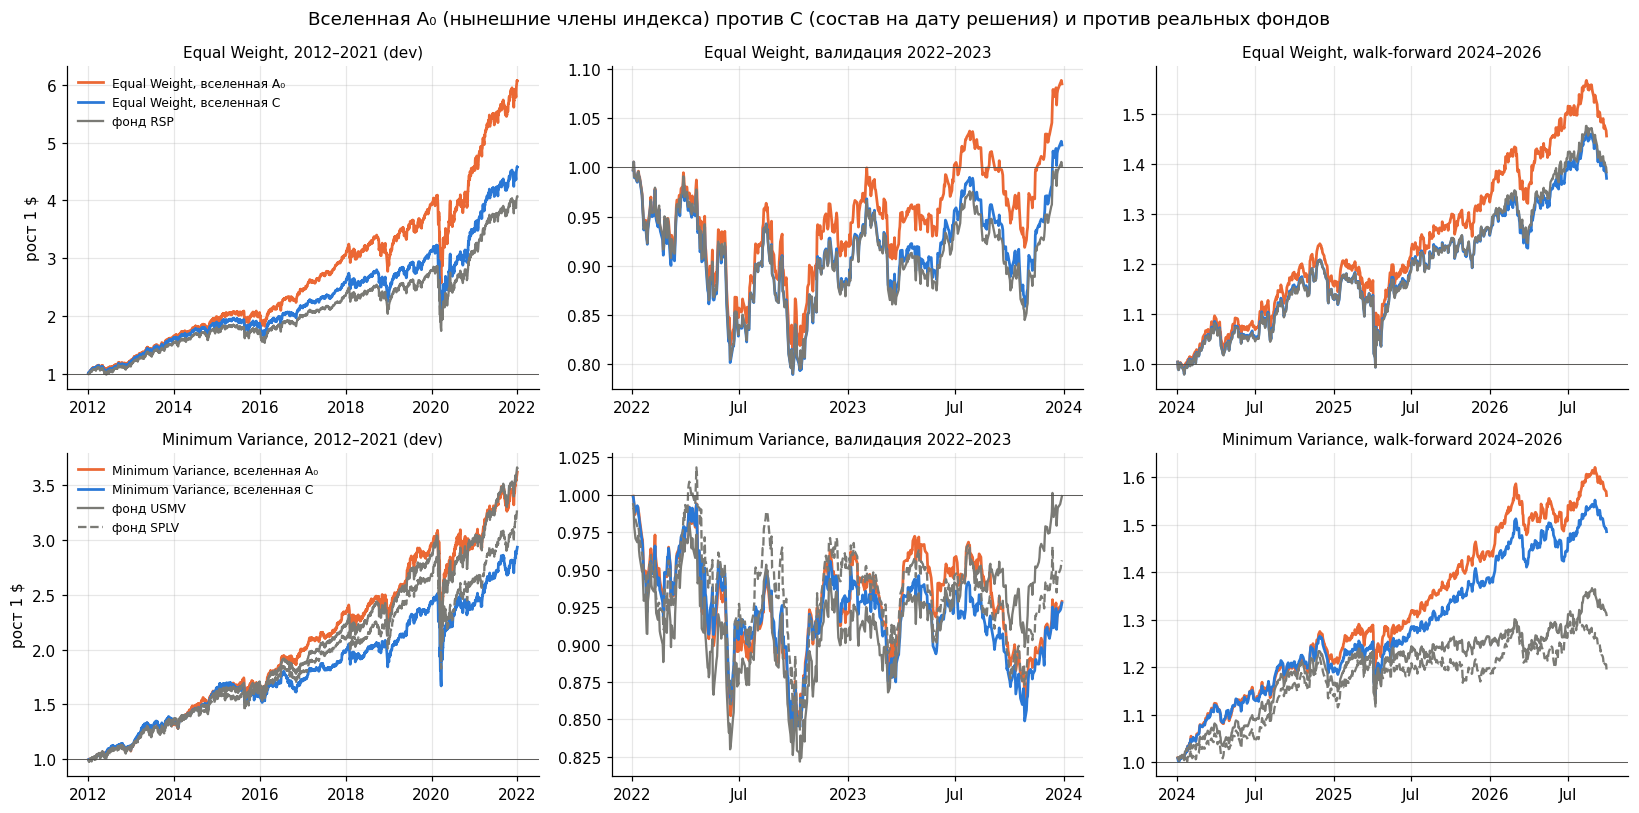

In [37]:
PERIODS_F = {"2012–2021 (dev)": (pd.Timestamp("2012-01-01"), DEV_END), PER[1]: PERIODS[PER[1]], PER[2]: PERIODS[PER[2]]}
PF = list(PERIODS_F)
Q_SET = {d for d in U.ME if d.month in (3, 6, 9, 12)}
EWQ = "Equal Weight — C, раз в квартал"


def sub_curve(eq, a, b):
    s = eq[(eq.index >= a) & (eq.index < b)]
    prev = eq[eq.index < a]
    return s / prev.iloc[-1] if len(prev) else s


EWQ_CUR = cached("ew_quarterly", lambda: {per: backtest(ew_fn("C"), *PERIODS[per], rebal=Q_SET)[0] for per in PER})
F_RES, F_CUR = {}, {}
for per, (a, b) in PERIODS_F.items():
    src_per = PER[0] if per == PF[0] else per
    for k, t in FUNDS.items():
        F_CUR[(k, per)] = fund_curve(t, a, b)
    for s in ("Equal Weight", "Minimum Variance"):
        for u in ("A0", "C"):
            F_CUR[(f"{s} — {u.replace('A0', 'A₀')}", per)] = sub_curve(CUR_U[(s, u, src_per)], a, b)
    F_CUR[(EWQ, per)] = sub_curve(EWQ_CUR[src_per], a, b)
    F_CUR[(f"{COMBO_NAME} — C", per)] = sub_curve(CUR_EQ[(COMBO_NAME, src_per)], a, b)
    for k, eq in list(F_CUR.items()):
        if k[1] == per:
            F_RES[k] = perf(eq)
F_ORDER = ["Equal Weight — A₀", "Equal Weight — C", EWQ, "RSP (S&P 500 Equal Weight)", "Minimum Variance — A₀",
           "Minimum Variance — C", "USMV (MSCI USA Minimum Volatility)", "SPLV (S&P 500 Low Volatility)",
           f"{COMBO_NAME} — C", "SPY (S&P 500)"]
display(res_table(F_ORDER, cols=("CAGR", "волатильность", "Sharpe", "Sharpe изб.", "MaxDD"), periods=PF, res=F_RES).round(3))

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for row, (s, funds) in enumerate((("Equal Weight", ["RSP (S&P 500 Equal Weight)"]),
                                  ("Minimum Variance", ["USMV (MSCI USA Minimum Volatility)", "SPLV (S&P 500 Low Volatility)"]))):
    for ax, per in zip(axes[row], PF):
        for u, c in (("A₀", COL["ew"]), ("C", COL["ml"])):
            eq = F_CUR[(f"{s} — {u}", per)]
            ax.plot(eq.index, eq.values, color=c, lw=1.8, label=f"{s}, вселенная {u}")
        for k, ls in zip(funds, ("-", "--")):
            eq = F_CUR[(k, per)]
            ax.plot(eq.index, eq.values, color=COL["spy"], lw=1.5, ls=ls, label=f"фонд {k.split(' (')[0]}")
        ax.set_title(f"{s}, {per}", fontsize=10)
        ax.axhline(1, color=TEXT_SECONDARY, lw=0.6)
        loc = mdates.AutoDateLocator(maxticks=6)
        ax.xaxis.set_major_locator(loc); ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
    axes[row, 0].set_ylabel("рост 1 $")
    axes[row, 0].legend(frameon=False, fontsize=8, loc="upper left")
plt.suptitle("Вселенная A₀ (нынешние члены индекса) против C (состав на дату решения) и против реальных фондов")
plt.tight_layout(); plt.show()

rows = []
for per in PF:
    for name in ("Minimum Variance — C", f"{COMBO_NAME} — C"):
        r1 = daily_r(F_CUR[(name, per)])
        for ref in ("Equal Weight — C", "USMV (MSCI USA Minimum Volatility)", "SPY (S&P 500)"):
            rows.append({"период": per, "портфель": name, "против": ref, **sharpe_row(r1, daily_r(F_CUR[(ref, per)]))})
FUND_TESTS = pd.DataFrame(rows)
FUND_TESTS.insert(FUND_TESTS.columns.get_loc("ΔSharpe изб."), "p (Холм)", holm(FUND_TESTS["p"]))
FUND_TESTS["p изб. (Холм)"] = holm(FUND_TESTS["p изб."])
FUND_TESTS = FUND_TESTS.set_index(["портфель", "период", "против"])
show_tests(FUND_TESTS)

### 8.3. Чего не хватает во вселенной C

Таблица изменений Википедии (около 2/3 всех исключений с причинами) показывает, у каких исключённых акций нет цен.

In [38]:
WIKI = pd.read_csv(f"{DATA_DIR}/sp500_changes_wiki.csv", parse_dates=["date"])
WIKI = WIKI[(WIKI["date"] >= "2008-01-01") & (WIKI["date"] < WF_END) & WIKI["removed"].notna()].copy()
reason = WIKI["reason"].fillna("").str.lower()
WIKI["причина"] = "другое"
for k, pat in (("переименование", r"changed its (?:name|ticker)|ticker symbol from|renamed"),
               ("банкротство", r"bankrupt|chapter 11|receivership"),
               ("покупка или слияние", r"acquir|merg|bought|purchas|takeover|taken over|taken private|buyout"),
               ("выделение подразделения", r"spun|spin|split-off|separated|distribution"),
               ("снижение капитализации", r"market cap|capitalization")):
    WIKI.loc[(WIKI["причина"] == "другое") & reason.str.contains(pat), "причина"] = k
WIKI["тикер"] = WIKI["removed"].str.replace(".", "-", regex=False).map(lambda t: RENAME.get(t, t))
WIKI = WIKI[WIKI["причина"] != "переименование"]
EVER_C = {t for t in TICKERS if EC[t].any()}
WIKI["есть цены"] = WIKI["тикер"].isin(EVER_C)
(WIKI.groupby("причина")["есть цены"].agg(["count", "sum", "mean"])
 .set_axis(["исключений с 2008 г.", "из них во вселенной C", "доля"], axis=1)
 .sort_values("исключений с 2008 г.", ascending=False).round(2))

,исключений с 2008 г.,из них во вселенной C,доля
причина,,,
покупка или слияние,160,12,0.08
снижение капитализации,135,82,0.61
выделение подразделения,29,13,0.45
другое,15,3,0.20
банкротство,5,1,0.20


**Делистинг внутри периода.** Протокол предполагает: если торги акцией прекратились между датами решения, позиция до
ребалансировки стоит по последней цене. Ниже проверено, встречается ли это в данных: какие бумаги перестают
торговаться до конца снимка и были ли они в индексе в этот момент.

In [39]:
last_px = raw_c.apply(lambda s: s.last_valid_index())
stopped = [t for t in TICKERS if last_px[t] is not None and last_px[t] < IDX[-1]]
ev = []
for per, (a, b) in PERIODS.items():
    me = U.ME[(U.ME >= a - pd.Timedelta(days=5)) & (U.ME < b)]
    ev.append(sum(int(EC.loc[d, t]) for t in stopped for d in me
                  if d < last_px[t] < (U.ME[U.ME > d][0] if (U.ME > d).any() else IDX[-1])))
print("случаев «акция во вселенной на дату решения, торги прекратились до следующей»: "
      + ", ".join(f"{p}: {n}" for p, n in zip(PER, ev)))
# все бумаги снимка (не только вошедшие в расчёт), торги которыми прекратились до конца периода
idx_members = lambda d: {RENAME.get(h, h) for h in HSET[HSET.index <= d].iloc[-1]}
pd.DataFrame({t: {"цены Yahoo с": RAW[t].first_valid_index().date(), "последняя цена": RAW[t].last_valid_index().date(),
                  "дней с ценой": int(RAW[t].notna().sum()), "в индексе в этот день": t in idx_members(RAW[t].last_valid_index()),
                  "во вселенной C (дат решения)": int(EC[t].loc[U.ME].sum()) if t in EC else 0}
              for t in RAW.columns if RAW[t].notna().any() and RAW[t].last_valid_index() < IDX[-1]}).T

случаев «акция во вселенной на дату решения, торги прекратились до следующей»: dev 2009–2021: 0, валидация 2022–2023: 0, walk-forward 2024–2026: 0


,цены Yahoo с,последняя цена,дней с ценой,в индексе в этот день,во вселенной C (дат решения)
AVB,2026-08-14,2026-08-14,1,True,0
EA,2026-08-04,2026-08-04,1,True,0
EQR,2026-08-17,2026-08-17,1,True,0
GR,2004-01-02,2018-02-22,3446,False,0
LEG,2026-08-26,2026-08-26,1,False,0
QRVO,2026-07-29,2026-09-14,5,False,0


Вывод: Yahoo почти не хранит историю бумаг, торги которыми прекратились, — у всех исключённых акций с ценами торги
продолжаются (компания осталась публичной, но вышла из индекса), а поглощённые и обанкротившиеся компании выпадают из
данных целиком (из 160 исключений из-за покупки во вселенной C лишь 12, или 8%). Поэтому допущение «по последней цене»
в расчётах не срабатывает ни разу, а остаточное смещение вселенной C создаёт не оценка позиции при делистинге, а
**отсутствие в данных выбывших компаний**. Знак и размер этого смещения по имеющимся данным установить нельзя:
отсутствие банкротов завышает результат, а отсутствие поглощённых с премией компаний — занижает, и из 160 поглощений
во вселенную попали лишь 12. Тот же механизм виден в таблице выше: у AVB, EA, EQR (и WBD), выбывших из индекса в
августе — октябре 2026 г., Yahoo уже хранит лишь одну последнюю цену, у LEG (в индексе до 12.2021) — одну, у QRVO
(до 11.2024) — пять, и вселенная C не содержит их за все годы членства. Количественно оценить остаток можно только по
независимым данным с историей выбывших бумаг и выплатами при делистинге (например, CRSP).

## 9. Система по постановке задания: 28 акций разных секторов

Постановка задания предлагает портфель из 20–30 акций разных секторов. Основная вселенная работы шире — весь индекс на
дату решения (около 490 акций). Поэтому та же система — те же прогнозы, ансамбли, оптимизатор, ограничения, издержки и
протокол — проверяется и на узкой вселенной **S**:

* раз в год, на последнюю дату решения декабря, из вселенной C берутся по 2 крупнейшие акции каждой секторной группы
  (по медианному долларовому обороту за год: цена, скорректированная только на сплиты, × объём — без
  дивидендной корректировки Yahoo, которая зависит от будущих выплат), остальные места до 28 — следующие по обороту, не больше 3 акций из
  группы; из двух классов акций одной компании (GOOG и GOOGL и т. п.) берётся один. Выбор использует только прошлые
  данные и состав индекса на эту дату, то есть не добавляет заглядывания вперёд, но наследует неполноту вселенной C;
* между пересмотрами акция остаётся во вселенной, пока она в индексе; выбывшая не заменяется до следующего пересмотра;
* секторная группа — корреляционная группа раздела 2.2, а не сектор GICS, поэтому, например, Ford может попасть в
  группу «Материалы», а Home Depot — в «Недвижимость».

Стратегии: Equal Weight, Minimum Variance, Mean-Variance на исторической доходности, Марковиц на прогнозе основного
ансамбля и на ансамблях раздела 5.4. γ у Mean-Variance и у Марковица на прогнозе выбирается заново по Sharpe на dev
вселенной S; Марковиц сравнивается с Minimum Variance при том же γ (как в разделе 6). Модели не переобучаются:
прогноз тот же, что для вселенной C (обучение на всех акциях даёт больше данных), меняется только набор акций, из
которых строится портфель. При 28 акциях ограничения «акция ≤ 10%, сектор ≤ 30%» действуют заметно сильнее, чем при
490. Оптимизатор для S решает ту же задачу только по акциям вселенной (40 переменных вместо 607 — в ~100 раз быстрее);
совпадение весов с полной задачей проверяется ниже.

In [40]:
S_SIZE, S_PER_SEC, S_MAX_SEC, S_SLOTS = 28, 2, 3, 40
SAME_COMPANY = {"GOOG": "GOOGL", "FOX": "FOXA", "NWS": "NWSA", "UA": "UAA"}   # два класса акций одной компании
COMPANY = np.array([SAME_COMPANY.get(t, t) for t in TICKERS])
# Долларовый оборот дня = цена закрытия, скорректированная только на сплиты, × объём (Yahoo тоже приводит объём к
# сплитам). Цены в данных скорректированы и на дивиденды: Yahoo умножает все цены до даты выплаты на (1 − D / C), где C —
# закрытие накануне, поэтому скорректированная цена зависит от будущих выплат и меняет рейтинг ликвидности задним
# числом. Множители восстанавливаются по журналу выплат и снимаются — получается цена, известная на ту дату
EV_DIV = EV[(EV["dividend"] > 0) & EV["ticker"].isin(TICKER_POS)]
pos_ = IDX.searchsorted(EV_DIV["date"])                         # выплаты после конца периода — в строку len(IDX)
LOGF = np.zeros((len(IDX) + 1, N))
np.add.at(LOGF, (pos_, TICKER_POS.get_indexer(EV_DIV["ticker"])), np.log1p(-EV_DIV["dividend"] / EV_DIV["prev_close"]).to_numpy())
DIV_F = np.exp(np.cumsum(LOGF[::-1], 0)[::-1][1:])               # произведение множителей по выплатам строго после дня
CLOSE_SPLIT = WIDE["close"].reindex(columns=TICKERS) / DIV_F
# проверка: восстановленное закрытие накануне выплаты совпадает с ценой закрытия из журнала Yahoo
in_ = pos_ < len(IDX)
err_ = np.abs(CLOSE_SPLIT.to_numpy()[pos_[in_] - 1, TICKER_POS.get_indexer(EV_DIV["ticker"][in_])]
              / EV_DIV["prev_close"].to_numpy()[in_] - 1)
err_ = err_[np.isfinite(err_)]
assert (err_ < 1e-3).mean() > 0.98
print(f"цена без дивидендной корректировки: совпадает с журналом Yahoo точнее 0.1% у {(err_ < 1e-3).mean():.1%} "
      f"из {len(err_)} выплат (остальные — DHR с исправленным событием и AMCR до листинга в США)")
DVOL = (CLOSE_SPLIT * WIDE["volume"][TICKERS]).rolling(252, min_periods=200).median()   # оборот в долларах, медиана за год
SEL_DATES = U.ME[(U.ME.month == 12) & (U.ME >= "2008-01-01")]


def select_s(d):
    # 28 акций на год вперёд: по 2 крупнейшие по обороту в каждой секторной группе на дату d, остальные места —
    # следующие по обороту, не больше 3 акций из группы. Только вселенная C на дату d и прошлые данные
    i = IDX.get_loc(d)
    e = ELIG["C"][i] & (U.SEC_IDX[i] >= 0) & np.isfinite(DVOL.iloc[i].to_numpy())
    dv = np.where(e, DVOL.iloc[i].to_numpy(), -np.inf)
    order = np.argsort(-dv); order = order[np.isfinite(dv[order])]
    sec = U.SEC_IDX[i]
    take, cnt, firms = [], {}, set()
    for limit in (S_PER_SEC, S_MAX_SEC):
        for j in order:
            if len(take) >= S_SIZE:
                break
            if COMPANY[j] not in firms and cnt.get(sec[j], 0) < limit:
                take.append(j); firms.add(COMPANY[j]); cnt[sec[j]] = cnt.get(sec[j], 0) + 1
    m = np.zeros(N, bool); m[take[:S_SIZE]] = True
    return m


S_SEL = pd.DataFrame({d: select_s(d) for d in SEL_DATES}, index=TICKERS).T
S_MASK = S_SEL.reindex(IDX).ffill().fillna(False).astype(bool)
ELIG["S"] = S_MASK.to_numpy() & ELIG["C"]          # между пересмотрами акция остаётся, пока она во вселенной C
UNI_NAME["S"] = f"S: {S_SIZE} крупнейших акций разных секторов"
n_s = pd.Series(ELIG["S"][IDX.get_indexer(U.ME)].sum(1), index=U.ME)
print(f"акций во вселенной S на дату решения: медиана {n_s[n_s.index >= OOF_START].median():.0f}, "
      f"минимум {n_s[n_s.index >= OOF_START].min()}; групп-секторов: {pd.Series([len(set(U.SEC_IDX[IDX.get_loc(d)][S_SEL.loc[d].to_numpy()])) for d in SEL_DATES]).median():.0f} (медиана); "
      f"замен в год: {np.mean([(S_SEL.iloc[k].to_numpy() & ~S_SEL.iloc[k - 1].to_numpy()).sum() for k in range(1, len(S_SEL))]):.1f}")
last = S_SEL.iloc[-1]
display(pd.DataFrame({"акция": [t for t in TICKERS if last[t]],
                      "группа (сектор)": [SECTORS[U.SEC_IDX[IDX.get_loc(S_SEL.index[-1])][TICKER_POS.get_loc(t)]] for t in TICKERS if last[t]]})
        .groupby("группа (сектор)")["акция"].apply(", ".join).to_frame(f"состав S с {S_SEL.index[-1].date()}"))


U.opt_sub["S"] = Optimizer(n=S_SLOTS)             # та же задача, но переменные только для акций S: в ~100 раз быстрее
U.opt_sub["S"].log = U.opt.log
d_ = S_SEL.index[-1]; e_ = ELIG["S"][IDX.get_loc(d_)]
w_sub = U.opt_sub["S"](d_, risk_lw(d_, e_), np.zeros(N), e_)
w_full = U.opt(d_, risk_lw(d_, e_), np.zeros(N), e_)
print(f"проверка на {d_.date()}: веса малой и полной задачи Minimum Variance отличаются не больше чем на "
      f"{np.abs(w_sub - w_full).max():.0e}")
assert np.abs(w_sub - w_full).max() < 1e-5


def s_grids():
    dev = PERIODS[PER[0]]
    return ({g: perf(*backtest(mvh_fn("S", g), *dev)) for g in GAMMAS},
            {g: perf(*backtest(markowitz_fn(SIG[SIG_MAIN], g, uni="S"), *dev)) for g in GAMMAS},
            {g: perf(*backtest(minvar_fn("S", gamma=g), *dev)) for g in GAMMAS})


S_MVH_DEV, S_MV_DEV, S_MVC_DEV = cached("s28_grids", s_grids, (S_SIZE, GAMMAS, SIG_MAIN))
G_S_MVH = max(S_MVH_DEV, key=lambda g: S_MVH_DEV[g]["Sharpe"])
G_S_MV = max(S_MV_DEV, key=lambda g: S_MV_DEV[g]["Sharpe"])
display(pd.DataFrame({"Mean-Variance (история)": {g: v["Sharpe"] for g, v in S_MVH_DEV.items()},
                      "Марковиц на прогнозе": {g: v["Sharpe"] for g, v in S_MV_DEV.items()},
                      "Minimum Variance": {g: v["Sharpe"] for g, v in S_MVC_DEV.items()}}).rename_axis("γ").round(3)
        .style.set_caption("Sharpe на dev вселенной S по γ"))
S_STRATS = {"S: Equal Weight": ew_fn("S"), "S: Minimum Variance": minvar_fn("S"),
            f"S: Mean-Variance (история, γ = {G_S_MVH})": mvh_fn("S", G_S_MVH),
            f"S: Minimum Variance (γ = {G_S_MV})": minvar_fn("S", gamma=G_S_MV),
            f"S: Марковиц на прогнозе ансамбля (γ = {G_S_MV})": markowitz_fn(SIG[SIG_MAIN], G_S_MV, uni="S"),
            **{f"S: Марковиц, {k}": markowitz_fn(v, G_S_MV, uni="S") for k, v in ENS_SIG.items()}}
if G_S_MV == GAMMA_MINVAR:
    S_STRATS.pop(f"S: Minimum Variance (γ = {G_S_MV})")
r_, c_ = cached("s28_portfolios", lambda: run_strats(S_STRATS), (S_SIZE, G_S_MVH, G_S_MV, tuple(S_STRATS)))
RES.update(r_); CUR_EQ.update(c_)
S_NAMES = list(S_STRATS) + ["SPY"]
display(res_table(S_NAMES).round(3))
S_MVC = f"S: Minimum Variance (γ = {G_S_MV})" if G_S_MV != GAMMA_MINVAR else "S: Minimum Variance"
S_ML = [k for k in S_STRATS if "Марковиц" in k]
S_TESTS = sharpe_tests([(k, "S: Equal Weight") for k in S_ML] + [(k, S_MVC) for k in S_ML]
                       + [(f"S: Mean-Variance (история, γ = {G_S_MVH})", "S: Equal Weight")])
show_tests(S_TESTS)

цена без дивидендной корректировки: совпадает с журналом Yahoo точнее 0.1% у 99.8% из 35423 выплат (остальные — DHR с исправленным событием и AMCR до листинга в США)


акций во вселенной S на дату решения: медиана 28, минимум 27; групп-секторов: 10 (медиана); замен в год: 6.4


,состав S с 2025-12-31
группа (сектор),
Здравоохранение,"JNJ, LLY, UNH"
Информационные технологии,"AAPL, MSFT, NVDA"
Коммунальные услуги,"NEE, SO"
Коммуникации,"GOOGL, META, NFLX"
Материалы,"F, LIN"
Недвижимость,"HD, SPGI"
Промышленность,"BA, UBER"
Товары первой необходимости,"COST, PG, WMT"
Финансы,"BRK-B, JPM, V"


проверка на 2025-12-31: веса малой и полной задачи Minimum Variance отличаются не больше чем на 6e-06


,Mean-Variance (история),Марковиц на прогнозе,Minimum Variance
γ,,,
1,0.758000,0.775000,0.921000
3,0.743000,0.912000,0.862000
10,0.812000,0.904000,0.840000
30,0.869000,0.917000,0.898000
100,0.927000,0.917000,0.917000


dev 2009–2021                                                      валидация 2022–2023                                                      walk-forward 2024–2026  \
                                                    CAGR волатильность Sharpe Sharpe изб.  MaxDD оборот в год                CAGR волатильность Sharpe Sharpe изб.  MaxDD оборот в год                   CAGR   
S: Equal Weight                                    0.158         0.191  0.865       0.841 -0.353        1.081               0.068         0.207  0.419       0.250 -0.251        1.526                  0.199   
S: Minimum Variance                                0.120         0.148  0.840       0.809 -0.349        1.105               0.020         0.152  0.209      -0.021 -0.148        1.766                  0.144   
S: Mean-Variance (история, γ = 100)                0.136         0.150  0.927       0.896 -0.311        2.441               0.028         0.152  0.258       0.027 -0.152        2.679                  0.142   
S: Minimum Variance (γ = 100)                      0.132         0.147  0.917       0.886 -0.338        1.897               0.026         0.152  0.247       0.016 -0.148        2.474                  0.133   
S: Марковиц на прогнозе ансамбля (γ = 100)         0.132         0.147  0.917       0.886 -0.346        3.282               0.014         0.153  0.169      -0.060 -0.148        3.264                  0.132   
S: Марковиц, ансамбль 3: равные веса               0.135         0.148  0.932       0.900 -0.343        4.007               0.015         0.153  0.172      -0.057 -0.145        3.655                  0.136   
S: Марковиц, ансамбль 3: статические веса          0.135         0.148  0.929       0.898 -0.340        4.849               0.009         0.152  0.136      -0.094 -0.153        4.472                  0.137   
S: Марковиц, ансамбль 3: адаптивные веса           0.134         0.147  0.926       0.894 -0.346        4.170               0.020         0.153  0.204      -0.025 -0.142        3.339                  0.138   
S: Марковиц, ансамбль 3: RL-агент                  0.136         0.148  0.937       0.905 -0.346        4.398               0.018         0.153  0.193      -0.037 -0.146        3.564                  0.145   
SPY                                                0.159         0.179  0.914       0.888 -0.337          NaN               0.014         0.195  0.170      -0.010 -0.245          NaN                  0.205   

                                                                                                 
                                           волатильность Sharpe Sharpe изб.  MaxDD оборот в год  
S: Equal Weight                                    0.146  1.321       1.027 -0.186        1.272  
S: Minimum Variance                                0.110  1.283       0.893 -0.126        1.177  
S: Mean-Variance (история, γ = 100)                0.114  1.219       0.845 -0.145        2.873  
S: Minimum Variance (γ = 100)                      0.109  1.201       0.809 -0.120        2.115  
S: Марковиц на прогнозе ансамбля (γ = 100)         0.111  1.166       0.782 -0.127        3.660  
S: Марковиц, ансамбль 3: равные веса               0.111  1.200       0.815 -0.126        4.150  
S: Марковиц, ансамбль 3: статические веса          0.111  1.213       0.828 -0.129        5.300  
S: Марковиц, ансамбль 3: адаптивные веса           0.111  1.221       0.837 -0.128        4.297  
S: Марковиц, ансамбль 3: RL-агент                  0.111  1.280       0.893 -0.123        4.298  
SPY                                                0.156  1.279       1.004 -0.188          NaN

## 10. Итоги

### 10.1. Сводная таблица и кривые капитала

dev 2009–2021                                                      валидация 2022–2023                                                      walk-forward 2024–2026  \
                                                          CAGR волатильность Sharpe Sharpe изб.  MaxDD оборот в год                CAGR волатильность Sharpe Sharpe изб.  MaxDD оборот в год                   CAGR   
Equal Weight                                             0.177         0.202  0.905       0.882 -0.396        0.736               0.011         0.192  0.155      -0.028 -0.215        1.186                  0.122   
обратная волатильность                                   0.168         0.184  0.939       0.913 -0.386        0.745               0.008         0.178  0.134      -0.064 -0.200        1.138                  0.106   
Minimum Variance                                         0.120         0.132  0.921       0.886 -0.336        1.358              -0.037         0.131 -0.221      -0.488 -0.165        2.060                  0.156   
Minimum Variance без штрафа за оборот                    0.119         0.127  0.946       0.909 -0.303        4.807              -0.040         0.131 -0.249      -0.516 -0.171        6.105                  0.154   
Mean-Variance (историческая доходность, γ = 100)         0.126         0.141  0.909       0.877 -0.337        5.763              -0.046         0.142 -0.259      -0.506 -0.185        7.108                  0.229   
Minimum Variance + прогноз HAR                           0.136         0.128  1.058       1.022 -0.278        3.128              -0.013         0.135 -0.027      -0.287 -0.162        4.448                  0.142   
Minimum Variance + история 252 дня                       0.122         0.131  0.940       0.905 -0.337        1.553              -0.036         0.131 -0.217      -0.486 -0.160        2.275                  0.174   
Марковиц на прогнозе (γ = 10)                            0.153         0.166  0.940       0.912 -0.360       16.155              -0.029         0.187 -0.064      -0.252 -0.220       16.354                  0.067   
Марковиц, ансамбль 3: равные веса                        0.161         0.160  1.013       0.984 -0.351       19.420              -0.018         0.178 -0.012      -0.209 -0.219       20.969                  0.045   
Марковиц, ансамбль 3: статические веса                   0.166         0.154  1.071       1.041 -0.296       21.190              -0.054         0.164 -0.258      -0.472 -0.203       22.478                  0.039   
Марковиц, ансамбль 3: адаптивные веса                    0.158         0.163  0.981       0.953 -0.365       19.040              -0.071         0.181 -0.316      -0.510 -0.259       17.272                  0.097   
Марковиц, ансамбль 3: RL-агент                           0.153         0.164  0.954       0.926 -0.369       19.500              -0.060         0.174 -0.269      -0.471 -0.240       18.194                  0.085   
SPY                                                      0.159         0.179  0.914       0.888 -0.337          NaN               0.014         0.195  0.170      -0.010 -0.245          NaN                  0.205   

                                                                                                       
                                                 волатильность Sharpe Sharpe изб.  MaxDD оборот в год  
Equal Weight                                             0.139  0.899       0.592 -0.178        1.128  
обратная волатильность                                   0.128  0.848       0.515 -0.161        1.095  
Minimum Variance                                         0.098  1.525       1.089 -0.100        1.550  
Minimum Variance без штрафа за оборот                    0.096  1.543       1.098 -0.098        5.547  
Mean-Variance (историческая доходность, γ = 100)         0.122  1.757       1.406 -0.127        6.324  
Minimum Variance + прогноз HAR                           0.098  1.398       0.963 -0.107       

выбран на dev протоколом (лучший по Sharpe на dev портфель без прогноза доходности): Minimum Variance + прогноз HAR; лучший в walk-forward постфактум: по Sharpe — Mean-Variance (историческая доходность, γ = 100), по Sharpe изб. — Mean-Variance (историческая доходность, γ = 100), по CAGR — Mean-Variance (историческая доходность, γ = 100) (выбор по результату walk-forward — не независимая проверка)


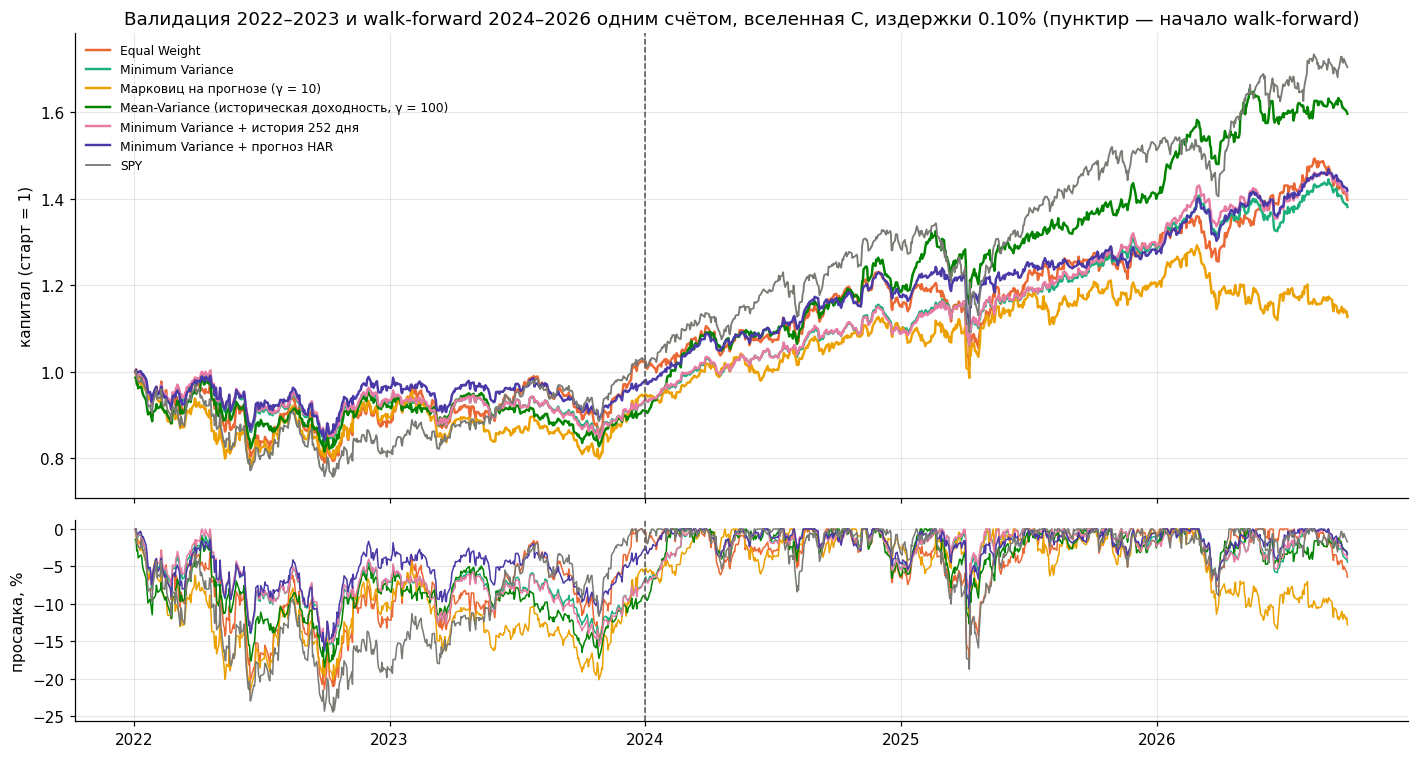

резервных решений оптимизатора за весь расчёт: 0
неудачных оценок GARCH: 6


In [41]:
CTRL_IN = [CTRL_NAME] if CTRL_NAME in RISK_STRATS else []
FINAL = list(dict.fromkeys(["Equal Weight", "обратная волатильность", "Minimum Variance", MV0_NAME, MVH_NAME, MVF_NAME]
                           + CTRL_IN + [MVC_NAME, MV_NAME] + ([TILT_NAME] if LAM > 0 else []) + EP + [COMBO_NAME, "SPY"]))
FINAL_TAB = res_table(FINAL)
display(FINAL_TAB.round(3))
wf_ = FINAL_TAB[PER[2]]
print(f"выбран на dev протоколом (лучший по Sharpe на dev портфель без прогноза доходности): {RBASE}; "
      f"лучший в walk-forward постфактум: по Sharpe — {wf_['Sharpe'].idxmax()}, по Sharpe изб. — {wf_['Sharpe изб.'].idxmax()}, "
      f"по CAGR — {wf_['CAGR'].idxmax()} (выбор по результату walk-forward — не независимая проверка)")

SHOW = list(dict.fromkeys(["Equal Weight", "Minimum Variance", MV_NAME] + ([TILT_NAME] if LAM > 0 else [])
                          + [MVH_NAME] + CTRL_IN + [COMBO_NAME]))
FN_ALL = {**BASE, **RISK_STRATS, **ML_STRATS, MVH_NAME: mvh_fn(gamma=GAMMA_MVH)}


def curves():
    out = {n: backtest(FN_ALL[n], DEV_END, WF_END)[0] for n in SHOW if n in FN_ALL}
    if LAMC > 0:
        rec, _ = base_record(RBASE, DEV_END, WF_END)
        out[COMBO_NAME] = backtest(tilt_fn(SIG[SIG_MAIN], LAMC, SMC, rec), DEV_END, WF_END)[0]
    return out


CONT = cached("curves_val_wf", curves, (tuple(SHOW), RBASE, LAMC, SMC, GAMMA, LAM, SM))
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
CURVE_COL = {"Equal Weight": COL["ew"], "Minimum Variance": COL["minvar"], MV_NAME: COL["mv"], TILT_NAME: COL["ml"],
             COMBO_NAME: COL["risk"], "SPY": COL["spy"], CTRL_NAME: COL["alt"], MVH_NAME: PALETTE["green"]}
for name in SHOW + ["SPY"]:
    c = CURVE_COL[name]
    eq = CONT[name] if name != "SPY" else fund_curve("SPY", DEV_END, WF_END)
    ax1.plot(eq.index, eq.values, color=c, lw=1.6 if name != "SPY" else 1.2, label=name)
    ax2.plot(eq.index, (eq / eq.cummax().clip(lower=1) - 1) * 100, color=c, lw=1.0)
for ax in (ax1, ax2):
    ax.axvline(VAL_END, color=TEXT_SECONDARY, ls="--", lw=1)
ax1.set_ylabel("капитал (старт = 1)"); ax2.set_ylabel("просадка, %")
ax1.legend(frameon=False, fontsize=8, loc="upper left")
ax1.set_title("Валидация 2022–2023 и walk-forward 2024–2026 одним счётом, вселенная C, издержки 0.10% (пунктир — начало walk-forward)")
plt.tight_layout(); plt.show()
print(f"резервных решений оптимизатора за весь расчёт: {len(U.opt.log)}"
      + (f" (даты: {sorted({str(d.date()) for d, _ in U.opt.log})[:10]})" if U.opt.log else ""))
print(f"неудачных оценок GARCH: {GARCH_FAILS}")

### 10.2. Чувствительность: длина блока бутстрепа, безрисковая ставка, критерий выбора на dev

Длина блока 21 день выбрана заранее (около месяца — горизонт ребалансировки). Первая таблица — p основных сравнений
раздела 3 (H2–H4) и двух описательных (выбранный протоколом портфель и Minimum Variance против Equal Weight) при
блоках 10, 21 и 63 дня; разницы Sharpe — и по доходности сверх безрисковой ставки. Вывод, который меняется от этих
выборов, ненадёжен. Вторая таблица показывает, изменился бы выбор параметров на dev, если бы критерием был Sharpe
сверх ставки, а не Sharpe без её вычета (спецификация протокола).

In [42]:
MAIN_TESTS = [("H2", MV_NAME, MVC_NAME, "Sharpe", sharpe_)]
if LAM > 0:
    MAIN_TESTS.append(("H2", TILT_NAME, "Equal Weight", "Sharpe", sharpe_))
MAIN_TESTS += [("H3", MVF_NAME, "Minimum Variance", "волатильность", vol_),
               ("выбор протокола", RBASE, "Equal Weight", "Sharpe", sharpe_),
               ("Minimum Variance без ML", "Minimum Variance", "Equal Weight", "Sharpe", sharpe_)]


def block_row(h, comp, lab, per, r1, r0, st):
    out = {blk: boot_diff(r1, r0, st, block=blk) for blk in (10, 21, 63)}
    return {"гипотеза": h, "сравнение": comp, "статистика": lab, "период": per, "разница": out[21][0],
            **{f"p, блок {blk}": out[blk][2] for blk in out}}


rows = []
for h, name, ref, lab, st in MAIN_TESTS:
    for per in PER[1:]:
        r1, r0 = daily_r(CUR_EQ[(name, per)]), daily_r(CUR_EQ[(ref, per)])
        rows.append(block_row(h, f"{name} − {ref}", lab, per, r1, r0, st))
        if lab == "Sharpe":                           # та же разница по доходности сверх безрисковой ставки
            rows.append(block_row(h, f"{name} − {ref}", "Sharpe изб.", per, excess(r1), excess(r0), st))
rows += [block_row("H4", "Equal Weight: A₀ − C", "CAGR", per, daily_r(CUR_U[("Equal Weight", "A0", per)]),
                   daily_r(CUR_U[("Equal Weight", "C", per)]), cagr_) for per in PER[1:]]
display(show_tests(pd.DataFrame(rows).set_index(["гипотеза", "сравнение", "статистика", "период"])))

dev_ = PER[0]
tg = TILT_GRID.xs(dev_, level="период")
SEL_TAB = pd.DataFrame([
    {"решение на dev": "γ Марковица на прогнозе", "по Sharpe": GAMMA,
     "по Sharpe изб.": max(MV_DEV, key=lambda g: MV_DEV[g]["Sharpe изб."])},
    {"решение на dev": "λ и сглаживание наклона Equal Weight", "по Sharpe": (LAM, SM), "по Sharpe изб.": tg["Sharpe изб."].idxmax()},
    {"решение на dev": "база комбинированной стратегии", "по Sharpe": RBASE,
     "по Sharpe изб.": max(BASE_CANDIDATES, key=lambda n_: RES[(n_, dev_)]["Sharpe изб."])},
    {"решение на dev": "λ и сглаживание поверх базы", "по Sharpe": (LAMC, SMC),
     "по Sharpe изб.": max(CGRID, key=lambda k_: CGRID[k_]["Sharpe изб."])},
]).set_index("решение на dev")
SEL_TAB["совпадает"] = [str(a_) == str(b_) for a_, b_ in zip(SEL_TAB["по Sharpe"], SEL_TAB["по Sharpe изб."])]
print("Выбор параметров на dev по Sharpe (протокол) и по Sharpe сверх безрисковой ставки:")
SEL_TAB.astype(str)

Выбор параметров на dev по Sharpe (протокол) и по Sharpe сверх безрисковой ставки:


,по Sharpe,по Sharpe изб.,совпадает
решение на dev,,,
γ Марковица на прогнозе,10,10,True
λ и сглаживание наклона Equal Weight,"(0.0, 1)","(0.0, 1)",True
база комбинированной стратегии,Minimum Variance + прогноз HAR,Minimum Variance + прогноз HAR,True
λ и сглаживание поверх базы,"(0.0, 1)","(0.0, 1)",True


### 10.3. Выводы

| гипотеза | результат | главное число |
|---|---|---|
| H1: прогноз доходности содержит информацию | **не подтверждена** | IC основного ансамбля (CatBoost + LSTM) 0.001 / 0.034 / 0.003 (dev / валидация / walk-forward), ни в одном периоде не значим (\|t\| ≤ 1.2) |
| H2: прогноз доходности улучшает портфель | **не подтверждена** | на dev прогноз почти ничего не добавляет к Minimum Variance с тем же γ (ΔSharpe от −0.20 до +0.02), наклон: dev выбрал λ = 0; в walk-forward Марковиц на прогнозе значимо хуже Minimum Variance (Sharpe 0.53 против 1.53, p = 0.023, с поправкой Холма 0.046) |
| H3: прогноз волатильности точнее и снижает риск | **частично**: точнее — да, риск — нет | HAR точнее «истории 252 дня» на dev и валидации (t = −2.6 и −3.3), в walk-forward незначимо (t = −1.5); волатильность Minimum Variance с прогнозом не ниже (+0.3 п.п. на валидации, 0.0 в walk-forward) |
| H4: построение вселенной меняет бэктест | **подтверждена** (без поправки на множественность) | Equal Weight на нынешних членах индекса (A₀) завышает CAGR на 3.0 / 3.0 / 2.5 п.п. в год; 95% ДИ не включают 0 при любой длине блока; с поправкой Холма на все 36 сравнений таблицы 8.1 разница значима только на dev |
| H5: поиск похожих состояний (DTW) информативен | **не подтверждена** | IC точного DTW 0.012 на dev (t = 2.6, p = 0.01), но −0.013 на валидации и 0.004 в walk-forward; евклидов kNN 0.010 / 0.013 / 0.013 — сигнал на dev не переносится вне выборки |
| H6: ансамбль устойчивее отдельных моделей | **не подтверждена** | разброс месячного IC у ансамбля трёх моделей ниже, чем у CatBoost (0.15 / 0.17 / 0.12 против 0.18 / 0.20 / 0.14), близок к LSTM и выше, чем у DTW (0.05–0.06); худший блок не лучше; парные разницы IC незначимы (p ≥ 0.12) |
| H7: межсекторные признаки улучшают прогноз | **не подтверждена** | ΔIC CatBoost с секторными признаками и без них −0.001 / +0.020 / −0.020, внутри секторов −0.009 / +0.016 / −0.006, все p ≥ 0.16 |
| H8: новости улучшают прогноз | **не подтверждена** | вклад содержания: FinBERT − плацебо −0.000 на dev и +0.001 на валидации (p ≥ 0.85), FinBERT − «только число новостей» 0.000; все новостные варианты, включая плацебо и «только число новостей», снижают IC на валидации на 0.014–0.015 |
| H9: адаптивные веса лучше фиксированных | **не подтверждена** | IC 0.018 / 0.018 (валидация / walk-forward) против 0.022 / 0.002 у равных весов, разницы незначимы (p ≥ 0.15); портфель в walk-forward Sharpe 0.74 против 0.39, p = 0.22 |
| H10: RL-агент лучше простых правил | **не подтверждена** | IC 0.022 / 0.002, против адаптивных и равных весов p ≥ 0.16; портфель Sharpe 0.67 в walk-forward против 0.74 у адаптивных (p = 0.74) и 1.53 у Minimum Variance |

**1. Прогноз доходности (H1).** Ансамбль CatBoost и LSTM на 42 ценовых признаках не связан с относительной
доходностью акции за торгуемый месяц: IC 0.001 / 0.034 / 0.003, доля месяцев с IC > 0 — около половины. CatBoost,
LSTM и Ridge по отдельности тоже незначимы, кроме Ridge в walk-forward (IC 0.047, t = 2.2, p = 0.03). Это одна из
восьми строк описательной таблицы, а на dev Ridge не выделялся, поэтому подтверждением это не считается (DTW и
kNN — п. 5). Сильнейший на dev одиночный признак — краткосрочный разворот (−ema12_ratio: IC 0.028, t = 2.5) — в
walk-forward меняет знак (−0.025). CatBoost на 62% опирается на секторные признаки, но без них не хуже
(−0.002 / 0.020 / 0.012); IC внутри секторов у всех моделей по модулю не больше 0.022. Ночной гэп на IC ансамбля почти
не влияет: цели «от закрытия» и «от открытия» с одной конечной ценой расходятся не больше чем на 0.003. Перестановочный
тест (λ = 1) находит информацию только на валидации (p = 0.005 до и после комиссий, внутри секторов 0.08 и 0.045), но
не на dev (0.995 до комиссий) и не в walk-forward (0.27). Сигнал, если он есть, слишком слабый и неустойчивый.

**2. Прогноз доходности в портфеле (H2).** Выбор параметров на dev сам показывает, что прогнозу доверять не стоит:

* Марковиц на прогнозе и Minimum Variance с тем же γ на dev почти равны по Sharpe (разница от −0.20 до +0.02 при γ
  от 1 до 100), а оборот у Марковица в 2.4–65 раз выше. Выбран γ = 10 — единственный с положительной разницей (+0.02).
  В walk-forward Марковиц значимо хуже: Sharpe 0.53 против 1.53 (ΔSharpe −0.99, 95% ДИ [−1.84; −0.15], p = 0.023, с
  поправкой Холма 0.046; при блоках 10–63 дня p = 0.013–0.026; по Sharpe сверх ставки −0.86, p = 0.042, с поправкой
  0.084). Дело не только в комиссиях: без издержек Sharpe 0.65, при 0.20% — 0.42. На валидации разница незначима
  (+0.16, p = 0.65);
* для наклона Equal Weight dev выбрал λ = 0, то есть отказ от прогноза: все λ > 0 на dev хуже Equal Weight (Sharpe
  0.84–0.90 против 0.91). Поверх лучшего риск-портфеля dev тоже выбрал λ = 0;
* в walk-forward сильный наклон со сглаживанием (λ = 1, 3 месяца) дал бы Sharpe 1.00 против 0.90, но честно выбрать
  его было нельзя: на dev он был худшим (0.84).

**3. Прогноз риска (H3).** Волатильность, в отличие от доходности, прогнозируется: ранговая корреляция прогноза с
фактом у всех моделей 0.59–0.72, R² логарифма волатильности у HAR — 0.44 / 0.42 / 0.36. HAR — лучшая по QLIKE на dev
и значимо лучше «истории 252 дня» на dev и валидации (t = −2.6 и −3.3), в walk-forward — незначимо (t = −1.5).
CatBoost в walk-forward лучший по QLIKE (t = −2.2), но на dev уступал HAR и протоколом не выбирался. EWMA и GARCH в
walk-forward хуже простой истории (t = +4.9 и +2.2); почему — средняя функция потерь не показывает.

**Более точный прогноз не снизил реализованный риск портфеля.** Волатильность Minimum Variance с прогнозом HAR на
валидации на 0.3 п.п. выше, чем у Minimum Variance (p = 0.047, с поправкой Холма 0.14), в walk-forward — та же
(p = 0.94); против контроля с «историей 252 дня» — +0.4 и +0.1 п.п. (незначимо с поправкой). У обратной волатильности
с прогнозом риск значимо выше на 0.2 п.п. в обоих периодах. По Sharpe вариант с HAR лучший на dev (1.06 против 0.92 у
Minimum Variance и 0.94 у контроля), но в walk-forward уступает обоим (1.40 против 1.53 и 1.69). **Преимущество HAR на
dev не сохранилось; почему оно возникло, эксперименты не устанавливают** — для этого нужна абляция (раздел 10.5).

**4. Построение вселенной (H4).** Бэктест на 379 нынешних членах индекса с историей с 2004 г. (A₀) завышает CAGR Equal
Weight на 3.0 / 3.0 / 2.5 п.п. в год и Sharpe на 0.16–0.18. Без поправки 95% ДИ не включают 0 при любой длине блока
(p от < 0.001 до 0.042). С поправкой Холма на все 36 сравнений таблицы 8.1 разница A₀ − C значима только на dev
(валидация p = 0.075, walk-forward 0.66), а из разностей A − B и B − C у Equal Weight — 4 из 6. Слагаемые: заглядывание
вперёд по включениям в индекс (A − B: 2.9 / 1.7 / 3.8 п.п.) и отсутствие будущих исключённых акций (B − C:
1.3 / 2.0 / 1.6 п.п.); требование истории с 2004 г. частично компенсирует их, убирая быстро выросшие новые компании
(A₀ − A: −1.2 / −0.6 / −3.0 п.п.). У Minimum Variance без поправки значимы лишь три разницы — две на dev и A₀ − A на
валидации (p = 0.049), с поправкой — ни одна: оптимизатор мало берёт волатильные акции, которыми различаются вселенные.
Все эти разности — эффекты правил отбора **на доступных данных**, а не полная ошибка выжившего.

Equal Weight на вселенной C близок к фонду RSP (CAGR +1.3 / +1.0 / −0.4 п.п. в год; с квартальной ребалансировкой, как
у RSP, в walk-forward 12.7% против 12.6%), а на A₀ расходится с ним на 4.7 / 4.1 / 2.1 п.п. Это проверка внешней
согласованности, а не оценка остаточного смещения: совпадение двух CAGR не исключает взаимной компенсации отличий.
Эффект вселенной (около 3 п.п. CAGR в год) больше любого положительного эффекта ML в этой работе, поэтому без
исторического состава индекса сравнивать ML-стратегии с рынком нельзя.

**5. Дополнительные гипотезы (H5–H10).** Ни одна не подтвердилась: вне выборки эффектов не обнаружено. Это не
доказывает, что их нет, — они могут быть меньше, чем способен различить эксперимент. Новости проверены только на dev и
валидации.

* **DTW (H5).** Точный поиск 50 самых похожих 30-дневных форм цены среди 55–416 тыс. окон (проверен полным перебором)
  даёт самый сильный на dev ML-сигнал: IC 0.012 (t = 2.6, p = 0.01). Евклидов kNN на dev на границе значимости (0.010,
  p = 0.046). Вне выборки оба незначимы: DTW −0.013 на валидации и 0.004 в walk-forward, kNN 0.013 и 0.013 (p = 0.11
  и 0.17). «Деформация времени» преимущества перед евклидовым расстоянием не дала.
* **Устойчивость ансамбля (H6).** Ансамбль DTW + CatBoost + LSTM с равными весами сглаживает месячный IC относительно
  CatBoost (разброс 0.15 / 0.17 / 0.12 против 0.18 / 0.20 / 0.14), у LSTM разброс почти такой же (0.17 / 0.18 / 0.11).
  Худший блок ансамбля (−0.11) не лучше, чем у CatBoost (−0.10), IC > 0 в 10 блоках из 17, парные разницы с отдельными
  моделями незначимы (p ≥ 0.12). Самый стабильный сигнал — DTW (разброс 0.05–0.06, 11 блоков из 17 с IC > 0), но и он
  вне выборки около нуля: устойчивость без величины эффекта портфелю ничего не даёт.
* **Межсекторные признаки (H7).** CatBoost на 62% опирается на 8 секторных признаков, но без них не хуже ни в одном
  периоде, в том числе по IC внутри секторов: признаки объясняют обучающую выборку, но вне её вклада не видно.
* **Новости (H8).** 1.44 млн заголовков FNSPID, тональность FinBERT и LLM (корреляция оценок 0.62), 325 акций с
  новостями на дату решения (медиана), 144 общих месяца. **Содержание заголовков ничего не добавило:** FinBERT против
  10 плацебо с перемешанной тональностью — −0.000 на dev и +0.001 на валидации (p ≥ 0.85), против варианта «только
  число новостей» — 0.000; 7 из 10 плацебо на dev и 5 из 10 на валидации дали не меньший прирост. На dev новостные
  варианты не отличаются от модели без новостей (+0.002, p ≥ 0.56). На валидации **все** варианты, включая плацебо и
  «только число новостей», снижают IC примерно на 0.014 (p с поправкой Холма от 0.004 до 0.09). Снижение есть уже от
  двух признаков числа новостей; его причина — свойство самих признаков, случайный отбор признаков CatBoost
  (rsm = 0.5) или особенность 24 месяцев валидации — этим опытом не установлена. Из одиночных признаков на dev значимо
  лишь число новостей за 21 день — с отрицательным знаком (IC −0.014, t = −2.2), на валидации знак обратный.
* **Адаптивные веса и RL-агент (H9, H10).** Схема `w ∝ exp(η · EWMA IC)` (η = 50, полураспад 3 месяца, выбраны на dev
  только по месяцам с уже известным фактом) и агент PPO, обученный на месяцах до начала периода, по IC значимо не
  отличаются ни друг от друга, ни от равных весов. На портфеле Марковица все четыре ансамбля в walk-forward хуже Minimum
  Variance с тем же γ (Sharpe 0.34–0.74 против 1.53; без поправки p от 0.004 до 0.03, с поправкой Холма ≥ 0.054).
  Лучший — с адаптивными весами (0.74), но его преимущество над равными весами незначимо (p = 0.22), а RL-агент от
  адаптивных весов не отличается (0.67, p = 0.74). Ансамбли дают 17–22 оборота в год: слабый сигнал в Марковице
  превращается в оборот.

**6. Mean-Variance и система на 28 акциях.**

* **Mean-Variance на исторической доходности** (γ = 100 — граница сетки, выбран на dev): на dev — как Equal Weight и
  Minimum Variance (Sharpe 0.91), на валидации — худший из эталонов (−0.26), а в walk-forward — лучший портфель работы
  постфактум: Sharpe 1.76, CAGR 22.9% (выше SPY, 20.5%), просадка −12.7%, оборот 6.3 в год. Против Equal Weight
  ΔSharpe +0.86 (p = 0.066), против Minimum Variance +0.23 (p = 0.47) — незначимо. Оценка μ по средней доходности за
  год — по сути ставка на годовой моментум: 2024–2026 гг. — период сильного моментума (рост крупнейших технологических
  компаний), а в 2022 г. та же ставка проиграла. Протокол этот портфель не выбрал бы: на dev он хуже Minimum Variance
  с прогнозом HAR (0.91 против 1.06).
* **Вселенная S (28 акций, раздел 9).** Ни один ML-портфель не отличается значимо ни от Equal Weight, ни от Minimum
  Variance с тем же γ (наименьшее p = 0.25 без поправки, с поправкой Холма — 1.0). γ, выбранный на dev, снова на
  границе сетки (100), и при нём оптимизационные портфели почти совпадают с Minimum Variance. Лучший по Sharpe и в
  walk-forward (1.32, CAGR 19.9%), и на валидации (0.42) — **Equal Weight**; у Minimum Variance 1.28, у портфелей на
  прогнозах 1.17–1.28, у SPY 1.28. На узкой вселенной разброс оценок выше, а ограничения весов сильнее, поэтому
  прогнозу остаётся ещё меньше места.

**7. Главный результат.** Нужно различать стратегию, **выбранную протоколом на dev**, и **лучшую в walk-forward
постфактум**:

* протокол выбрал (лучший по Sharpe на dev портфель без прогноза доходности) **Minimum Variance с прогнозом HAR**: в
  walk-forward Sharpe 1.40, CAGR 14.2%, просадка −10.7%; против Equal Weight ΔSharpe +0.50 (95% ДИ [−0.22; +1.22],
  p = 0.16), против USMV +0.40 (p = 0.19), против SPY +0.12 (p = 0.79) — ни одно преимущество не доказано;
* лучший в walk-forward по Sharpe, Sharpe сверх ставки и CAGR — **Mean-Variance на исторической доходности** (Sharpe
  1.76, сверх ставки 1.41, CAGR 22.9%, просадка −12.7%), за ним — контроль **Minimum Variance + история 252 дня**
  (Sharpe 1.69, CAGR 17.4%, просадка −8.8%). Оба выделены по результату walk-forward и потому не являются независимо
  проверенными победителями; на dev они были хуже HAR (0.91 и 0.94 против 1.06), а Mean-Variance на валидации — худший
  из эталонов;
* базовый **Minimum Variance без ML** в walk-forward — Sharpe 1.53, CAGR 15.6%, просадка −10.0%; против Equal Weight
  ΔSharpe +0.63 (95% ДИ [−0.18; +1.44], p = 0.12; при блоке 63 дня 0.075), против USMV +0.52 (p = 0.11). В 2012–2021 гг.
  он хуже Equal Weight, USMV и SPY (Sharpe 0.88 против 0.96, 1.01 и 1.02), на валидации 2022–2023 — в минусе
  (CAGR −3.7%);
* по CAGR в walk-forward SPY (20.5%) обогнал только Mean-Variance на исторической доходности; по Sharpe сверх ставки
  разница Minimum Variance и SPY сжимается до 0.09 (1.09 против 1.00, p = 0.85).

Период walk-forward просматривался в ходе разработки, поэтому эти цифры — повторный анализ, а не нетронутый тест.

**Заключение.** В исследованной выборке и при заданном протоколе не найдено устойчивого преимущества прогнозов
относительной доходности над простыми портфельными правилами — ни у отдельных моделей, включая поиск похожих состояний
DTW, ни у ансамблей с адаптивными весами и весами RL-агента, ни с межсекторными признаками и тональностью новостей, ни
на портфеле из 28 акций. Более точный прогноз волатильности акций не привёл к устойчивому снижению риска портфеля.
Результаты сильно зависят от построения вселенной, идентичности бумаг и учёта корпоративных событий. Историческая
вселенная неполная, а walk-forward просматривался в ходе разработки, поэтому оценки не доказывают будущую доходность.
Незначимость не означает, что эффект равен нулю: вывод относится к исследованным моделям, признакам и протоколу, а не
к машинному обучению вообще.

**Практический вывод.** Результат работы — воспроизводимый конвейер проверки финансовых ML-гипотез: вселенная на дату
решения с проверкой идентичности бумаг и корпоративных событий, очистка обучающих строк по моменту, когда известна
цель, выбор параметров только на dev, непересекающиеся периоды проверки, тесты с учётом числа сравнений, контрольные
варианты и сравнение с реальными фондами. Там, где эффект этих шагов измерен (вселенная на дату решения, плацебо для
новостей, поправка Холма), они уменьшали кажущийся результат.

### 10.4. Ограничения

* **Вселенная C неполная.** Yahoo не хранит историю компаний, торги которыми прекратились: цены есть у 62% членов
  индекса в 2008 г. и у 92% в 2021 г., из поглощённых с 2008 г. — лишь у 8%. Выбывшие компании отсутствуют в данных
  целиком (раздел 8.3). Остаточное смещение **неизвестного знака и размера**: отсутствие банкротов завышает результат,
  отсутствие поглощённых с премией — занижает; разница с фондом RSP его не измеряет. Оценить остаток можно только по
  независимым данным с историей выбывших бумаг и выплатами при делистинге (CRSP, Norgate и т. п.) после проверки их
  покрытия.
* **Корпоративные события.** Корректировка цен Yahoo проверена по журналу выплат и сплитов, но правило ловит только
  события с отклонением доходности дня от S&P 500 больше 10%; меньшие ошибки корректировки остаются. Исправлено по
  документам эмитента одно событие (DHR); у остальных 17 событий (15 бумаг) история бумаги до события не используется, что сужает
  вселенную в ранние годы.
* **Сектор на дату решения** — корреляционная группа, оценённая по секторным ETF за 504 торговых дня (не меньше 250
  наблюдений); с нынешней классификацией GICS она совпадает у 73% акций. Ограничение «сектор ≤ 30%», секторные
  признаки и перестановочный тест относятся к этим группам, а не к настоящим историческим секторам GICS.
* **История состава индекса** — открытый источник (книга A. Clenow и Википедия); сопоставление тикеров с эмитентами
  частично ручное (`RENAME`, `ALIAS`, `WRONG`, `CUT_FROM`), в ранние годы возможны неточности. Дат исключений из
  индекса в конце периода в источниках нет — проверено лишь, что в окне до последней даты решения никого не добавляли.
* **Признаки — цены и новостные заголовки**: фундаментальные данные и прогнозы аналитиков не использовались.
* **Новости только до 01.2024**: FNSPID заканчивается 09.01.2024, поэтому H8 проверена на dev 2012–2021 и валидации,
  а в walk-forward и в портфели новости не входят. Заголовки датированы днём без времени и относятся к следующему
  торговому дню — новость может сдвинуться на день позже реального выхода. Акция берётся из поля тикера FNSPID без
  проверки, что компания упомянута в заголовке: встречаются чужие заголовки (например, о Credit Suisse у MS). LLM
  (Qwen2.5, 2024 г.) обучалась на текстах того же периода и могла «знать» последствия новостей; у FinBERT исходная
  модель BERT обучена на текстах 2018 г., поэтому и для неё знание более поздних событий исключить нельзя. LLM малая
  (0.5 млрд параметров) и без дообучения. Плацебо (10 перемешиваний тональности между акциями) контролирует содержание
  заголовков, но не все случайные эффекты обучения CatBoost.
* **Ансамбли и RL-агент на dev** оцениваются внутри выборки (веса выбирались или обучались на тех же месяцах); RL-агент
  обучен примерно на 140 (валидация) и 165 (walk-forward) месяцах — для обучения с подкреплением это очень мало, результат зависит от сидов (усреднены три).
* **Вселенная S** отбирается по долларовому обороту — это смещает её к крупнейшим компаниям; 28 акций дают
  высокий разброс оценок, а прогнозы обучены на всей вселенной C.
* **Гиперпараметры моделей** заданы заранее, а не подобраны: подбор мог бы немного поднять IC, но потратил бы dev.
* **Цели — приближения**: обучающая цель доходности — фиксированные 21 торговый день (торгуемый месяц — 19–23 дня),
  цель волатильности — «закрытие → закрытие» за 21 день, а портфель держится от открытия до открытия.
* **Разное расписание переобучения**: на dev — 5 фолдов по 2–3 года, в walk-forward — каждый квартал, поэтому dev
  оценивает чуть более «старые» модели, чем используются в walk-forward.
* **Метрика выбора** — Sharpe без вычета безрисковой ставки (исходная спецификация протокола). В этой работе выбор по
  Sharpe сверх ставки дал бы те же решения (раздел 10.2), но в следующем эксперименте основной метрикой лучше сделать
  его.
* **Walk-forward просматривался в ходе разработки**: это 2.75 года сильного роста рынка (SPY +20.5% в год), и
  большинство разниц между стратегиями в нём статистически незначимы.
* **Поправка Холма** применяется внутри каждой таблицы, а не ко всем тестам работы сразу; основные сравнения заданы
  заранее (раздел 3), остальные таблицы — описательные.
* **Издержки** — фиксированные 0.10% от оборота; спред, проскальзывание, влияние сделки на цену, размер заявки
  относительно объёма, округление до целых акций и налоги не учтены.

### 10.5. Направления развития

* **Абляция портфеля на прогнозе риска:** поочерёдно фиксировать корреляции, диагональ, калибровку масштаба риска и
  ограничения весов, чтобы понять, откуда взялся выигрыш HAR на dev и почему он не повторился в walk-forward; для
  моделей волатильности — направленные ошибки прогноза по режимам рынка, а не только средняя QLIKE.
* **Независимые данные без ошибки выжившего** (история выбывших бумаг, выплаты при делистинге, постоянные
  идентификаторы) — для количественной оценки остаточного смещения вселенной C.
* **Другая информация вместо других моделей:** фундаментальные факторы с датой публикации (стоимость, качество,
  прибыльность, инвестиции), пересмотры прогнозов аналитиков, короткие позиции — то, чего нет в ценах; новости с
  точным временем публикации и после 2024 г., тексты целиком, а не только заголовки, и более крупные LLM.
* **Нейтрализация секторов в цели** (доходность относительно группы) или отдельные модели по группам.
* **Прогноз корреляций** (DCC-GARCH, факторные модели), а не только волатильностей; смесь HAR и исторической оценки с
  весом, выбранным на dev, — простой первый шаг.
* **Факторная атрибуция** результата Minimum Variance (рынок, низкая волатильность, размер, сектора): насколько
  успех 2024–2026 гг. объясняется известной премией за низкую волатильность.
* **Новая заранее зафиксированная спецификация:** Sharpe сверх безрисковой ставки как основная метрика, одинаковое
  расписание переобучения на dev и в walk-forward, для наклона по сигналу — информационное отношение при ограничении
  ошибки слежения.
* **Бумажная торговля** выбранного протоколом портфеля (Minimum Variance с прогнозом HAR) вместе с Minimum Variance,
  контролем «история 252 дня», Equal Weight и USMV с даты фиксации протокола — единственная проверка без возможности
  подгонки.